<div align="center">

# Tarea 2 — Fusión multimodal, red siamesa y CLIP con CUB-200-2011

### Deep Learning I

**Doctorado en Ciencia de Datos e Inteligencia Artificial**
**Universidad El Bosque**

**Autores:** Claudio de la Rosa · Juan Sebastián Laverde Chunza
**Docente:** Héctor Hortúa
**Dataset:** Caltech-UCSD Birds-200-2011 (CUB-200-2011) + descripciones de Reed et al. (2016)

</div>

---

## Resumen y objetivos

**Pregunta de la tarea.** ¿Qué gana un modelo al usar más de una modalidad (imagen, texto, atributos) y de qué manera conviene combinarlas?

Partiendo del pipeline de la Tarea 1 (mismo recorte por *bounding box*, misma normalización, mismo vocabulario, mismas particiones), este notebook:

1. Entrena **tres clasificadores unimodales** de 200 especies (imagen, texto y atributos).
2. Entrena un modelo de **early (intermediate) fusion** que concatena las representaciones de las tres ramas y se optimiza con una sola pérdida.
3. Combina las **probabilidades** de los modelos unimodales (**late fusion**), realiza una **ablación** por pares de modalidades y mide la **robustez** frente a texto incorrecto e imágenes con ruido.
4. Entrena una **red siamesa** de imágenes (aprendizaje métrico) con especies 1–100 y la evalúa con especies **nunca vistas** (101–200) mediante Recall@K.
5. Entrena un modelo **tipo CLIP** imagen–texto desde cero (proyecciones y encoder de texto) con la partición *zero-shot* de Reed et al. (2016) y lo evalúa en 50 especies no vistas.

**Condiciones de la entrega.** Todas las métricas, tablas y figuras de este documento provienen de la ejecución real que se observa en las salidas. Ningún valor se escribió a mano: las interpretaciones se redactaron después de ejecutar el notebook y citan los valores impresos en las celdas.

**Tres protocolos distintos que no se deben mezclar:**

| Protocolo | Partes | Clases evaluadas | Métrica principal |
|---|---|---|---|
| Clasificación supervisada | 1, 2, 3 | 200 especies (mismas en train y test, imágenes distintas) | Accuracy top-1/top-5, F1-macro, ROC-AUC |
| Aprendizaje métrico | 4 | 100 especies **no vistas** (101–200) | Recall@K |
| *Zero-shot* imagen–texto | 5 | 50 especies **no vistas** (split de Reed) | Accuracy top-1/top-5 (azar 2 %), Precision@10 |

## Contexto del dataset CUB-200-2011

CUB-200-2011 (Wah et al., 2011) contiene **11.788 fotografías de 200 especies** de aves norteamericanas. Cada fotografía tiene una *bounding box*, 15 partes anotadas y **312 atributos binarios** (color de alas, forma del pico, patrón del pecho, etc.) anotados por personas. Reed et al. (2016) añadieron **diez descripciones en lenguaje natural por imagen**, escritas sin nombrar la especie.

Es un problema de **grano fino**: especies del mismo género (por ejemplo, gaviotas, charranes, gorriones o mosqueros *Empidonax*) difieren en detalles mínimos. Por eso se espera que las tres modalidades aporten información parcialmente complementaria:

- la **imagen** contiene toda la evidencia visual, pero depende de la pose, la iluminación y el fondo;
- el **texto** resume lo que una persona considera relevante (colores, pico, patrones), con vocabulario limitado y ruido;
- los **atributos** son una descripción estructurada anotada por personas, que en la práctica funciona como un «resumen experto» de la imagen.

## Relación con la Tarea 1

En la Tarea 1 construimos y verificamos un pipeline multimodal en PyTorch y TensorFlow, sin entrenar modelos. Sus decisiones se conservan **sin modificaciones** en esta tarea:

| Elemento | Decisión de la Tarea 1 (reutilizada) |
|---|---|
| Particiones de clasificación | train oficial dividido de forma estratificada: **5.394 train / 600 val**; test oficial **5.794** (`random_state=42`) |
| Recorte | *bounding box* con margen del **10 % del ancho/alto de la caja en cada lado**, limitado a los bordes |
| Transformación de evaluación | `Resize(256, 256) → CenterCrop(224) → ToTensor → Normalize(ImageNet)` |
| Tokenización | minúsculas y solo palabras: `re.findall(r"[a-z]+", texto.lower())` |
| Vocabulario | solo train, frecuencia ≥ 2, orden alfabético, `<pad>=0`, `<unk>=1` (2.079 ids) |
| Longitud máxima | percentil 95 de train, redondeado hacia arriba: `max_len = 25` |
| Tabulares | 312 atributos binarios + 6 variables geométricas con `StandardScaler` ajustado en train (318) |
| Etiquetas | `label = class_id − 1` ∈ {0,…,199} |
| Caption por lectura | aleatoria en entrenamiento; la primera (índice 0) en validación y prueba |

**Cambios introducidos (documentados en la sección de auditoría):**

1. **Persistencia mejorada.** La Tarea 1 guardaba en Google Drive `train/val/test.npz`, `metadata.json` y `geometry_scaler.npz`, pero esos archivos contienen **rutas relativas y cajas, no los píxeles**. En una sesión nueva no basta con ellos: hacen falta las fotografías o, mejor aún, sus **embeddings precalculados**. Aquí guardamos de forma persistente (i) los archivos comprimidos originales, (ii) la tabla maestra, (iii) los `.npz` con el mismo formato de la Tarea 1, (iv) los embeddings ResNet50 indexados por `image_id` y (v) un *manifest* con huellas SHA-256 para validar la caché.
2. **Nuevas particiones** para las partes 4 y 5, reconstruidas desde los `image_id` y `class_id` originales, porque el split de la Tarea 1 contiene las 200 especies en train y en test.
3. **Vocabulario independiente para CLIP**, ajustado solo con las captions de las especies de entrenamiento del protocolo *zero-shot*. El de la Tarea 1 se conserva para las partes 1–3.

Una versión de la Tarea 1 con la celda final de guardado mejorada se encuentra en `tarea1_mejorada/`. El notebook original no se modificó.

---
# 1. Configuración del entorno y carga de archivos

## 1.1 Parámetros de ejecución

La siguiente celda contiene los únicos parámetros que cambian el comportamiento del notebook:

- `QUICK_TEST`: modo de depuración. Si vale `True`, se usan muy pocas épocas y los resultados se escriben en carpetas separadas (`checkpoints_quick/`, `results_quick/`). **La entrega final se ejecuta con `QUICK_TEST = False`.**
- `FORCE_RETRAIN`: si vale `True`, se reentrenan todos los modelos aunque existan *checkpoints*. Si vale `False`, se recuperan los modelos y los historiales guardados, lo que permite reanudar el trabajo tras un reinicio de la sesión.
- `FORCE_EMBEDDINGS`: si vale `True`, se recalculan los embeddings de ResNet50 aunque exista una caché válida.

In [1]:
# Parámetros (papermill puede sobrescribirlos).
QUICK_TEST = False        # True solo para depuración: pocas épocas, carpetas separadas.
FORCE_RETRAIN = False     # True: ignora checkpoints existentes y reentrena.
FORCE_EMBEDDINGS = False  # True: recalcula los embeddings ResNet50.
SEED = 42

In [2]:
# Parameters
QUICK_TEST = False
FORCE_EMBEDDINGS = False
FORCE_RETRAIN = False


## 1.2 Rutas configurables (Windows/WSL local o Google Colab)

Las rutas se construyen con `pathlib` a partir de una única raíz (`PROJECT_ROOT`), así que ninguna celda contiene rutas de Windows:

- **Google Colab:** se monta Google Drive y `PROJECT_ROOT = /content/drive/MyDrive/Deep_Learning_I/TAREA2`. Los archivos comprimidos, los embeddings, los *checkpoints* y los resultados quedan en Drive. Las fotografías se descomprimen en `/content/data`, que es **temporal**: si la sesión se reinicia y faltan, se vuelven a extraer desde el `.tgz` guardado en Drive, sin descargarlo de nuevo.
- **Local (WSL/Linux/Windows):** `PROJECT_ROOT` es la variable de entorno `TAREA2_ROOT` o, en su defecto, la carpeta desde la que se abre el notebook (la carpeta `TAREA2`).
- **Archivos `.npz` originales de la Tarea 1:** en Colab se buscan en `/content/drive/MyDrive/Deep_Learning_I/CUB_preparado`; en local, en `data/tarea1_drive_npz/`. Si están disponibles, se comparan elemento a elemento con la reconstrucción.

In [3]:
import os, sys, json, time, math, re, gc, random, hashlib, platform, subprocess, zipfile, pickle, warnings, logging, datetime
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("GLOG_minloglevel", "3")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/Deep_Learning_I/TAREA2")
    EXTRACT_DIR = Path("/content/data")                       # temporal: fotografías descomprimidas
    T1_NPZ_DIR = Path("/content/drive/MyDrive/Deep_Learning_I/CUB_preparado")
else:
    PROJECT_ROOT = Path(os.environ.get("TAREA2_ROOT", Path.cwd())).resolve()
    EXTRACT_DIR = PROJECT_ROOT / "data" / "raw"
    T1_NPZ_DIR = PROJECT_ROOT / "data" / "tarea1_drive_npz"

RAW_DIR = PROJECT_ROOT / "data" / "raw"                       # archivos comprimidos persistentes
PREP_DIR = PROJECT_ROOT / "data" / "prepared"
EMB_DIR = PROJECT_ROOT / "embeddings"
SUFFIX = "_quick" if QUICK_TEST else ""
CKPT_DIR = PROJECT_ROOT / f"checkpoints{SUFFIX}"
RES_DIR = PROJECT_ROOT / f"results{SUFFIX}"
FIG_DIR, TAB_DIR, MET_DIR, HIST_DIR, LOG_DIR = (RES_DIR / s for s in ["figures", "tables", "metrics", "histories", "logs"])
for d in [RAW_DIR, EXTRACT_DIR, PREP_DIR, EMB_DIR, CKPT_DIR, FIG_DIR, TAB_DIR, MET_DIR, HIST_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CUB_DIR = EXTRACT_DIR / "CUB_200_2011"
RUN_STAMP = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
logging.basicConfig(
    level=logging.INFO, format="%(asctime)s | %(message)s", force=True,
    handlers=[logging.FileHandler(LOG_DIR / f"run_{RUN_STAMP}.log", encoding="utf-8")],
)
LOG = logging.getLogger("tarea2")
def log(msg):
    print(msg); LOG.info(msg)

log(f"Entorno: {'Google Colab' if IN_COLAB else 'local'}")
log(f"PROJECT_ROOT = {PROJECT_ROOT}")
log(f"Modo: {'PRUEBA RÁPIDA (no válido para la entrega)' if QUICK_TEST else 'FINAL (entrega académica)'}")

Entorno: local
PROJECT_ROOT = /mnt/c/Users/USUARIO/Documents/DOCTORADO/MODULOS/PRIMER SEMESTRE/DEEP LEARNING l/TAREA2
Modo: FINAL (entrega académica)


## 1.3 Bibliotecas, semillas y dispositivo

Se usan dos frameworks (la elección se justifica en la sección 1.4):

- **TensorFlow/Keras** para los clasificadores de las partes 1–3. Se activa `memory_growth` para que TensorFlow no reserve toda la VRAM y pueda convivir con PyTorch en el mismo proceso.
- **PyTorch** para la extracción de embeddings (torchvision ResNet50) y para las partes 4–5.

La semilla 42 se fija en `random`, NumPy, TensorFlow y PyTorch. En GPU, algunas operaciones de cuDNN (por ejemplo, el LSTM) no son deterministas bit a bit, así que repetir el entrenamiento puede producir diferencias pequeñas en las métricas. Por eso los resultados reportados se guardan junto con sus *checkpoints*.

In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt


class tqdm:
    # Indicador de progreso en texto plano (legible en el PDF): imprime 0, 25, 50, 75 y 100 %.
    def __init__(self, iterable, desc="", total=None):
        self.it, self.desc = iterable, desc
        self.n = total if total is not None else (len(iterable) if hasattr(iterable, "__len__") else None)
    def __iter__(self):
        t0, marks = time.time(), set()
        for k, item in enumerate(self.it, 1):
            yield item
            if self.n:
                q = (4 * k) // self.n
                if q not in marks:
                    marks.add(q)
                    print(f"  {self.desc}: {k:,}/{self.n:,} ({100 * k / self.n:.0f} %) · {time.time() - t0:.0f} s", flush=True)
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from PIL import Image

# PyTorch/torchvision se importan ANTES que TensorFlow: ambos (vía Triton y XLA) incluyen LLVM,
# y cargar Triton después de TensorFlow aborta el proceso ("Option registered more than once").
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

import tensorflow as tf
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)
import keras
from keras import layers

def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    keras.utils.set_random_seed(seed)      # fija random, numpy y tensorflow
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_all_seeds(SEED)
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})

versions = {
    "python": platform.python_version(), "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__, "tensorflow": tf.__version__, "keras": keras.__version__,
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "torch_device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A",
    "tf_gpus": [g.name for g in tf.config.list_physical_devices("GPU")],
    "seed": SEED,
}
(RES_DIR / "environment.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
display(pd.Series(versions, name="versión / valor").to_frame())

I0000 00:00:1793630266.244580   22759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793630268.025909   22759 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


,versión / valor
python,3.12.14
platform,Linux-6.18.33.2-microsoft-standard-WSL2-x86_64...
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
matplotlib,3.11.2
tensorflow,2.21.0
keras,3.15.1
torch,2.15.0+cu132
torchvision,0.29.2+cu132


## 1.4 Elección de frameworks

| Parte | Framework | Justificación |
|---|---|---|
| Embeddings ResNet50 | PyTorch (torchvision) | Reutiliza directamente el `Dataset` y las transformaciones PyTorch de la Tarea 1 (recorte con margen + transformación de evaluación). |
| 1. Unimodales | TensorFlow/Keras | Las cabezas `Dense` y `Embedding(mask_zero=True) → LSTM` se escriben de forma compacta en Keras. La máscara de padding se propaga automáticamente al LSTM. |
| 2. Early fusion | TensorFlow/Keras | Su rama de texto es la misma del modelo unimodal; la API funcional de Keras expresa bien un modelo con tres entradas. |
| 3. Late fusion | NumPy sobre las probabilidades de Keras | Solo combina probabilidades; no entrena pesos. |
| 4. Siamesa | PyTorch | El muestreo P×K y el *batch-hard mining* requieren bucles de entrenamiento a medida, que en PyTorch son explícitos y fáciles de auditar. |
| 5. CLIP | PyTorch | La InfoNCE simétrica, la temperatura aprendible con límite y `pack_padded_sequence` se implementan de forma directa. |

**Cómo se comparten los datos entre frameworks.** Ambos frameworks leen los **mismos arreglos NumPy**: los embeddings ResNet50 (indexados por `image_id`), los `caption_ids`/`caption_lengths` y los vectores tabulares. No hay preprocesamiento duplicado. Las probabilidades de Keras se guardan como arreglos con el orden de clases 0…199.

## 1.5 Descarga reproducible y verificación de los datos originales

Se reutiliza la lógica de la Tarea 1 (misma URL de CaltechDATA y mismo identificador de Google Drive del archivo de AttnGAN), con tres mejoras:

1. Los **archivos comprimidos se guardan en una carpeta persistente** (`data/raw` de `PROJECT_ROOT`, que en Colab está en Drive). Solo se descargan si no existen.
2. Se verifica su integridad (`tar -tzf` y `ZipFile.testzip`) y se registra su SHA-256.
3. Las fotografías se extraen solo si faltan (por ejemplo, tras reiniciar Colab, cuando `/content/data` desapareció).

Las captions se leen **directamente del ZIP interno** `birds/text.zip`, sin escribir 11.788 archivos `.txt` en disco. El contenido es idéntico al que la Tarea 1 extraía.

In [5]:
CUB_URL = "https://data.caltech.edu/records/65de6-vp158/files/CUB_200_2011.tgz?download=1"
CUB_TGZ = RAW_DIR / "CUB_200_2011.tgz"
ATTNGAN_ID = "1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ"      # mismo archivo que en la Tarea 1
ATTNGAN_ZIP = RAW_DIR / "birds_attngan.zip"
TEXT_ZIP = RAW_DIR / "birds_text.zip"                # birds/text.zip extraído del ZIP externo
REQUIRED_CUB = ["images", "images.txt", "classes.txt", "image_class_labels.txt",
                "train_test_split.txt", "bounding_boxes.txt", "attributes/image_attribute_labels.txt"]

def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def cub_status():
    missing = [p for p in REQUIRED_CUB if not (CUB_DIR / p).exists()]
    if missing:
        return False, f"faltan {missing}"
    n = sum(1 for _ in (CUB_DIR / "images").rglob("*.jpg"))
    return (n == 11_788), f"{n:,} imágenes"

ok, detail = cub_status()
if not ok:
    if not CUB_TGZ.is_file():
        log("Descargando CUB-200-2011 desde CaltechDATA...")
        subprocess.run(["wget", "--continue", "--tries=3", "-q", "-O", str(CUB_TGZ), CUB_URL], check=True)
    check = subprocess.run(["tar", "-tzf", str(CUB_TGZ)], stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
    if check.returncode != 0:
        raise RuntimeError("CUB_200_2011.tgz está incompleto o dañado; elimínelo y vuelva a ejecutar.\n" + check.stderr[-500:])
    log("Extrayendo CUB_200_2011.tgz ...")
    subprocess.run(["tar", "-xzf", str(CUB_TGZ), "-C", str(EXTRACT_DIR)], check=True)
    ok, detail = cub_status()
    if not ok:
        raise RuntimeError(f"Extracción incompleta: {detail}")
log(f"✓ CUB-200-2011 listo: {detail} en {CUB_DIR}")

if not TEXT_ZIP.is_file():
    if not ATTNGAN_ZIP.is_file():
        import gdown
        log("Descargando metadatos de AttnGAN (captions de Reed et al., 2016)...")
        gdown.download(id=ATTNGAN_ID, output=str(ATTNGAN_ZIP), quiet=True)
    with zipfile.ZipFile(ATTNGAN_ZIP) as zf:
        assert zf.testzip() is None, "Entrada dañada en birds_attngan.zip"
        TEXT_ZIP.write_bytes(zf.read("birds/text.zip"))
with zipfile.ZipFile(TEXT_ZIP) as zf:
    assert zf.testzip() is None, "Entrada dañada en birds/text.zip"
    caption_entries = sorted(n for n in zf.namelist()
                             if n.startswith("text/") and n.lower().endswith(".txt")
                             and "__MACOSX" not in n.split("/") and not Path(n).name.startswith("._"))
assert len(caption_entries) == 11_788, len(caption_entries)
log(f"✓ Captions: {len(caption_entries):,} archivos .txt en birds/text.zip")

raw_manifest_path = RAW_DIR / "raw_manifest.json"
if raw_manifest_path.is_file():
    raw_manifest = json.loads(raw_manifest_path.read_text())
else:
    raw_manifest = {p.name: {"bytes": p.stat().st_size, "sha256": sha256_file(p)}
                    for p in [CUB_TGZ, ATTNGAN_ZIP, TEXT_ZIP] if p.is_file()}
    raw_manifest_path.write_text(json.dumps(raw_manifest, indent=2))
display(pd.DataFrame(raw_manifest).T)

✓ CUB-200-2011 listo: 11,788 imágenes en /mnt/c/Users/USUARIO/Documents/DOCTORADO/MODULOS/PRIMER SEMESTRE/DEEP LEARNING l/TAREA2/data/raw/CUB_200_2011


✓ Captions: 11,788 archivos .txt en birds/text.zip


,bytes,sha256
CUB_200_2011.tgz,1150585339,0c685df5597a8b24909f6a7c9db6d11e008733779a6717...
birds_attngan.zip,6488322,c5b4f5243da5c2ff316700f59e3f7b9ff5a45f4cbaa827...
birds_text.zip,11276616,e4004d561ecf33d72481dfff419d378e971fb30a785cc7...


---
# 2. Auditoría del pipeline de la Tarea 1 y de los datos reutilizados

## 2.1 Qué se reutiliza y qué se adapta

Antes de implementar, inspeccionamos la implementación real de la Tarea 1 (`workshop_01_cub200_multimodal.ipynb`):

| Componente de la Tarea 1 | Uso en la Tarea 2 |
|---|---|
| Tabla maestra (`images`, `labels`, `classes`, `bounding_boxes`, `train_test_split`, atributos, dimensiones) | **Se reutiliza**: se reconstruye con exactamente el mismo código, en forma compacta. |
| `train_test_split(..., test_size=600, stratify=class_id, random_state=42)` | **Se reutiliza** para las partes 1–3. |
| `StandardScaler` de geometría ajustado en train | **Se reutiliza**. |
| `tokenize_caption`, vocabulario, `max_len`, `encode_caption` | **Se reutilizan** para las partes 1–3. Para CLIP se ajusta **otro** vocabulario con la misma regla, pero solo con las especies de entrenamiento *zero-shot*. |
| `CUBMultimodalDataset.__getitem__` (recorte con margen) y `eval_image_transform` | **Se adaptan**: un `Dataset` solo de imagen, con el mismo recorte, devuelve el tensor sin normalizar para poder añadir ruido en el espacio de píxeles [0, 1] (parte 3) antes de normalizar. |
| Aumentaciones de entrenamiento (`RandomCrop`, `Flip`, `ColorJitter`) | **No se usan**. Con un backbone congelado y embeddings calculados una sola vez, la extracción debe ser **determinista**: cada imagen tiene un único embedding. |
| Caption aleatoria en train y la primera en val/test | **Se reutiliza** en todos los modelos de texto. |
| Celda final `np.savez_compressed` en Drive | **Se mejora** (sección 2.4). |

**¿Bastan los archivos guardados en la Tarea 1?** No del todo. Los `.npz` contienen `image_ids`, `image_paths`, `boxes`, `caption_ids`, `caption_lengths`, `tabular` y `labels`, pero:

- **no contienen píxeles**: para calcular embeddings (y para calcularlos de nuevo con ruido) se necesitan las fotografías originales;
- **no contienen el texto crudo de las captions**: sin él no se puede construir el vocabulario de CLIP sin fuga de información;
- **solo cubren el split de clasificación**, no las particiones por especie de las partes 4 y 5.

Por eso persistimos además los archivos comprimidos originales, la tabla maestra completa (con las captions crudas) y los embeddings.

## 2.2 Reconstrucción de la tabla maestra (mismo código de la Tarea 1)

In [6]:
MASTER_PKL = PREP_DIR / "master_table.pkl"

def tokenize_caption(text):                       # Tarea 1, Paso IX
    return re.findall(r"[a-z]+", text.lower())

def read_caption_file(zf, image_path):            # Tarea 1, Parte VIII (lectura desde el ZIP)
    raw = zf.read("text/" + str(Path(image_path).with_suffix(".txt"))).decode("utf-8")
    return [line.strip() for line in raw.splitlines() if line.strip()]

def build_master_table():
    rd = dict(sep=r"\s+", header=None)
    images = pd.read_csv(CUB_DIR / "images.txt", names=["image_id", "image_path"], **rd)
    labels = pd.read_csv(CUB_DIR / "image_class_labels.txt", names=["image_id", "class_id"], **rd)
    classes = pd.read_csv(CUB_DIR / "classes.txt", names=["class_id", "class_name"], **rd)
    boxes = pd.read_csv(CUB_DIR / "bounding_boxes.txt", names=["image_id", "bbox_x", "bbox_y", "bbox_w", "bbox_h"], **rd)
    split = pd.read_csv(CUB_DIR / "train_test_split.txt", names=["image_id", "is_train"], **rd)
    t = (images.merge(labels, on="image_id", how="left", validate="one_to_one")
               .merge(classes, on="class_id", how="left", validate="many_to_one")
               .merge(boxes, on="image_id", how="left", validate="one_to_one")
               .merge(split, on="image_id", how="left", validate="one_to_one"))
    # Partición de la Tarea 1 (Parte III)
    official_train = t.loc[t["is_train"] == 1]
    tr, va = train_test_split(official_train, test_size=600, stratify=official_train["class_id"], random_state=42)
    t["split"] = "test"
    t.loc[t["image_id"].isin(tr["image_id"]), "split"] = "train"
    t.loc[t["image_id"].isin(va["image_id"]), "split"] = "val"
    # Atributos (Parte IV)
    al = pd.read_csv(CUB_DIR / "attributes" / "image_attribute_labels.txt", sep=r"\s+", header=None,
                     usecols=[0, 1, 2], names=["image_id", "attribute_id", "is_present"])
    assert len(al) == 11_788 * 312
    aw = al.pivot(index="image_id", columns="attribute_id", values="is_present").sort_index(axis=1)
    aw.columns = [f"attr_{a:03d}" for a in aw.columns]
    t = t.merge(aw.astype("uint8").reset_index(), on="image_id", how="left", validate="one_to_one")
    # Dimensiones (Parte V)
    dims = []
    for p in tqdm(t["image_path"], desc="Dimensiones"):
        with Image.open(CUB_DIR / "images" / p) as im:
            dims.append(im.size)
    t["image_width"], t["image_height"] = np.array(dims).T
    # Geometría (Parte VI)
    W, H = t["image_width"], t["image_height"]
    t["bbox_x_rel"], t["bbox_y_rel"] = t["bbox_x"] / W, t["bbox_y"] / H
    t["bbox_w_rel"], t["bbox_h_rel"] = t["bbox_w"] / W, t["bbox_h"] / H
    t["bbox_aspect"] = t["bbox_w"] / t["bbox_h"]
    t["bbox_area_rel"] = (t["bbox_w"] * t["bbox_h"]) / (W * H)
    # Captions crudas (Parte VIII) y tokens (Paso IX)
    with zipfile.ZipFile(TEXT_ZIP) as zf:
        t["captions"] = [read_caption_file(zf, p) for p in tqdm(t["image_path"], desc="Captions")]
    assert t["captions"].map(len).eq(10).all(), "Alguna imagen no tiene 10 captions"
    t["caption_tokens"] = t["captions"].map(lambda cs: [tokenize_caption(c) for c in cs])
    t["label"] = (t["class_id"] - 1).astype("int64")       # Parte XII
    return t.sort_values("image_id").reset_index(drop=True)

if MASTER_PKL.is_file() and not FORCE_EMBEDDINGS:
    image_table = pd.read_pickle(MASTER_PKL)
    log(f"✓ Tabla maestra recuperada de la caché: {MASTER_PKL.name}")
else:
    image_table = build_master_table()
    image_table.to_pickle(MASTER_PKL)
    log(f"✓ Tabla maestra reconstruida y guardada: {MASTER_PKL.name}")

attribute_columns = [f"attr_{a:03d}" for a in range(1, 313)]
geometry_columns = ["bbox_x_rel", "bbox_y_rel", "bbox_w_rel", "bbox_h_rel", "bbox_aspect", "bbox_area_rel"]
CLASS_NAMES = (image_table.drop_duplicates("label").set_index("label")["class_name"].sort_index()
               .str.replace(r"^\d+\.", "", regex=True).str.replace("_", " ").tolist())
assert len(CLASS_NAMES) == 200
print(image_table[["image_id", "class_id", "class_name", "split", "bbox_w", "bbox_h"]].head())
print(image_table["split"].value_counts())

✓ Tabla maestra recuperada de la caché: master_table.pkl
   image_id  class_id                  class_name  split  bbox_w  bbox_h
0         1         1  001.Black_footed_Albatross   test   325.0   304.0
1         2         1  001.Black_footed_Albatross  train   153.0   264.0
2         3         1  001.Black_footed_Albatross   test   388.0   186.0
3         4         1  001.Black_footed_Albatross    val   255.0   242.0
4         5         1  001.Black_footed_Albatross    val   134.0   303.0
split
test     5794
train    5394
val       600
Name: count, dtype: int64


## 2.3 Escalador, vocabulario y codificación (reglas de la Tarea 1)

Se aplican exactamente las reglas de la Tarea 1. El escalador y el vocabulario se ajustan **solo con train** (5.394 imágenes). A continuación se verifica que la reconstrucción reproduce los valores reportados en la Tarea 1: **2.079 identificadores**, **`max_len = 25`** y **4,05 %** de captions truncadas.

In [7]:
def build_vocab(token_lists, min_count=2):
    counts = Counter(w for toks in token_lists for w in toks)
    vocab = {"<pad>": 0, "<unk>": 1}
    vocab.update({w: i for i, w in enumerate(sorted(w for w, c in counts.items() if c >= min_count), start=2)})
    return vocab, counts

def make_encoder(vocab, max_len):
    def encode(tokens):
        ids = [vocab.get(w, 1) for w in tokens] or [1]
        ids = ids[:max_len]
        return ids + [0] * (max_len - len(ids)), len(ids)
    return encode

def encode_all(table, vocab, max_len):
    enc = make_encoder(vocab, max_len)
    ids = np.zeros((len(table), 10, max_len), np.int64); lens = np.zeros((len(table), 10), np.int64)
    for i, caps in enumerate(table["caption_tokens"]):
        for j, toks in enumerate(caps):
            seq, L = enc(toks); ids[i, j] = seq; lens[i, j] = L
    return ids, lens

train_mask = image_table["split"].eq("train").to_numpy()
geometry_scaler = StandardScaler().fit(image_table.loc[train_mask, geometry_columns])
geometry_scaled_columns = [f"{c}_scaled" for c in geometry_columns]
image_table[geometry_scaled_columns] = geometry_scaler.transform(image_table[geometry_columns]).astype(np.float32)
tabular_columns = attribute_columns + geometry_scaled_columns
assert len(tabular_columns) == 318

train_token_lists = [toks for caps in image_table.loc[train_mask, "caption_tokens"] for toks in caps]
vocab, word_counts = build_vocab(train_token_lists)
train_lengths = np.array([len(t) for t in train_token_lists])
max_len = max(1, int(np.ceil(np.percentile(train_lengths, 95))))
pct_trunc = 100 * (train_lengths > max_len).mean()
CAPTION_IDS, CAPTION_LENS = encode_all(image_table, vocab, max_len)
TABULAR = image_table[tabular_columns].to_numpy(np.float32)
LABELS = image_table["label"].to_numpy(np.int64)
IMAGE_IDS = image_table["image_id"].to_numpy(np.int64)

t1_reference = {"n_train": 5394, "n_val": 600, "n_test": 5794, "vocab_size": 2079, "max_len": 25, "pct_truncated": 4.05}
recon = {"n_train": int(train_mask.sum()), "n_val": int((image_table.split == "val").sum()),
         "n_test": int((image_table.split == "test").sum()), "vocab_size": len(vocab),
         "max_len": max_len, "pct_truncated": round(pct_trunc, 2)}
audit = pd.DataFrame({"Tarea 1 (reportado)": t1_reference, "Reconstrucción": recon})
audit["coincide"] = [np.isclose(a, b, atol=0.005) for a, b in zip(audit.iloc[:, 0], audit.iloc[:, 1])]
display(audit)
assert audit["coincide"].all(), "La reconstrucción NO reproduce la Tarea 1"
log("✓ La reconstrucción reproduce los valores de la Tarea 1.")

,Tarea 1 (reportado),Reconstrucción,coincide
n_train,5394.00,5394.00,True
n_val,600.00,600.00,True
n_test,5794.00,5794.00,True
vocab_size,2079.00,2079.00,True
max_len,25.00,25.00,True
pct_truncated,4.05,4.05,True


✓ La reconstrucción reproduce los valores de la Tarea 1.


## 2.4 Persistencia mejorada y comparación con los `.npz` de la Tarea 1

Guardamos los mismos archivos que la Tarea 1 (`train/val/test.npz`, `metadata.json`, `geometry_scaler.npz`) **con el mismo formato y los mismos nombres de campos**, en `data/prepared/`. Además añadimos un `manifest.json` con la huella SHA-256 de cada arreglo, que permite detectar archivos incompletos o modificados.

Si los `.npz` originales de la Tarea 1 están disponibles (en Colab, en `MyDrive/Deep_Learning_I/CUB_preparado`; en local, copiados a `data/tarea1_drive_npz/`), se comparan **elemento a elemento** con la reconstrucción.

In [8]:
def array_digest(a):
    a = np.ascontiguousarray(a)
    return hashlib.sha256(a.view(np.uint8) if a.dtype != object else str(a.tolist()).encode()).hexdigest()

def split_arrays(mask):
    sub = image_table.loc[mask]
    return dict(
        image_ids=sub["image_id"].to_numpy(np.int64),
        image_paths=np.asarray(sub["image_path"].tolist(), dtype=str),
        boxes=sub[["bbox_x", "bbox_y", "bbox_w", "bbox_h"]].to_numpy(np.float32),
        caption_ids=CAPTION_IDS[mask], caption_lengths=CAPTION_LENS[mask],
        tabular=TABULAR[mask], labels=LABELS[mask],
    )

# El orden dentro de cada partición es el de la tabla de la Tarea 1 (train_test_split / orden original),
# para que la comparación con sus .npz sea posible elemento a elemento.
SPLIT_ROWS = {}
for name in ["train", "val", "test"]:
    rows = np.flatnonzero(image_table["split"].eq(name).to_numpy())
    SPLIT_ROWS[name] = rows                                   # ordenadas por image_id

manifest = {"created": RUN_STAMP, "files": {}}
for name, rows in SPLIT_ROWS.items():
    mask = np.zeros(len(image_table), bool); mask[rows] = True
    arrs = split_arrays(mask)
    np.savez_compressed(PREP_DIR / f"{name}.npz", **arrs)
    manifest["files"][f"{name}.npz"] = {k: {"shape": list(v.shape), "sha256": array_digest(v)} for k, v in arrs.items()}

metadata = {
    "vocab": vocab, "max_len": int(max_len), "tabular_columns": tabular_columns, "geometry_columns": geometry_columns,
    "class_names": {str(i): n for i, n in enumerate(image_table.drop_duplicates("label").sort_values("label")["class_name"])},
    "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225],
    "bbox_margin_per_side": 0.10, "seed": 42,
    "paths_are_relative_to": "CUB_200_2011/images", "order_within_split": "image_id ascending",
}
(PREP_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
np.savez(PREP_DIR / "geometry_scaler.npz", mean=geometry_scaler.mean_, scale=geometry_scaler.scale_, var=geometry_scaler.var_)
(PREP_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
log("✓ Datos preparados guardados en data/prepared (formato Tarea 1 + manifest).")

# Comparación con los .npz originales de la Tarea 1, si existen.
if all((T1_NPZ_DIR / f"{n}.npz").is_file() for n in ["train", "val", "test"]):
    rows_cmp = []
    for name, rows in SPLIT_ROWS.items():
        orig = np.load(T1_NPZ_DIR / f"{name}.npz")
        order = np.argsort(orig["image_ids"])                  # la Tarea 1 guardó en el orden del split
        ours = split_arrays(np.isin(np.arange(len(image_table)), rows))
        for k in ["image_ids", "labels", "caption_ids", "caption_lengths", "tabular", "boxes"]:
            a, b = orig[k][order], ours[k]
            same = a.shape == b.shape and (np.array_equal(a, b) if a.dtype.kind in "iu" else np.allclose(a, b, atol=1e-5))
            rows_cmp.append((name, k, a.shape, same))
    cmp_df = pd.DataFrame(rows_cmp, columns=["partición", "campo", "forma", "idéntico"])
    display(cmp_df)
    assert cmp_df["idéntico"].all()
    log("✓ Los .npz originales de la Tarea 1 coinciden con la reconstrucción.")
else:
    log(f"ℹ No se encontraron los .npz originales de la Tarea 1 en {T1_NPZ_DIR}. "
        "La consistencia se verificó con los valores reportados en la Tarea 1 (tabla anterior). "
        "Si se copian allí, esta celda los compara automáticamente.")

✓ Datos preparados guardados en data/prepared (formato Tarea 1 + manifest).
ℹ No se encontraron los .npz originales de la Tarea 1 en /mnt/c/Users/USUARIO/Documents/DOCTORADO/MODULOS/PRIMER SEMESTRE/DEEP LEARNING l/TAREA2/data/tarea1_drive_npz. La consistencia se verificó con los valores reportados en la Tarea 1 (tabla anterior). Si se copian allí, esta celda los compara automáticamente.


---
# 3. Embeddings visuales con ResNet50 congelada

## 3.1 Metodología

**Backbone.** ResNet50 preentrenada en ImageNet (`torchvision`, pesos `IMAGENET1K_V2`) en modo `eval()` y sin gradientes. Se elimina la capa `fc`, de modo que la salida es el vector de *global average pooling*, $\mathbf{h}\in\mathbb{R}^{2048}$, con valores no negativos (provienen de una ReLU).

**Preprocesamiento determinista**, el mismo de evaluación en la Tarea 1:

1. recorte por *bounding box* con margen del 10 % en cada lado (con `floor`/`ceil` y limitado a los bordes);
2. `Resize((256, 256))` → `CenterCrop(224)` → `ToTensor()` (valores en $[0,1]$);
3. normalización con media y desviación de ImageNet, $\tilde{x}_c = (x_c-\mu_c)/\sigma_c$.

La normalización se aplica después, en la GPU, para poder insertar el ruido de la parte 3 **en el espacio de píxeles** $[0,1]$:

$$x^{\text{ruido}} = \operatorname{clip}_{[0,1]}\!\left(x + \sigma\,\varepsilon\right),\qquad \varepsilon\sim\mathcal{N}(0, I),\quad \sigma\in\{0.1,\,0.25,\,0.5\}.$$

Así, $\sigma$ está expresado en unidades de intensidad de píxel (la escala completa es 1). El ruido de cada imagen se genera con un generador semillado por `SEED`, `image_id` y $\sigma$, por lo que es reproducible e independiente del orden de los lotes.

**Caché.** Se calcula **una sola vez** el embedding de las 11.788 imágenes (ordenadas por `image_id`) y, para el test de clasificación (5.794 imágenes), las tres versiones con ruido. Cada archivo guarda `image_ids` y `embeddings`. El `manifest.json` registra el modelo, la transformación, las formas y las huellas SHA-256, y la carga verifica todo ello. Si un archivo falta, está incompleto o no coincide, se recalcula automáticamente. Ningún modelo recalcula embeddings durante el entrenamiento.

In [9]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
NOISE_SIGMAS = [0.1, 0.25, 0.5]
EMB_SPEC = {"backbone": "torchvision.resnet50", "weights": "IMAGENET1K_V2", "output": "global_avg_pool_2048",
            "transform": "bbox_crop_margin0.10 -> Resize(256,256) -> CenterCrop(224) -> ToTensor -> Normalize(ImageNet)",
            "noise": "pixel space [0,1], clip, generator seed = SEED*1_000_003 + image_id*7 + sigma_index"}

def crop_with_margin(image, x, y, w, h, margin=0.10):       # idéntico a CUBMultimodalDataset (Tarea 1)
    W, H = image.size
    left, top = max(0, math.floor(x - margin * w)), max(0, math.floor(y - margin * h))
    right, bottom = min(W, math.ceil(x + w + margin * w)), min(H, math.ceil(y + h + margin * h))
    return image.crop((left, top, right, bottom))

eval_image_transform_unnormalized = transforms.Compose([
    transforms.Resize((256, 256)), transforms.CenterCrop((224, 224)), transforms.ToTensor()])

class CUBImageOnlyDataset(Dataset):
    # Adaptación del Dataset de la Tarea 1: solo la modalidad visual y sin normalizar.
    def __init__(self, table, images_dir):
        self.t = table.reset_index(drop=True); self.dir = Path(images_dir)
    def __len__(self):
        return len(self.t)
    def __getitem__(self, i):
        r = self.t.iloc[i]
        with Image.open(self.dir / r["image_path"]) as src:
            img = crop_with_margin(src.convert("RGB"), r["bbox_x"], r["bbox_y"], r["bbox_w"], r["bbox_h"])
        return eval_image_transform_unnormalized(img), int(r["image_id"])

def pixel_noise(x, image_ids, sigma_index, sigma):
    # Ruido gaussiano reproducible por imagen, en el espacio de píxeles [0,1].
    noisy = torch.empty_like(x)
    for k, iid in enumerate(image_ids.tolist()):
        g = torch.Generator().manual_seed(SEED * 1_000_003 + iid * 7 + sigma_index)
        noisy[k] = (x[k] + sigma * torch.randn(x[k].shape, generator=g)).clamp_(0, 1)
    return noisy

def emb_path(tag):
    return EMB_DIR / f"resnet50_{tag}.npz"

def load_emb_cache(tag, expected_ids):
    p, mpath = emb_path(tag), EMB_DIR / "manifest.json"
    if not (p.is_file() and mpath.is_file()):
        return None
    man = json.loads(mpath.read_text()).get(tag)
    if man is None or man.get("spec") != EMB_SPEC:
        return None
    try:
        z = np.load(p); ids, E = z["image_ids"], z["embeddings"]
    except Exception as e:                       # archivo truncado o corrupto
        log(f"⚠ Caché {p.name} ilegible ({e}); se recalculará."); return None
    checks = [np.array_equal(ids, expected_ids), E.shape == (len(expected_ids), 2048),
              E.dtype == np.float32, bool(np.isfinite(E).all()), array_digest(E) == man["sha256"]]
    if not all(checks):
        log(f"⚠ Caché {p.name} inválida ({checks}); se recalculará."); return None
    return E

@torch.no_grad()
def extract_embeddings(table, sigmas=None, batch_size=128):
    # Devuelve {tag: (N,2048)}: 'clean' o 'noise_<sigma>' si sigmas no es None.
    model = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Identity(); model.eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad_(False)
    loader = DataLoader(CUBImageOnlyDataset(table, CUB_DIR / "images"), batch_size=batch_size, shuffle=False,
                        num_workers=2, pin_memory=DEVICE.type == "cuda")
    mean, std = IMAGENET_MEAN.to(DEVICE), IMAGENET_STD.to(DEVICE)
    tags = ["clean"] if sigmas is None else [f"noise_{s}" for s in sigmas]
    out = {t: [] for t in tags}
    for x, ids in tqdm(loader, desc=f"ResNet50 {tags}"):
        variants = [x] if sigmas is None else [pixel_noise(x, ids, k, s) for k, s in enumerate(sigmas)]
        for tag, xv in zip(tags, variants):
            xv = (xv.to(DEVICE, non_blocking=True) - mean) / std
            out[tag].append(model(xv).float().cpu().numpy())
    del model; torch.cuda.empty_cache()
    return {t: np.concatenate(v).astype(np.float32) for t, v in out.items()}

def save_emb_cache(tag, ids, E):
    np.savez(emb_path(tag), image_ids=ids, embeddings=E)
    mpath = EMB_DIR / "manifest.json"
    man = json.loads(mpath.read_text()) if mpath.is_file() else {}
    man[tag] = {"spec": EMB_SPEC, "n": int(len(ids)), "dim": int(E.shape[1]), "sha256": array_digest(E),
                "ids_sha256": array_digest(ids), "created": RUN_STAMP}
    mpath.write_text(json.dumps(man, indent=2))

In [10]:
t0 = time.time()
test_rows = SPLIT_ROWS["test"]
EMB = None if FORCE_EMBEDDINGS else load_emb_cache("clean", IMAGE_IDS)
if EMB is None:
    EMB = extract_embeddings(image_table)["clean"]
    save_emb_cache("clean", IMAGE_IDS, EMB)
    log(f"✓ Embeddings limpios calculados en {time.time()-t0:.1f} s")
else:
    log("✓ Embeddings limpios recuperados de la caché (verificados: ids, forma, finitos, SHA-256)")

EMB_NOISE = {}
missing = [] if not FORCE_EMBEDDINGS else NOISE_SIGMAS
for s in NOISE_SIGMAS:
    E = None if FORCE_EMBEDDINGS else load_emb_cache(f"noise_{s}", IMAGE_IDS[test_rows])
    if E is None:
        missing.append(s)
    else:
        EMB_NOISE[s] = E
missing = sorted(set(missing))
if missing:
    t1 = time.time()
    res = extract_embeddings(image_table.iloc[test_rows], sigmas=missing)
    for s in missing:
        EMB_NOISE[s] = res[f"noise_{s}"]; save_emb_cache(f"noise_{s}", IMAGE_IDS[test_rows], EMB_NOISE[s])
    log(f"✓ Embeddings de test con ruido {missing} calculados en {time.time()-t1:.1f} s")
else:
    log("✓ Embeddings de test con ruido recuperados de la caché")

# Verificaciones de integridad y correspondencia
assert EMB.shape == (11_788, 2048) and np.isfinite(EMB).all() and (EMB >= 0).all()
for s, E in EMB_NOISE.items():
    assert E.shape == (len(test_rows), 2048) and np.isfinite(E).all()
emb_summary = pd.DataFrame({
    "archivo": [emb_path("clean").name] + [emb_path(f"noise_{s}").name for s in NOISE_SIGMAS],
    "imágenes": [len(EMB)] + [len(EMB_NOISE[s]) for s in NOISE_SIGMAS],
    "dim": [EMB.shape[1]] * 4,
    "norma L2 media": [np.linalg.norm(EMB, axis=1).mean()] + [np.linalg.norm(EMB_NOISE[s], axis=1).mean() for s in NOISE_SIGMAS],
    "cos. medio con limpio (test)": [1.0] + [float(np.mean(np.sum(EMB[test_rows] * EMB_NOISE[s], 1) /
        (np.linalg.norm(EMB[test_rows], axis=1) * np.linalg.norm(EMB_NOISE[s], axis=1)))) for s in NOISE_SIGMAS],
})
display(emb_summary.round(4))

✓ Embeddings limpios recuperados de la caché (verificados: ids, forma, finitos, SHA-256)


✓ Embeddings de test con ruido recuperados de la caché


,archivo,imágenes,dim,norma L2 media,cos. medio con limpio (test)
0,resnet50_clean.npz,11788,2048,8.6536,1.0000
1,resnet50_noise_0.1.npz,5794,2048,10.1475,0.7518
2,resnet50_noise_0.25.npz,5794,2048,12.5906,0.4305
3,resnet50_noise_0.5.npz,5794,2048,12.8869,0.1240


**Verificación visual de la correspondencia y del ruido.** La figura muestra, para una imagen de test, el recorte que entra a ResNet50 sin ruido y con los tres niveles de $\sigma$, junto con su especie y su primera caption, que se recuperan por `image_id`. Así se comprueba que fotografía, especie y texto corresponden a la misma observación.

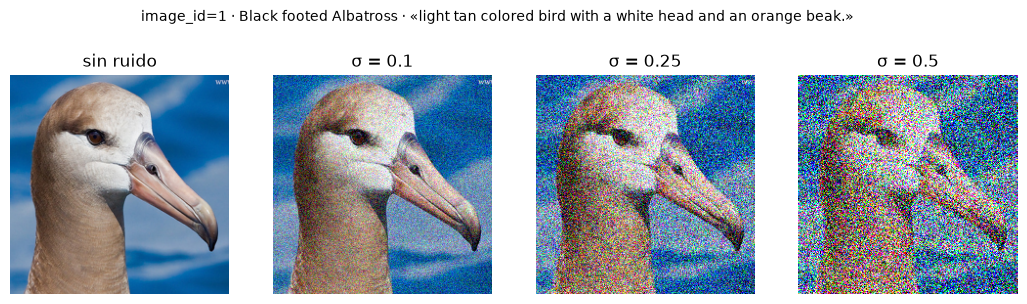

In [11]:
def load_crop(row_idx, sigma_index=None):
    r = image_table.iloc[row_idx]
    with Image.open(CUB_DIR / "images" / r["image_path"]) as src:
        x = eval_image_transform_unnormalized(crop_with_margin(src.convert("RGB"), r["bbox_x"], r["bbox_y"], r["bbox_w"], r["bbox_h"]))
    if sigma_index is not None:
        x = pixel_noise(x[None], torch.tensor([int(r["image_id"])]), sigma_index, NOISE_SIGMAS[sigma_index])[0]
    return x.permute(1, 2, 0).numpy()

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

demo_row = int(test_rows[0])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for k, ax in enumerate(axes):
    ax.imshow(load_crop(demo_row, None if k == 0 else k - 1)); ax.axis("off")
    ax.set_title("sin ruido" if k == 0 else f"σ = {NOISE_SIGMAS[k-1]}")
r = image_table.iloc[demo_row]
fig.suptitle(f"image_id={r.image_id} · {CLASS_NAMES[r.label]} · «{r.captions[0]}»", fontsize=10)
save_fig(fig, "03_ruido_pixeles_ejemplo"); plt.show()

**Interpretación de resultados (embeddings).** Los cuatro archivos de la caché superaron todas las comprobaciones (identificadores, forma, valores finitos y huella SHA-256). Por eso ningún modelo de este notebook recalcula la ResNet50: el embedding limpio de las 11.788 imágenes y los tres embeddings de test con ruido son **idénticos** para todos los experimentos.

La tabla muestra que el ruido gaussiano en los píxeles desplaza mucho la representación. La similitud coseno media entre el embedding limpio y el ruidoso de una misma imagen es **0,752** con σ = 0,1, **0,431** con σ = 0,25 y solo **0,124** con σ = 0,5. A la vez, la norma L2 media crece de 8,65 a 10,15, 12,59 y 12,89. Esto es coherente con lo que se sabe de las CNN entrenadas en ImageNet sin aumentos de ruido (Hendrycks & Dietterich, 2019): el ruido de alta frecuencia activa canales de textura que, tras la ReLU y el *global average pooling*, inflan la norma y «empujan» el vector fuera de la región de las imágenes limpias. Aunque con σ = 0,1 el ave sigue siendo reconocible a simple vista (figura anterior), el embedding ya ha perdido una cuarta parte de su alineación. Por eso la sección 7.3 espera caídas fuertes en todo modelo que dependa de la imagen.

---
# 4. Datos comunes de las partes 1–3 (protocolo de clasificación supervisada)

Las partes 1–3 usan la partición de la Tarea 1 (**5.394 train / 600 val / 5.794 test**, con las 200 especies en todas las particiones) y el vocabulario de la Tarea 1. Para cada partición se reúnen, **por la misma fila de la tabla maestra** (es decir, por `image_id`):

- `image`: el embedding ResNet50 (2048), tomado de la caché por `image_id`;
- `caption`: los ids de una de las 10 captions (25 posiciones). En entrenamiento se sortea una caption distinta en cada época; en validación y prueba siempre se usa la caption 0, como en la Tarea 1;
- `tabular`: el vector de 318 características;
- `y`: la especie (0…199).

**Política de selección de modelos.** Todas las decisiones (*early stopping*, mejor época, pesos de *late fusion*, regla de fusión) se toman **solo con validación**. El test se usa una única vez, para reportar.

In [12]:
ID2ROW = {int(i): k for k, i in enumerate(IMAGE_IDS)}
assert all(IMAGE_IDS[ID2ROW[i]] == i for i in IMAGE_IDS[:100])

DATA = {}
for s, rows in SPLIT_ROWS.items():
    DATA[s] = dict(rows=rows, image=EMB[rows], caps=CAPTION_IDS[rows], lens=CAPTION_LENS[rows],
                   tabular=TABULAR[rows], y=LABELS[rows], ids=IMAGE_IDS[rows])
    assert np.array_equal(DATA[s]["ids"], image_table["image_id"].to_numpy()[rows])
    print(f"{s:5s}: {len(rows):5d} imágenes · {len(np.unique(DATA[s]['y']))} especies · image{DATA[s]['image'].shape} "
          f"caption{DATA[s]['caps'].shape} tabular{DATA[s]['tabular'].shape}")
assert len(set(DATA["train"]["ids"]) & set(DATA["val"]["ids"])) == 0
assert len(set(DATA["train"]["ids"]) & set(DATA["test"]["ids"])) == 0
assert len(set(DATA["val"]["ids"]) & set(DATA["test"]["ids"])) == 0

class CUBSequence(keras.utils.PyDataset):
    # Lotes por diccionario de modalidades. En entrenamiento: barajado y caption aleatoria NUEVA en cada época.
    def __init__(self, split, keys, batch_size=64, training=False, caption_override=None, image_override=None, seed=SEED, **kw):
        super().__init__(**kw)
        d = DATA[split]; self.keys, self.bs, self.training = keys, batch_size, training
        self.image = d["image"] if image_override is None else image_override
        self.caps, self.tab, self.y = d["caps"], d["tabular"], d["y"]
        self.caption_override = caption_override        # (N, L) ids ya elegidos (robustez)
        self.rng = np.random.default_rng(seed); self.n = len(self.y)
        self.on_epoch_end()
    def __len__(self):
        return math.ceil(self.n / self.bs)
    def on_epoch_end(self):
        self.order = self.rng.permutation(self.n) if self.training else np.arange(self.n)
        self.cap_idx = self.rng.integers(0, 10, self.n) if self.training else np.zeros(self.n, int)
    def __getitem__(self, i):
        idx = self.order[i * self.bs:(i + 1) * self.bs]
        x = {}
        if "image" in self.keys: x["image"] = self.image[idx]
        if "tabular" in self.keys: x["tabular"] = self.tab[idx]
        if "caption" in self.keys:
            x["caption"] = (self.caption_override[idx] if self.caption_override is not None
                            else self.caps[idx, self.cap_idx[idx]])
        return x, self.y[idx]

NUM_CLASSES, VOCAB_SIZE, MAX_LEN = 200, len(vocab), max_len
EPOCH_CAP = 2 if QUICK_TEST else None

train:  5394 imágenes · 200 especies · image(5394, 2048) caption(5394, 10, 25) tabular(5394, 318)
val  :   600 imágenes · 200 especies · image(600, 2048) caption(600, 10, 25) tabular(600, 318)
test :  5794 imágenes · 200 especies · image(5794, 2048) caption(5794, 10, 25) tabular(5794, 318)


## 4.1 Funciones comunes: entrenamiento con *checkpoints*, métricas y confusiones

**Entrenamiento.** Se usa Adam con entropía cruzada categórica sobre *logits*:

$$\mathcal{L}_{CE} = -\frac{1}{B}\sum_{b=1}^{B}\log\frac{\exp(s_{b,y_b})}{\sum_{c=1}^{200}\exp(s_{b,c})},$$

donde $s_{b,c}$ es el *logit* de la clase $c$ para el ejemplo $b$. Los *callbacks* son:

- `ModelCheckpoint`: guarda el mejor modelo según la pérdida de validación;
- `EarlyStopping`: paciencia fija y restauración de los mejores pesos;
- `TerminateOnNaN`: detiene el entrenamiento si aparecen valores no numéricos;
- `CSVLogger`: guarda el historial.

Si existe un *checkpoint* y `FORCE_RETRAIN=False`, el modelo y su historial se recuperan del disco, sin volver a entrenar.

**Métricas** (sobre probabilidades $\hat{p}_{n,c}$ normalizadas en float64, con columnas en el orden 0…199):

- **Accuracy top-1**: $\frac1N\sum_n \mathbb{1}[\arg\max_c \hat p_{n,c}=y_n]$. **Top-5**: la especie correcta está entre las 5 de mayor probabilidad.
- **F1-macro**: promedio no ponderado del F1 de las 200 especies; penaliza por igual los errores en especies raras.
- **ROC-AUC macro (uno contra el resto)**: para cada especie $c$, el AUC de separar «$c$» de «no $c$» usando la columna $\hat p_{\cdot,c}$; luego se promedia sobre las 200 especies (`roc_auc_score(..., multi_class="ovr", average="macro", labels=0…199)`). Mide la calidad del ordenamiento de las probabilidades, no solo del argmax.

**Pares más confundidos.** Con la matriz de confusión $C$ (filas = verdad, columnas = predicción), cada par no ordenado $\{a,b\}$ recibe el puntaje $C_{ab}+C_{ba}$. Se reportan los 10 pares con mayor puntaje.

In [13]:
class EpochPrinter(keras.callbacks.Callback):
    def __init__(self, every=5): super().__init__(); self.every = every; self.t0 = None
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0 or epoch == 0:
            print(f"  época {epoch+1:3d} | loss {logs['loss']:.3f} acc {logs['accuracy']:.3f} | "
                  f"val_loss {logs['val_loss']:.3f} val_acc {logs['val_accuracy']:.3f} | {time.time()-self.t0:.0f}s")

def train_keras(name, build_fn, keys, epochs, patience, lr, batch_size=64):
    ck_dir = CKPT_DIR / name; ck_dir.mkdir(parents=True, exist_ok=True)
    ckpt, hist_path = ck_dir / "best.keras", HIST_DIR / f"{name}.json"
    epochs = EPOCH_CAP or epochs
    if ckpt.is_file() and hist_path.is_file() and not FORCE_RETRAIN:
        log(f"✓ {name}: checkpoint recuperado (no se reentrena)")
        return keras.models.load_model(ckpt), json.loads(hist_path.read_text())
    set_all_seeds(SEED)
    model = build_fn()
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
    tr = CUBSequence("train", keys, batch_size, training=True)
    va = CUBSequence("val", keys, 256)
    cbs = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True),
           keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.TerminateOnNaN(), keras.callbacks.CSVLogger(ck_dir / "log.csv"), EpochPrinter()]
    log(f"▶ Entrenando {name}: máx. {epochs} épocas, lr={lr}, batch={batch_size}, paciencia={patience}")
    t0 = time.time()
    h = model.fit(tr, validation_data=va, epochs=epochs, callbacks=cbs, verbose=0)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    if any(not np.isfinite(v) for v in hist["loss"]):
        raise FloatingPointError(f"{name}: pérdida no finita")
    best = int(np.argmin(hist["val_loss"]))
    hist["_meta"] = {"epochs_run": len(hist["loss"]), "best_epoch": best + 1, "train_seconds": time.time() - t0,
                     "lr": lr, "batch_size": batch_size, "patience": patience, "max_epochs": epochs,
                     "params": int(model.count_params())}
    hist_path.write_text(json.dumps(hist, indent=2))
    log(f"✓ {name}: {hist['_meta']['epochs_run']} épocas, mejor={best+1}, {hist['_meta']['train_seconds']:.0f}s")
    return keras.models.load_model(ckpt), hist

def softmax64(logits):
    z = logits.astype(np.float64); z -= z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def predict_proba(model, split, keys, **kw):
    return softmax64(model.predict(CUBSequence(split, keys, 512, **kw), verbose=0))

def topk_acc(y, P, k):
    return float(np.mean((np.argsort(-P, 1)[:, :k] == y[:, None]).any(1)))

def clf_metrics(y, P):
    assert P.shape[1] == NUM_CLASSES and np.allclose(P.sum(1), 1.0)
    pred = P.argmax(1)
    return {"accuracy": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro"),
            "roc_auc_macro": roc_auc_score(y, P, multi_class="ovr", average="macro", labels=np.arange(NUM_CLASSES)),
            "top1": topk_acc(y, P, 1), "top5": topk_acc(y, P, 5)}

def top_confusions(y, pred, k=10):
    C = confusion_matrix(y, pred, labels=np.arange(NUM_CLASSES))
    S = C + C.T; np.fill_diagonal(S, 0)
    iu = np.triu_indices(NUM_CLASSES, 1)
    order = np.argsort(-S[iu], kind="stable")[:k]
    rows = []
    for o in order:
        a, b = iu[0][o], iu[1][o]
        rows.append({"especie A": CLASS_NAMES[a], "especie B": CLASS_NAMES[b], "A→B": int(C[a, b]),
                     "B→A": int(C[b, a]), "total": int(S[a, b]), "a": int(a), "b": int(b)})
    return pd.DataFrame(rows, index=range(1, k + 1))

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=float), encoding="utf-8")

EXPERIMENTS = {}   # configuración por experimento (se guarda al final)

---
# 5. Parte 1 — Modelos unimodales

**Pregunta:** ¿cuánto rinde cada modalidad por separado?

## 5.1 Arquitecturas

| Modelo | Arquitectura | Origen |
|---|---|---|
| **Imagen** | `emb ResNet50 (2048) → Dense(512, ReLU) → Dropout(0.5) → Dense(200)` | Especificación del enunciado. |
| **Texto** | `Embedding(V = 2.079, 128, mask_zero=True) → LSTM(256) → Dense(200)` | Especificación del enunciado. La máscara hace que el LSTM ignore las posiciones `<pad>=0`; su estado final corresponde al último token válido, es decir, a la longitud real de la caption. |
| **Atributos** | `318 → Dense(512) → BatchNorm → ReLU → Dropout(0.3) → Dense(256, ReLU) → Dropout(0.3) → Dense(200)` | **Propuesta nuestra.** El enunciado pide el clasificador, pero no fija su arquitectura. |

**Justificación de la red de atributos.** El vector tiene 312 variables binarias (muy correlacionadas: por ejemplo, «color primario» y «color de las alas») y 6 continuas estandarizadas. Una MLP de dos capas ocultas puede modelar interacciones entre atributos (por ejemplo, «pico corto» **y** «pecho amarillo»). `BatchNorm` estabiliza la escala de entrada, que mezcla variables binarias y continuas, y el *dropout* moderado limita el sobreajuste con unas 27 imágenes por especie.

**Hiperparámetros** (todos documentados y fijos, sin ajuste con test):

| Modelo | lr (Adam) | batch | épocas máx. | paciencia (val_loss) | Razón |
|---|---|---|---|---|---|
| Imagen | 1e-3 | 64 | 100 | 10 | Cabeza lineal sobre *features* fijas; converge en pocas épocas. |
| Texto | 1e-3 | 64 | 80 | 10 | El LSTM aprende desde cero y la caption de entrenamiento cambia en cada época (más ruido), así que necesita más épocas. |
| Atributos | 1e-3 | 64 | 100 | 10 | MLP pequeña. |

In [14]:
def build_image_model(dropout=0.5):
    inp = keras.Input((2048,), name="image")
    x = layers.Dense(512, activation="relu")(inp)
    x = layers.Dropout(dropout)(x)
    return keras.Model({"image": inp}, layers.Dense(NUM_CLASSES, name="logits")(x), name="unimodal_image")

def text_encoder(inp, emb_dim=128, units=256):
    x = layers.Embedding(VOCAB_SIZE, emb_dim, mask_zero=True, name="word_embedding")(inp)
    return layers.LSTM(units, name="lstm")(x)

def build_text_model():
    inp = keras.Input((MAX_LEN,), dtype="int32", name="caption")
    return keras.Model({"caption": inp}, layers.Dense(NUM_CLASSES, name="logits")(text_encoder(inp)), name="unimodal_text")

def build_attr_model():
    inp = keras.Input((318,), name="tabular")
    x = layers.Dense(512)(inp); x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x); x = layers.Dropout(0.3)(x)
    return keras.Model({"tabular": inp}, layers.Dense(NUM_CLASSES, name="logits")(x), name="unimodal_attributes")

UNI = {
    "imagen":    dict(build=build_image_model, keys=["image"], epochs=100, patience=10, lr=1e-3),
    "texto":     dict(build=build_text_model, keys=["caption"], epochs=80, patience=10, lr=1e-3),
    "atributos": dict(build=build_attr_model, keys=["tabular"], epochs=100, patience=10, lr=1e-3),
}
for k, cfg in UNI.items():
    m = cfg["build"](); print(f"{m.name}: {m.count_params():,} parámetros")
m.summary()

unimodal_image: 1,151,688 parámetros
unimodal_text: 711,752 parámetros
unimodal_attributes: 348,104 parámetros


Model: "unimodal_attributes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tabular (InputLayer)            │ (None, 318)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       163,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 200)            │        51,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,104 (1.33 MB)

 Trainable params: 347,080 (1.32 MB)

 Non-trainable params: 1,024 (4.00 KB)

## 5.2 Entrenamiento

Cada modelo se entrena por separado con la misma semilla. Se imprime una línea cada 5 épocas. Al terminar, el mejor modelo según `val_loss` queda en `checkpoints/<modelo>/best.keras` y su historial en `results/histories/<modelo>.json`.

In [15]:
MODELS, HISTS = {}, {}
for name, cfg in UNI.items():
    MODELS[name], HISTS[name] = train_keras(f"p1_{name}", cfg["build"], cfg["keys"], cfg["epochs"], cfg["patience"], cfg["lr"])
    EXPERIMENTS[f"p1_{name}"] = {k: v for k, v in cfg.items() if k != "build"} | {"framework": "TensorFlow/Keras"} | HISTS[name]["_meta"]
pd.DataFrame({n: h["_meta"] for n, h in HISTS.items()}).T

✓ p1_imagen: checkpoint recuperado (no se reentrena)
✓ p1_texto: checkpoint recuperado (no se reentrena)


✓ p1_atributos: checkpoint recuperado (no se reentrena)


,epochs_run,best_epoch,train_seconds,lr,batch_size,patience,max_epochs,params
imagen,26.0,16.0,19.452564,0.001,64.0,10.0,100.0,1151688.0
texto,69.0,59.0,74.435819,0.001,64.0,10.0,80.0,711752.0
atributos,19.0,9.0,19.297840,0.001,64.0,10.0,100.0,348104.0


## 5.3 Curvas de entrenamiento y validación

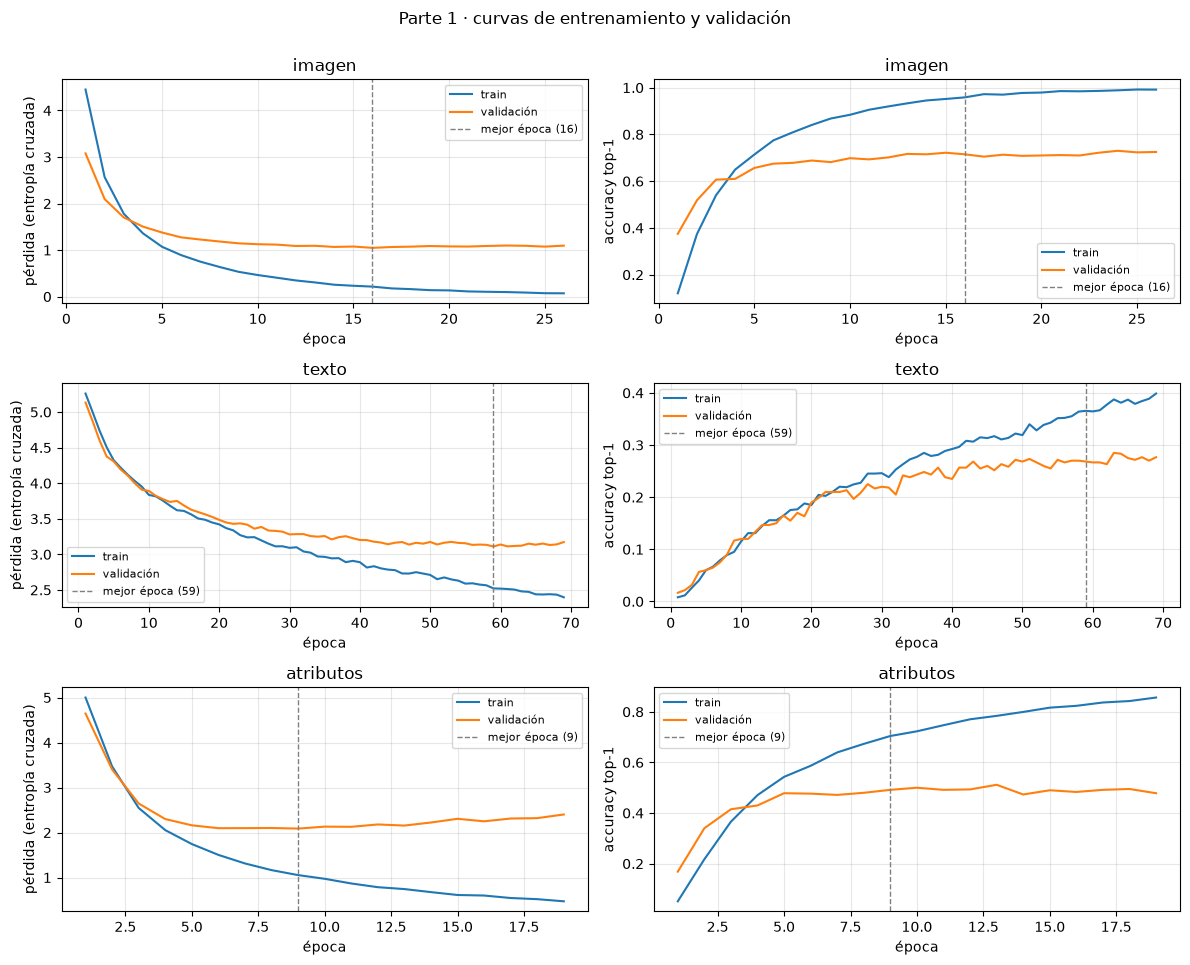

In [16]:
def plot_histories(hists, title, fname):
    fig, axes = plt.subplots(len(hists), 2, figsize=(12, 3.2 * len(hists)), squeeze=False)
    for (name, h), (a1, a2) in zip(hists.items(), axes):
        ep = np.arange(1, len(h["loss"]) + 1); best = h["_meta"]["best_epoch"]
        a1.plot(ep, h["loss"], label="train"); a1.plot(ep, h["val_loss"], label="validación")
        a2.plot(ep, h["accuracy"], label="train"); a2.plot(ep, h["val_accuracy"], label="validación")
        for a, ylabel in [(a1, "pérdida (entropía cruzada)"), (a2, "accuracy top-1")]:
            a.axvline(best, color="gray", ls="--", lw=1, label=f"mejor época ({best})")
            a.set_xlabel("época"); a.set_ylabel(ylabel); a.set_title(f"{name}"); a.legend(fontsize=8)
    fig.suptitle(title, y=1.0); fig.tight_layout(); save_fig(fig, fname); plt.show()

plot_histories(HISTS, "Parte 1 · curvas de entrenamiento y validación", "p1_curvas")

## 5.4 Métricas en test y análisis de sobreajuste

Las métricas de **train** se calculan en modo evaluación (sin *dropout*, con la caption 0), sobre las mismas 5.394 imágenes. La **brecha train − validación** indica sobreajuste.

In [17]:
PROBA = {name: {} for name in UNI}
for name, cfg in UNI.items():
    for s in ["train", "val", "test"]:
        PROBA[name][s] = predict_proba(MODELS[name], s, cfg["keys"])

METRICS = {}
rows = []
for name in UNI:
    METRICS[name] = {s: clf_metrics(DATA[s]["y"], PROBA[name][s]) for s in ["train", "val", "test"]}
    save_json(METRICS[name], MET_DIR / f"p1_{name}.json")
    t = METRICS[name]["test"]
    rows.append({"modelo": name, "accuracy": t["accuracy"], "F1-macro": t["f1_macro"], "ROC-AUC macro": t["roc_auc_macro"],
                 "top-1": t["top1"], "top-5": t["top5"]})
p1_table = pd.DataFrame(rows).set_index("modelo")
p1_table.to_csv(TAB_DIR / "p1_metricas_test.csv")
print("Métricas en TEST (5.794 imágenes, 200 especies):")
display(p1_table.style.format("{:.4f}").set_caption("Parte 1 · test"))

gap = pd.DataFrame({name: {"acc train": METRICS[name]["train"]["accuracy"], "acc val": METRICS[name]["val"]["accuracy"],
                           "acc test": METRICS[name]["test"]["accuracy"],
                           "brecha train−val": METRICS[name]["train"]["accuracy"] - METRICS[name]["val"]["accuracy"],
                           "mejor época": HISTS[name]["_meta"]["best_epoch"], "épocas": HISTS[name]["_meta"]["epochs_run"]}
                    for name in UNI}).T
gap.to_csv(TAB_DIR / "p1_sobreajuste.csv")
display(gap.style.format({c: "{:.4f}" for c in gap.columns if "acc" in c or "brecha" in c}).set_caption("Sobreajuste"))

Métricas en TEST (5.794 imágenes, 200 especies):


,accuracy,F1-macro,ROC-AUC macro,top-1,top-5
modelo,,,,,
imagen,0.7304,0.7311,0.9953,0.7304,0.9427
texto,0.2520,0.2429,0.9380,0.2520,0.5369
atributos,0.4743,0.4672,0.9737,0.4743,0.7570


,acc train,acc val,acc test,brecha train−val,mejor época,épocas
imagen,0.9965,0.7150,0.7304,0.2815,16.000000,26.000000
texto,0.4277,0.2683,0.2520,0.1594,59.000000,69.000000
atributos,0.9145,0.4917,0.4743,0.4229,9.000000,19.000000


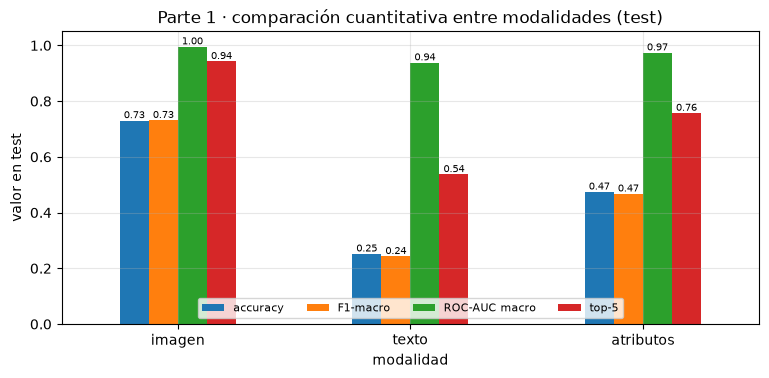

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
p1_table[["accuracy", "F1-macro", "ROC-AUC macro", "top-5"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("valor en test"); ax.set_xlabel("modalidad")
ax.set_title("Parte 1 · comparación cuantitativa entre modalidades (test)"); ax.legend(ncol=4, fontsize=8, loc="lower center")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
save_fig(fig, "p1_comparacion_modalidades"); plt.show()

**Interpretación de resultados (Parte 1, métricas).**

*¿Qué modalidad rinde mejor por sí sola?* La **imagen**, con diferencia: 73,04 % de top-1, F1-macro de 0,731 y 94,27 % de top-5 en test. Le siguen los **atributos** (47,43 % de top-1; F1 0,467; top-5 75,70 %) y el **texto** (25,20 % de top-1; F1 0,243; top-5 53,69 %). Las tres superan con creces el azar (0,5 %). El F1-macro casi coincide con la accuracy en los tres casos, así que el rendimiento no depende de unas pocas especies muy frecuentes: el test está aproximadamente equilibrado.

*¿Por qué?* (i) El embedding de imagen procede de una ResNet50 preentrenada con 1,28 millones de imágenes y conserva toda la evidencia visual fina (forma del pico, patrón de plumaje, proporciones). (ii) Los 312 atributos son una descripción visual **resumida y ruidosa**: los anotan voluntarios por imagen, son binarios y no recogen la textura ni la geometría finas. (iii) Una sola caption (en test se usa siempre la caption 0) es una descripción **parcial** de unas 15 palabras, escrita sin nombrar la especie y centrada en colores. Muchas especies comparten descripciones casi idénticas («a small brown bird with white belly»). Además, el LSTM se entrena desde cero con 5.394 imágenes. La accuracy de **entrenamiento** del modelo de texto es solo del 42,8 %: más que sobreajuste, el texto tiene un **techo de información** cuando se usa una única caption.

*Sobreajuste.* La brecha train−val es de 28,1 pp para la imagen (99,6 % frente a 71,5 %), de 42,3 pp para los atributos (91,5 % frente a 49,2 %) y de 15,9 pp para el texto. Con unas 27 imágenes por especie en entrenamiento, las cabezas densas memorizan; el *early stopping* sobre `val_loss` detuvo el entrenamiento en las épocas 16, 9 y 59, respectivamente. Las curvas muestran que, a partir de esas épocas, la pérdida de validación deja de mejorar mientras la de entrenamiento sigue bajando.

*ROC-AUC frente a accuracy.* El ROC-AUC macro es muy alto incluso para el texto (0,938), frente a 0,974 para los atributos y 0,995 para la imagen. Con 200 clases, el AUC uno-contra-resto mide si la especie correcta queda por encima de la **mayoría** de las 199 incorrectas. Un modelo que sitúa la especie correcta en la mitad superior del ranking obtiene un AUC alto aunque casi nunca la ponga primera. En un problema de grano fino con muchas clases, el AUC discrimina poco entre modelos. La accuracy top-1 y el F1-macro son las métricas informativas, y el top-5 es útil para ver cuán cerca queda el acierto.

## 5.5 Las 10 parejas de especies más confundidas por modelo

In [19]:
CONF = {}
for name in UNI:
    CONF[name] = top_confusions(DATA["test"]["y"], PROBA[name]["test"].argmax(1))
    CONF[name].to_csv(TAB_DIR / f"p1_confusiones_{name}.csv")
    print(f"\n=== {name.upper()} ===")
    display(CONF[name].drop(columns=["a", "b"]))

pairs = {n: {frozenset((r.a, r.b)) for r in CONF[n].itertuples()} for n in UNI}
overlap = pd.DataFrame([[len(pairs[a] & pairs[b]) for b in UNI] for a in UNI], index=list(UNI), columns=list(UNI))
print("Número de parejas compartidas entre los top-10 de cada modelo:"); display(overlap)

# Coincidencia de errores, imagen por imagen, en test
yt = DATA["test"]["y"]; pi, pt = PROBA["imagen"]["test"].argmax(1), PROBA["texto"]["test"].argmax(1)
both_wrong = (pi != yt) & (pt != yt)
same_wrong = both_wrong & (pi == pt)
err_stats = {"errores imagen": int((pi != yt).sum()), "errores texto": int((pt != yt).sum()),
             "ambos fallan": int(both_wrong.sum()), "ambos fallan hacia la MISMA especie": int(same_wrong.sum()),
             "P(texto falla | imagen falla)": float(both_wrong.sum() / max(1, (pi != yt).sum())),
             "P(texto falla) global": float((pt != yt).mean())}
save_json(err_stats, MET_DIR / "p1_errores_imagen_vs_texto.json")
display(pd.Series(err_stats, name="test").to_frame())


=== IMAGEN ===


,especie A,especie B,A→B,B→A,total
1,Ruby throated Hummingbird,Rufous Hummingbird,15,5,20
2,Artic Tern,Common Tern,7,10,17
3,Caspian Tern,Elegant Tern,3,14,17
4,Brandt Cormorant,Pelagic Cormorant,3,13,16
5,American Crow,Common Raven,8,8,16
6,Common Tern,Forsters Tern,6,10,16
7,Northern Waterthrush,Louisiana Waterthrush,3,11,14
8,California Gull,Ring billed Gull,8,5,13
9,Anna Hummingbird,Ruby throated Hummingbird,9,4,13
10,Loggerhead Shrike,Great Grey Shrike,8,5,13



=== TEXTO ===


,especie A,especie B,A→B,B→A,total
1,American Crow,Common Raven,10,6,16
2,Fish Crow,Common Raven,11,4,15
3,Eared Grebe,Horned Grebe,6,8,14
4,Loggerhead Shrike,Great Grey Shrike,5,8,13
5,Brandt Cormorant,Pelagic Cormorant,3,7,10
6,Ruby throated Hummingbird,Rufous Hummingbird,7,3,10
7,Mourning Warbler,Nashville Warbler,3,7,10
8,Groove billed Ani,Shiny Cowbird,3,6,9
9,Yellow breasted Chat,Tropical Kingbird,4,5,9
10,Vermilion Flycatcher,Pine Grosbeak,4,5,9



=== ATRIBUTOS ===


,especie A,especie B,A→B,B→A,total
1,American Crow,Fish Crow,8,16,24
2,Caspian Tern,Elegant Tern,18,4,22
3,Anna Hummingbird,Ruby throated Hummingbird,5,13,18
4,Northern Waterthrush,Louisiana Waterthrush,7,9,16
5,Brandt Cormorant,Pelagic Cormorant,7,8,15
6,Blue Jay,Florida Jay,1,14,15
7,Loggerhead Shrike,Great Grey Shrike,4,11,15
8,American Crow,Common Raven,1,11,12
9,Artic Tern,Common Tern,5,7,12
10,Indigo Bunting,Blue Grosbeak,3,8,11


Número de parejas compartidas entre los top-10 de cada modelo:


,imagen,texto,atributos
imagen,10,4,7
texto,4,10,3
atributos,7,3,10


,test
errores imagen,1562.000000
errores texto,4334.000000
ambos fallan,1348.000000
ambos fallan hacia la MISMA especie,94.000000
P(texto falla | imagen falla),0.862996
P(texto falla) global,0.748015


## 5.6 Ejemplos reales de confusión: imagen frente a texto

Se eligen de forma **determinista** tres ejemplos de test:

1. el primer ejemplo de la pareja más confundida por la **imagen**;
2. el primer ejemplo de la pareja más confundida por el **texto**;
3. un ejemplo en el que **ambos** modelos fallan hacia la misma especie, si existe.

Para cada uno se muestran el recorte que vio ResNet50, la caption 0 (la que vio el modelo de texto) y las predicciones de los dos modelos.

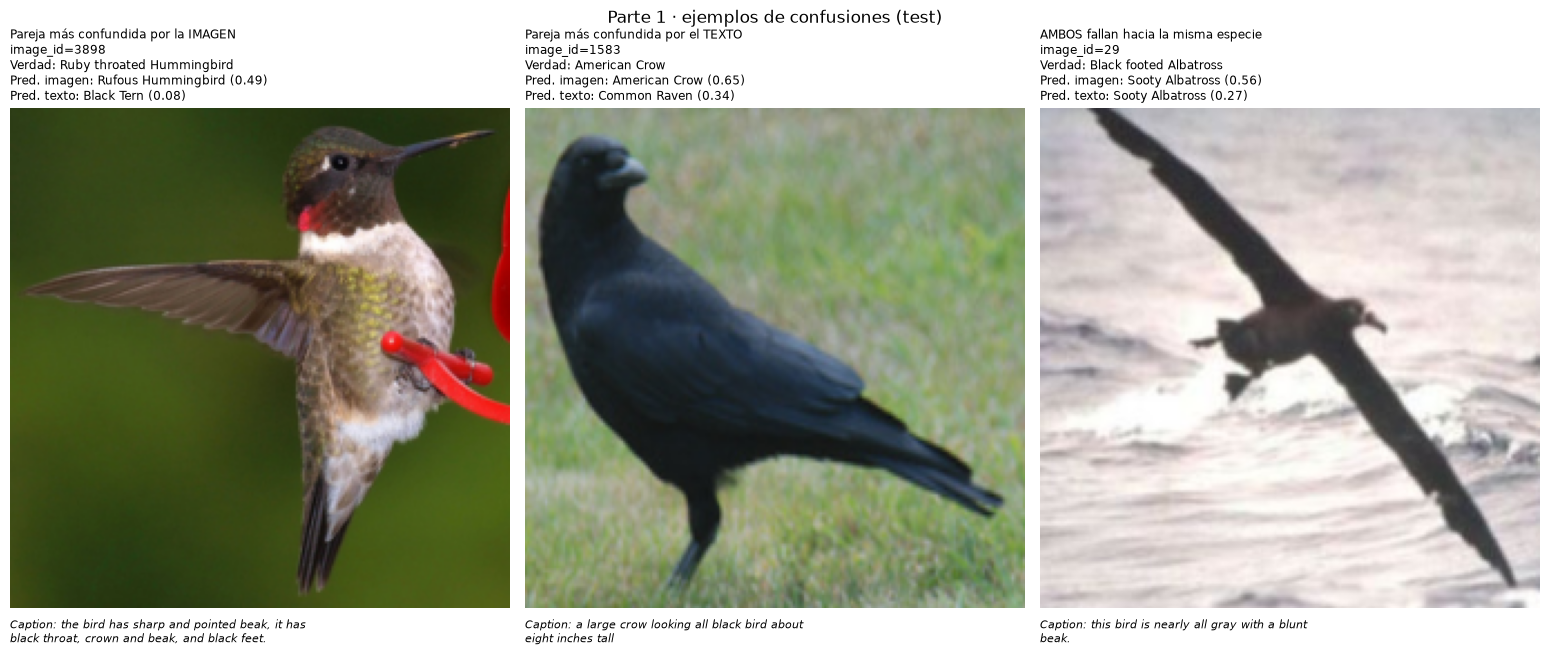

,motivo,image_id,verdad,pred_imagen,pred_texto,caption
0,Pareja más confundida por la IMAGEN,3898,Ruby throated Hummingbird,Rufous Hummingbird,Black Tern,"the bird has sharp and pointed beak, it has bl..."
1,Pareja más confundida por el TEXTO,1583,American Crow,American Crow,Common Raven,a large crow looking all black bird about eigh...
2,AMBOS fallan hacia la misma especie,29,Black footed Albatross,Sooty Albatross,Sooty Albatross,this bird is nearly all gray with a blunt beak.


In [20]:
import textwrap
def first_example(model_pred, a, b):
    idx = np.flatnonzero(((yt == a) & (model_pred == b)) | ((yt == b) & (model_pred == a)))
    return int(idx[0]) if len(idx) else None

examples = []
r0 = CONF["imagen"].iloc[0]; e = first_example(pi, r0.a, r0.b)
if e is not None: examples.append((e, "Pareja más confundida por la IMAGEN"))
r1 = CONF["texto"].iloc[0]; e = first_example(pt, r1.a, r1.b)
if e is not None: examples.append((e, "Pareja más confundida por el TEXTO"))
sw = np.flatnonzero(same_wrong)
if len(sw): examples.append((int(sw[0]), "AMBOS fallan hacia la misma especie"))

fig, axes = plt.subplots(1, len(examples), figsize=(5.2 * len(examples), 6.2), squeeze=False)
ex_rows = []
for ax, (k, why) in zip(axes[0], examples):
    row = int(DATA["test"]["rows"][k]); r = image_table.iloc[row]
    ax.imshow(load_crop(row)); ax.axis("off")
    txt = (f"{why}\nimage_id={r.image_id}\nVerdad: {CLASS_NAMES[yt[k]]}\n"
           f"Pred. imagen: {CLASS_NAMES[pi[k]]} ({PROBA['imagen']['test'][k, pi[k]]:.2f})\n"
           f"Pred. texto: {CLASS_NAMES[pt[k]]} ({PROBA['texto']['test'][k, pt[k]]:.2f})")
    ax.set_title(txt, fontsize=8.5, loc="left")
    ax.text(0, -0.02, "\n".join(textwrap.wrap("Caption: " + r.captions[0], 55)), transform=ax.transAxes,
            fontsize=8, va="top", ha="left", style="italic")
    ex_rows.append({"motivo": why, "image_id": int(r.image_id), "verdad": CLASS_NAMES[yt[k]],
                    "pred_imagen": CLASS_NAMES[pi[k]], "pred_texto": CLASS_NAMES[pt[k]], "caption": r.captions[0]})
fig.suptitle("Parte 1 · ejemplos de confusiones (test)", y=1.02); fig.tight_layout()
save_fig(fig, "p1_ejemplos_confusiones"); plt.show()
pd.DataFrame(ex_rows).to_csv(TAB_DIR / "p1_ejemplos_confusiones.csv", index=False)
display(pd.DataFrame(ex_rows))

**Interpretación de resultados (Parte 1, confusiones).**

*¿Las especies que confunde la imagen son las mismas que confunde el texto?* **Solo en parte.** De las 10 parejas más confundidas por cada modelo, **4 son comunes**: colibrí garganta rubí / colibrí rufo, cormorán de Brandt / cormorán pelágico, cuervo americano / cuervo grande y alcaudón americano / alcaudón norteño. Son pares de especies hermanas que difieren en detalles que ni la foto recortada ni una frase corta resuelven bien.

El resto revela un sesgo distinto en cada modalidad:

- **Imagen:** confunde especies del **mismo género y aspecto casi idéntico**: charranes (ártico/común, caspio/elegante, común/de Forster), gaviotas (californiana/de Delaware) y los dos *Parkesia* (*waterthrush*). Las diferencias son de color del pico, proporciones o voz, y apenas visibles en la foto.
- **Texto:** confunde especies **visualmente distintas pero descritas con el mismo vocabulario de color**: *Yellow-breasted Chat* / *Tropical Kingbird* (ambos «amarillos»), *Vermilion Flycatcher* / *Pine Grosbeak* (ambos «rojos») y *Groove-billed Ani* / *Shiny Cowbird* (ambos «negros»). Pertenecen a familias diferentes y un modelo visual no los confunde.

El análisis imagen por imagen lo confirma. El texto falla en 4.334 imágenes de test y la imagen en 1.562; ambos fallan a la vez en 1.348. Los errores están **correlacionados**: P(texto falla | imagen falla) = 0,863, frente a 0,748 en general, porque las fotos difíciles suelen ser de especies difíciles. Pero solo **94** de esos 1.348 fallos conjuntos (7 %) apuntan a **la misma especie equivocada**. Los modelos se equivocan juntos, pero casi nunca de la misma forma, y esta complementariedad es lo que explota la *late fusion* de la Parte 3.

Los tres ejemplos de la figura lo ilustran:

1. Un colibrí garganta rubí (id 3898) que la imagen toma por colibrí rufo. La caption («pointed beak, black throat, crown and beak, black feet») lleva al texto hacia un charrán negro.
2. Un cuervo americano (id 1583) que la imagen acierta. La caption «a large crow looking all black bird» lleva al texto hacia el cuervo grande (*Common Raven*).
3. Un albatros de patas negras (id 29) que ambos modelos confunden con el albatros oscuro (*Sooty Albatross*): «nearly all gray with a blunt beak» describe bien a los dos.

### Preguntas conceptuales de la Parte 1

**¿Qué modalidad rinde mejor por sí sola y por qué creen que ocurre?** La imagen (73,04 % de top-1 en test), seguida de los atributos (47,43 %) y el texto (25,20 %). La imagen gana porque el embedding de una ResNet50 preentrenada conserva casi toda la evidencia visual fina que distingue especies de grano fino. Los atributos son una versión humana, binaria y ruidosa de parte de esa evidencia. Una sola caption es una descripción parcial, centrada en colores y compartida por muchas especies: incluso en entrenamiento el modelo de texto solo alcanza el 42,8 %. Los detalles están en la interpretación de las métricas de la Parte 1.

**¿Las especies que confunde la imagen son las mismas que confunde el texto?** Parcialmente. Cuatro de las diez parejas más confundidas coinciden (colibríes garganta rubí/rufo, cormoranes de Brandt/pelágico, cuervo americano/cuervo grande y alcaudones), pero el patrón general difiere. La imagen confunde especies hermanas casi idénticas (charranes, gaviotas, *waterthrushes*). El texto confunde especies de familias distintas que comparten el color dominante (*Yellow-breasted Chat* / *Tropical Kingbird*, *Vermilion Flycatcher* / *Pine Grosbeak*). Solo 94 de los 1.348 fallos simultáneos (7 %) apuntan a la misma especie equivocada. Los tres ejemplos, con su fotografía y su caption, están en la figura anterior.

---
# 6. Parte 2 — Early fusion (fusión de representaciones)

**Pregunta:** ¿mejora un único modelo que ve todo a la vez?

**Sobre el nombre.** En sentido estricto, *early fusion* concatena las **entradas crudas**. Una fotografía y una secuencia de palabras no se pueden concatenar directamente, así que, como indica el enunciado, la fusión se realiza al nivel de ***features*** (en la literatura, *intermediate fusion*): cada modalidad pasa por su propia rama, sus representaciones se concatenan y una única cabeza clasifica.

```text
embedding de imagen (2048) ──► Dense(512, ReLU) ─────────────┐
caption ──► Embedding(128, máscara) ──► LSTM(256) ───────────┤──► concat (896) ──► Dropout(0.5) ──► Dense(512, ReLU) ──► Dropout(0.5) ──► Dense(200)
atributos (318) ──► Dense(128, ReLU) ────────────────────────┘
```

- **Una sola pérdida** (entropía cruzada sobre las 200 especies), y todas las ramas y la cabeza se optimizan **conjuntamente**: el gradiente de la pérdida llega a cada rama a través de la concatenación. ResNet50 permanece **congelada**: sus embeddings son entradas fijas.
- No se reutiliza ningún modelo ni predicción de la Parte 1 (eso sería *late fusion*). El modelo se inicializa desde cero.
- **Hiperparámetros:** Adam con lr = 1e-3, batch 64, hasta 80 épocas y paciencia de 10 sobre `val_loss`. Son los mismos valores que en la Parte 1, para que la comparación sea justa. El *dropout* sobre la concatenación evita que la red dependa de una única rama.

Model: "early_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption             │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 2048)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 25, 128)   │    266,112 │ caption[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 25)        │          0 │ caption[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tabular             │ (None, 318)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ img_dense512        │ (None, 512)       │  1,049,088 │ image[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    394,240 │ word_embedding[0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tab_dense128        │ (None, 128)       │     40,832 │ tabular[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, 896)       │          0 │ img_dense512[0][… │
│ (Concatenate)       │                   │            │ lstm[0][0],       │
│                     │                   │            │ tab_dense128[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_drop1        │ (None, 896)       │          0 │ concat[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense        │ (None, 512)       │    459,264 │ fusion_drop1[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_drop2        │ (None, 512)       │          0 │ fusion_dense[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 200)       │    102,600 │ fusion_drop2[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,312,136 (8.82 MB)

 Trainable params: 2,312,136 (8.82 MB)

 Non-trainable params: 0 (0.00 B)

✓ p2_early_fusion: checkpoint recuperado (no se reentrena)


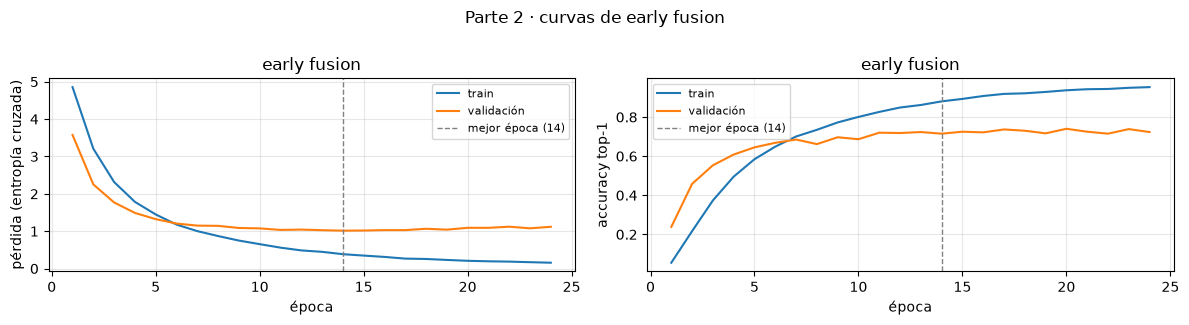

In [21]:
def build_early_fusion():
    img = keras.Input((2048,), name="image")
    cap = keras.Input((MAX_LEN,), dtype="int32", name="caption")
    tab = keras.Input((318,), name="tabular")
    h_img = layers.Dense(512, activation="relu", name="img_dense512")(img)
    h_txt = text_encoder(cap)
    h_tab = layers.Dense(128, activation="relu", name="tab_dense128")(tab)
    z = layers.Concatenate(name="concat")([h_img, h_txt, h_tab])
    z = layers.Dropout(0.5, name="fusion_drop1")(z)
    z = layers.Dense(512, activation="relu", name="fusion_dense")(z)
    z = layers.Dropout(0.5, name="fusion_drop2")(z)
    return keras.Model({"image": img, "caption": cap, "tabular": tab},
                       layers.Dense(NUM_CLASSES, name="logits")(z), name="early_fusion")

EF_KEYS = ["image", "caption", "tabular"]
build_early_fusion().summary()
MODELS["early"], HISTS["early"] = train_keras("p2_early_fusion", build_early_fusion, EF_KEYS, 80, 10, 1e-3)
EXPERIMENTS["p2_early_fusion"] = {"framework": "TensorFlow/Keras", "keys": EF_KEYS, "lr": 1e-3} | HISTS["early"]["_meta"]
plot_histories({"early fusion": HISTS["early"]}, "Parte 2 · curvas de early fusion", "p2_curvas")

In [22]:
PROBA["early"] = {s: predict_proba(MODELS["early"], s, EF_KEYS) for s in ["train", "val", "test"]}
METRICS["early"] = {s: clf_metrics(DATA[s]["y"], PROBA["early"][s]) for s in ["train", "val", "test"]}
save_json(METRICS["early"], MET_DIR / "p2_early_fusion.json")
p2_table = pd.concat([p1_table, pd.DataFrame([{"modelo": "early fusion", "accuracy": METRICS["early"]["test"]["accuracy"],
           "F1-macro": METRICS["early"]["test"]["f1_macro"], "ROC-AUC macro": METRICS["early"]["test"]["roc_auc_macro"],
           "top-1": METRICS["early"]["test"]["top1"], "top-5": METRICS["early"]["test"]["top5"]}]).set_index("modelo")])
p2_table["Δ top-1 vs mejor unimodal (pp)"] = 100 * (p2_table["top-1"] - p1_table["top-1"].max())
p2_table.to_csv(TAB_DIR / "p2_comparacion.csv")
display(p2_table.style.format("{:.4f}").set_caption("Parte 2 · early fusion frente a los unimodales (test)"))
print(f"Brecha train−val de early fusion: {METRICS['early']['train']['accuracy'] - METRICS['early']['val']['accuracy']:.4f}")
CONF["early"] = top_confusions(DATA["test"]["y"], PROBA["early"]["test"].argmax(1))
CONF["early"].to_csv(TAB_DIR / "p2_confusiones_early.csv")
print("Top-10 parejas confundidas por early fusion:"); display(CONF["early"].drop(columns=["a", "b"]))

,accuracy,F1-macro,ROC-AUC macro,top-1,top-5,Δ top-1 vs mejor unimodal (pp)
modelo,,,,,,
imagen,0.7304,0.7311,0.9953,0.7304,0.9427,0.0000
texto,0.2520,0.2429,0.9380,0.2520,0.5369,-47.8426
atributos,0.4743,0.4672,0.9737,0.4743,0.7570,-25.6127
early fusion,0.7382,0.7363,0.9960,0.7382,0.9448,0.7767


Brecha train−val de early fusion: 0.2735
Top-10 parejas confundidas por early fusion:


,especie A,especie B,A→B,B→A,total
1,Brandt Cormorant,Pelagic Cormorant,7,10,17
2,Common Tern,Forsters Tern,12,4,16
3,Northern Waterthrush,Louisiana Waterthrush,9,6,15
4,Olive sided Flycatcher,Western Wood Pewee,4,10,14
5,California Gull,Glaucous winged Gull,10,4,14
6,Anna Hummingbird,Ruby throated Hummingbird,2,12,14
7,Black footed Albatross,Sooty Albatross,11,2,13
8,Glaucous winged Gull,Herring Gull,2,11,13
9,Loggerhead Shrike,Great Grey Shrike,6,7,13
10,Chuck will Widow,Whip poor Will,6,6,12


**Contribución de cada rama (diagnóstico *post hoc*).** Para entender qué aprendió la cabeza de fusión, se evalúa el modelo **ya entrenado** en validación anulando una rama cada vez: su vector de *features* se sustituye por su media en entrenamiento. Este procedimiento es solo un diagnóstico; no se entrena nada nuevo. Una caída grande indica que la cabeza depende mucho de esa rama.

In [23]:
def branch_ablation_early(model, split="val"):
    names = {"imagen": "img_dense512", "texto": "lstm", "atributos": "tab_dense128"}
    feats_model = keras.Model(model.input, [model.get_layer(n).output for n in names.values()])
    head_in = keras.Input((896,)); x = head_in
    # Cabeza = capas posteriores a la concatenación, reutilizando los mismos pesos entrenados
    for lname in ["fusion_drop1", "fusion_dense", "fusion_drop2", "logits"]:
        x = model.get_layer(lname)(x)
    head = keras.Model(head_in, x)
    tr_feats = feats_model.predict(CUBSequence("train", EF_KEYS, 512), verbose=0)
    feats = feats_model.predict(CUBSequence(split, EF_KEYS, 512), verbose=0)
    y = DATA[split]["y"]; res = {"completo": accuracy_score(y, head.predict(np.concatenate(feats, 1), verbose=0).argmax(1))}
    for k, name in enumerate(names):
        f2 = [f.copy() for f in feats]; f2[k][:] = tr_feats[k].mean(0)
        res[f"sin {name}"] = accuracy_score(y, head.predict(np.concatenate(f2, 1), verbose=0).argmax(1))
    return res

ef_branch = branch_ablation_early(MODELS["early"])
save_json(ef_branch, MET_DIR / "p2_ablacion_ramas_val.json")
display(pd.Series(ef_branch, name="accuracy validación").to_frame().style.format("{:.4f}"))

,accuracy validación
completo,0.7150
sin imagen,0.1800
sin texto,0.7117
sin atributos,0.6433


**Interpretación de resultados (Parte 2).**

*¿Mejora un único modelo que ve todo a la vez?* **Apenas.** La *early fusion* obtiene 73,82 % de top-1, 94,48 % de top-5, F1-macro de 0,736 y ROC-AUC de 0,996 en test, frente a 73,04 %, 94,27 %, 0,731 y 0,995 del mejor unimodal (imagen). La mejora es de **+0,78 pp** en top-1, del mismo orden que el error estándar binomial de una accuracy en este test (≈ 0,58 pp con n = 5.794; la diferencia equivale a ≈ 1,3 errores estándar). No se aplicó una prueba pareada de significación (McNemar o *bootstrap* sobre las mismas imágenes) ni se entrenó con varias semillas, así que no puede afirmarse que la diferencia sea significativa (sección 13). En validación la mejora es nula: ambos modelos obtienen 71,5 %. Tampoco se reduce el sobreajuste: la brecha train−val es de 27,35 pp, prácticamente la misma que la del modelo de imagen (28,1 pp).

*¿Por qué gana tan poco si texto y atributos aportan información complementaria?* El diagnóstico por ramas lo explica. Si se sustituye la rama de **imagen** por su media, la accuracy de validación cae de 71,5 % a **18,0 %**. Si se anulan los **atributos**, cae a **64,3 %** (−7,2 pp). Si se anula el **texto**, apenas cambia: **71,2 %** (−0,3 pp). La cabeza de fusión aprendió a basarse casi solo en la imagen, a usar un poco los atributos e **ignorar el texto**. Es el fenómeno de **competencia entre modalidades** descrito por Wang, Tran y Feiszli (2020). Con una sola pérdida conjunta, la rama que reduce antes la pérdida (aquí la imagen, cuyo embedding preentrenado ya es casi linealmente separable) domina el gradiente. La early fusion alcanza un 98,9 % de accuracy en entrenamiento (brecha de 27,35 pp con validación). Una explicación plausible es que, una vez que la imagen basta para ajustar el entrenamiento, la pérdida apenas deja gradiente para que el LSTM, más lento de optimizar, aprenda algo útil. Las parejas más confundidas por la *early fusion* (cormoranes, charranes, *waterthrushes*, gaviotas, colibríes) son, en su mayoría, las mismas que confundía el modelo de imagen.

---
# 7. Parte 3 — Late fusion, ablación y robustez

**Pregunta:** ¿basta con combinar las predicciones de los modelos de la Parte 1?

Los tres modelos de la Parte 1 **no se reentrenan**: solo se combinan sus vectores de probabilidad $\mathbf{p}^{(m)}\in\Delta^{199}$, con $m\in\{\text{img},\text{txt},\text{attr}\}$. Se comparan tres reglas:

1. **Promedio uniforme:** $\;\hat{\mathbf p}=\frac{1}{M}\sum_m \mathbf p^{(m)}$.
2. **Promedio ponderado:** $\;\hat{\mathbf p}=\sum_m w_m\,\mathbf p^{(m)}$, con $w_m\ge 0$ y $\sum_m w_m=1$.
3. **Producto de expertos / log-lineal ponderado:** $\;\hat p_c \propto \exp\big(\sum_m w_m \log p^{(m)}_c\big)$, es decir, una media geométrica ponderada. Se justifica cuando los modelos aportan evidencia condicionalmente independiente: una especie solo recibe probabilidad alta si **todas** las modalidades la consideran plausible, lo que penaliza las clases que un experto descarta con seguridad.

**Selección de pesos solo con validación.** Los pesos se buscan en una rejilla del símplex con paso 0,05 (231 combinaciones para tres modelos) y se elige la que maximiza la accuracy en **validación** (600 imágenes), desempatando por menor *log-loss*. La regla «mejor» también se elige por validación. El test solo se usa para reportar.

In [24]:
MODS = ["imagen", "texto", "atributos"]

def fuse(Ps, w, rule):
    w = np.asarray(w, float)
    if rule == "mean":
        P = sum(wi * Pi for wi, Pi in zip(w, Ps))
    elif rule == "loglinear":
        L = sum(wi * np.log(np.clip(Pi, 1e-12, 1)) for wi, Pi in zip(w, Ps))
        P = softmax64(L)
    return P / P.sum(1, keepdims=True)

def simplex_grid(k, step=0.05):
    n = int(round(1 / step))
    if k == 1: return [np.array([1.0])]
    return [np.array(c) / n for c in __import__("itertools").product(range(n + 1), repeat=k) if sum(c) == n]

def nll(y, P): return float(-np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))))

def select_weights(mods, rule, split="val"):
    y = DATA[split]["y"]; Ps = [PROBA[m][split] for m in mods]
    best = None
    for w in simplex_grid(len(mods)):
        P = fuse(Ps, w, rule); key = (accuracy_score(y, P.argmax(1)), -nll(y, P))
        if best is None or key > best[0]: best = (key, w)
    return best[1], best[0]

LATE = {}
for rule_name, rule, weighted in [("late · promedio uniforme", "mean", False),
                                   ("late · promedio ponderado (val)", "mean", True),
                                   ("late · log-lineal ponderado (val)", "loglinear", True)]:
    if weighted:
        w, (vacc, _) = select_weights(MODS, rule)
    else:
        w = np.ones(3) / 3; vacc = accuracy_score(DATA["val"]["y"], fuse([PROBA[m]["val"] for m in MODS], w, rule).argmax(1))
    LATE[rule_name] = {"rule": rule, "weights": dict(zip(MODS, map(float, w))), "val_acc": float(vacc)}
    for s in ["val", "test"]:
        PROBA[rule_name] = PROBA.get(rule_name, {}); PROBA[rule_name][s] = fuse([PROBA[m][s] for m in MODS], w, rule)
    METRICS[rule_name] = {s: clf_metrics(DATA[s]["y"], PROBA[rule_name][s]) for s in ["val", "test"]}
BEST_LATE = max(LATE, key=lambda k: LATE[k]["val_acc"])
save_json({"rules": LATE, "best_by_val": BEST_LATE}, MET_DIR / "p3_late_fusion_pesos.json")
display(pd.DataFrame({k: {"pesos (img, txt, attr)": tuple(round(v, 2) for v in d["weights"].values()), "acc val": d["val_acc"]}
                      for k, d in LATE.items()}).T)
print("Mejor regla según VALIDACIÓN:", BEST_LATE)

,"pesos (img, txt, attr)",acc val
late · promedio uniforme,"(0.33, 0.33, 0.33)",0.743333
late · promedio ponderado (val),"(0.5, 0.25, 0.25)",0.755
late · log-lineal ponderado (val),"(0.5, 0.2, 0.3)",0.78


Mejor regla según VALIDACIÓN: late · log-lineal ponderado (val)


## 7.1 Tabla resumen (test): unimodales, early fusion y late fusion

In [25]:
summary_models = MODS + ["early"] + list(LATE)
pretty = {"imagen": "Parte 1 · imagen", "texto": "Parte 1 · texto", "atributos": "Parte 1 · atributos", "early": "Parte 2 · early fusion"}
p3_table = pd.DataFrame([{"modelo": pretty.get(m, "Parte 3 · " + m), "top-1": METRICS[m]["test"]["top1"], "top-5": METRICS[m]["test"]["top5"],
                          "F1-macro": METRICS[m]["test"]["f1_macro"], "ROC-AUC macro": METRICS[m]["test"]["roc_auc_macro"],
                          "top-1 val": METRICS[m]["val"]["top1"]} for m in summary_models]).set_index("modelo")
p3_table.to_csv(TAB_DIR / "p3_tabla_resumen.csv")
display(p3_table.style.format("{:.4f}").highlight_max(subset=["top-1", "top-5"], color="#d5f5e3")
        .set_caption("Tabla resumen · test (5.794 imágenes, 200 especies)"))
for m in LATE: save_json(METRICS[m], MET_DIR / f"p3_{re.sub(r'[^a-z]+', '_', m)}.json")

,top-1,top-5,F1-macro,ROC-AUC macro,top-1 val
modelo,,,,,
Parte 1 · imagen,0.7304,0.9427,0.7311,0.9953,0.7150
Parte 1 · texto,0.2520,0.5369,0.2429,0.9380,0.2683
Parte 1 · atributos,0.4743,0.7570,0.4672,0.9737,0.4917
Parte 2 · early fusion,0.7382,0.9448,0.7363,0.9960,0.7150
Parte 3 · late · promedio uniforme,0.7591,0.9370,0.7552,0.9947,0.7433
Parte 3 · late · promedio ponderado (val),0.7689,0.9424,0.7673,0.9953,0.7550
Parte 3 · late · log-lineal ponderado (val),0.7977,0.9622,0.7987,0.9971,0.7800


**Interpretación de resultados (Parte 3, tabla resumen).**

*¿Basta con combinar las predicciones de los modelos de la Parte 1?* **Sí, y funciona mejor que la early fusion.** Las tres reglas de *late fusion* superan al mejor unimodal y a la *early fusion*:

| Regla | top-1 test | top-5 test | Δ top-1 vs imagen | Δ top-1 vs early |
|---|---|---|---|---|
| promedio uniforme | 75,91 % | 93,70 % | +2,87 pp | +2,09 pp |
| promedio ponderado (pesos de val: 0,5 / 0,25 / 0,25) | 76,89 % | 94,24 % | +3,85 pp | +3,07 pp |
| **log-lineal ponderado (val: 0,5 / 0,2 / 0,3)** | **79,77 %** | **96,22 %** | **+6,73 pp** | **+5,95 pp** |

La regla log-lineal ponderada fue también la mejor en **validación** (78,0 %, frente a 75,5 % y 74,3 %), así que su elección no usa el test. Además obtiene el mejor F1-macro (0,799) y el mejor ROC-AUC (0,997) de todo el bloque supervisado.

*¿Por qué gana la regla log-lineal?* Equivale a un **producto de expertos**: la puntuación de una especie es la media geométrica ponderada de sus probabilidades bajo cada modalidad. Para que una especie gane, debe ser plausible para **todos** los modelos, y una modalidad que asigna probabilidad muy baja a una especie actúa como **veto**. Esto aprovecha justo lo observado en la Parte 1: cuando la imagen duda entre dos charranes, los atributos o el texto suelen descartar a uno, porque sus errores rara vez apuntan a la misma especie (solo el 7 % de los fallos conjuntos). El promedio aritmético, en cambio, deja que un modelo muy seguro domine y suaviza los vetos. El promedio **uniforme** da además al texto, el modelo más débil, el mismo peso que a la imagen.

*¿Por qué la late fusion supera a la early fusion?* Cada modelo unimodal se entrenó por separado y extrae al máximo su modalidad. El LSTM, por ejemplo, aprendió a usar el texto porque no tenía otra fuente de información. En la early fusion, la competencia entre modalidades hizo que el texto se ignorase. Combinar a posteriori evita esa competencia, a costa de no modelar interacciones entre modalidades. Con estos datos, la ganancia por complementariedad pesa más que la posible ganancia por interacción.

## 7.2 Ablación por pares de modalidades

Se repite la **mejor regla** (elegida en validación) con cada par de modalidades. Si la regla es ponderada, los pesos del par se **vuelven a seleccionar en validación** con la misma rejilla. Pregunta: ¿qué modalidad es imprescindible?

In [26]:
best_rule = LATE[BEST_LATE]["rule"]; best_weighted = "uniforme" not in BEST_LATE
abl_rows = []
for pair in [("imagen", "texto"), ("imagen", "atributos"), ("texto", "atributos"), tuple(MODS)]:
    w = select_weights(list(pair), best_rule)[0] if best_weighted else np.ones(len(pair)) / len(pair)
    Pt = fuse([PROBA[m]["test"] for m in pair], w, best_rule)
    Pv = fuse([PROBA[m]["val"] for m in pair], w, best_rule)
    missing = [m for m in MODS if m not in pair]
    abl_rows.append({"modalidades": " + ".join(pair), "falta": missing[0] if missing else "—",
                     "pesos": tuple(round(float(x), 2) for x in w), "top-1 val": topk_acc(DATA["val"]["y"], Pv, 1),
                     "top-1 test": topk_acc(DATA["test"]["y"], Pt, 1), "top-5 test": topk_acc(DATA["test"]["y"], Pt, 5)})
abl = pd.DataFrame(abl_rows).set_index("modalidades")
full = abl.loc[" + ".join(MODS), "top-1 test"]
abl["caída vs 3 modalidades (pp)"] = 100 * (abl["top-1 test"] - full)
abl.to_csv(TAB_DIR / "p3_ablacion.csv")
display(abl.style.format({c: "{:.4f}" for c in ["top-1 val", "top-1 test", "top-5 test"]} | {"caída vs 3 modalidades (pp)": "{:+.2f}"})
        .set_caption(f"Ablación con la regla «{BEST_LATE}» (test)"))

,falta,pesos,top-1 val,top-1 test,top-5 test,caída vs 3 modalidades (pp)
modalidades,,,,,,
imagen + texto,atributos,"(0.6, 0.4)",0.7400,0.7580,0.9517,-3.97
imagen + atributos,texto,"(0.75, 0.25)",0.7733,0.7815,0.9575,-1.62
texto + atributos,imagen,"(0.45, 0.55)",0.5750,0.5564,0.8267,-24.13
imagen + texto + atributos,—,"(0.5, 0.2, 0.3)",0.7800,0.7977,0.9622,+0.00


**Interpretación de resultados (Parte 3, ablación).** Con la mejor regla (log-lineal ponderada) y pesos reseleccionados en validación para cada par:

- **texto + atributos (sin imagen): 55,64 %** (−24,13 pp respecto a las tres modalidades);
- **imagen + texto (sin atributos): 75,80 %** (−3,97 pp);
- **imagen + atributos (sin texto): 78,15 %** (−1,62 pp);
- las tres: 79,77 %.

*¿Qué modalidad es imprescindible?* **La imagen.** Quitarla cuesta 24 pp, seis veces más que quitar cualquiera de las otras. Aun así, la imagen no basta: ambos pares con imagen superan al modelo de imagen sola (73,04 %), con +5,11 pp al añadir atributos y +2,76 pp al añadir texto. Las tres modalidades juntas son la mejor opción.

El orden de importancia es imagen ≫ atributos > texto, y coincide con los pesos elegidos en validación (0,5 / 0,3 / 0,2) y con el diagnóstico por ramas de la early fusion. Un resultado notable: texto + atributos (55,64 %) supera en 8,2 pp a los atributos solos y en 30,4 pp al texto solo. Las dos modalidades «débiles» también son complementarias entre sí: el texto aporta información de color en lenguaje natural y los atributos, información estructurada de forma y partes.

## 7.3 Robustez ante una modalidad degradada (solo en test)

Se degrada **una** modalidad cada vez y se mide la caída de todos los modelos afectados, **siempre con las mismas entradas degradadas**:

1. **Texto incorrecto.** Para cada imagen de test, su caption (la caption 0) se reemplaza por la caption 0 de **otra imagen de test elegida al azar entre las de especies distintas** (`numpy.default_rng(42)`). La imagen y los atributos no cambian.
2. **Imagen con ruido.** Se usan los embeddings ResNet50 **recalculados** a partir de las imágenes de test con ruido gaussiano en los píxeles, $\sigma\in\{0.1, 0.25, 0.5\}$ (sección 3). **No** se añade ruido al embedding.

Modelos evaluados: los unimodales afectados, *early fusion* (el mismo modelo entrenado, con la entrada degradada) y *late fusion* con los **mismos pesos** elegidos en validación limpia. Ningún modelo se reentrena ni se recalibra con datos degradados.

In [27]:
rng = np.random.default_rng(SEED)
yt = DATA["test"]["y"]; n_test = len(yt)
donor = np.empty(n_test, int)
for i in range(n_test):
    cand = np.flatnonzero(yt != yt[i]); donor[i] = cand[rng.integers(len(cand))]
assert (yt[donor] != yt).all()
SWAPPED_CAPS = DATA["test"]["caps"][donor, 0]
print("Ejemplo de reemplazo:")
for i in [0, 1]:
    print(f"  {CLASS_NAMES[yt[i]]:32s} ← caption de {CLASS_NAMES[yt[donor[i]]]}: «{image_table.iloc[DATA['test']['rows'][donor[i]]].captions[0]}»")

def probs_under(condition):
    # Probabilidades en test de cada modelo bajo una condición: 'clean', 'text_swap' o un sigma.
    kw_txt = {"caption_override": SWAPPED_CAPS} if condition == "text_swap" else {}
    kw_img = {"image_override": EMB_NOISE[condition]} if isinstance(condition, float) else {}
    P = {"imagen": predict_proba(MODELS["imagen"], "test", ["image"], **kw_img) if kw_img else PROBA["imagen"]["test"],
         "texto": predict_proba(MODELS["texto"], "test", ["caption"], **kw_txt) if kw_txt else PROBA["texto"]["test"],
         "atributos": PROBA["atributos"]["test"]}
    P["early"] = predict_proba(MODELS["early"], "test", EF_KEYS, **kw_txt, **kw_img) if (kw_txt or kw_img) else PROBA["early"]["test"]
    for rule_name, d in LATE.items():
        P[rule_name] = fuse([P[m] for m in MODS], list(d["weights"].values()), d["rule"])
    return P

CONDITIONS = ["clean", "text_swap"] + NOISE_SIGMAS
cond_label = {"clean": "limpio", "text_swap": "texto de otra especie", 0.1: "ruido σ=0.1", 0.25: "ruido σ=0.25", 0.5: "ruido σ=0.5"}
ROB = {c: probs_under(c) for c in CONDITIONS}
rob_models = MODS + ["early"] + list(LATE)
rob = pd.DataFrame({cond_label[c]: {pretty.get(m, m): topk_acc(yt, ROB[c][m], 1) for m in rob_models} for c in CONDITIONS})
rob_drop = 100 * rob.sub(rob["limpio"], axis=0)
rob.to_csv(TAB_DIR / "p3_robustez_top1.csv"); rob_drop.to_csv(TAB_DIR / "p3_robustez_caida_pp.csv")
rob5 = pd.DataFrame({cond_label[c]: {pretty.get(m, m): topk_acc(yt, ROB[c][m], 5) for m in rob_models} for c in CONDITIONS})
rob5.to_csv(TAB_DIR / "p3_robustez_top5.csv")
display(rob.style.format("{:.4f}").set_caption("Robustez · accuracy top-1 en test"))
display(rob_drop.style.format("{:+.2f}").background_gradient(cmap="Reds_r", axis=None)
        .set_caption("Caída respecto a la condición limpia (puntos porcentuales)"))

Ejemplo de reemplazo:
  Black footed Albatross           ← caption de Eastern Towhee: «this small, round bird has a charcoal black top, golden retriever brown wings and a soft, tan belly.»
  Black footed Albatross           ← caption de White eyed Vireo: «this bright little bird has exceptional white, wingbars that separate its coverts, primaries and secondaries, its eyering is visibly yellow and bright compared to its more darker green tones of the back and tail.»


,limpio,texto de otra especie,ruido σ=0.1,ruido σ=0.25,ruido σ=0.5
Parte 1 · imagen,0.7304,0.7304,0.5212,0.1386,0.0154
Parte 1 · texto,0.2520,0.0041,0.2520,0.2520,0.2520
Parte 1 · atributos,0.4743,0.4743,0.4743,0.4743,0.4743
Parte 2 · early fusion,0.7382,0.7297,0.5747,0.2144,0.0442
late · promedio uniforme,0.7591,0.7306,0.6476,0.4691,0.4066
late · promedio ponderado (val),0.7689,0.7563,0.6113,0.3252,0.2169
late · log-lineal ponderado (val),0.7977,0.7703,0.6861,0.3942,0.2256


,limpio,texto de otra especie,ruido σ=0.1,ruido σ=0.25,ruido σ=0.5
Parte 1 · imagen,+0.00,+0.00,-20.92,-59.18,-71.51
Parte 1 · texto,+0.00,-24.78,+0.00,+0.00,+0.00
Parte 1 · atributos,+0.00,+0.00,+0.00,+0.00,+0.00
Parte 2 · early fusion,+0.00,-0.85,-16.34,-52.38,-69.40
late · promedio uniforme,+0.00,-2.85,-11.15,-29.00,-35.24
late · promedio ponderado (val),+0.00,-1.26,-15.76,-44.37,-55.20
late · log-lineal ponderado (val),+0.00,-2.74,-11.17,-40.35,-57.21


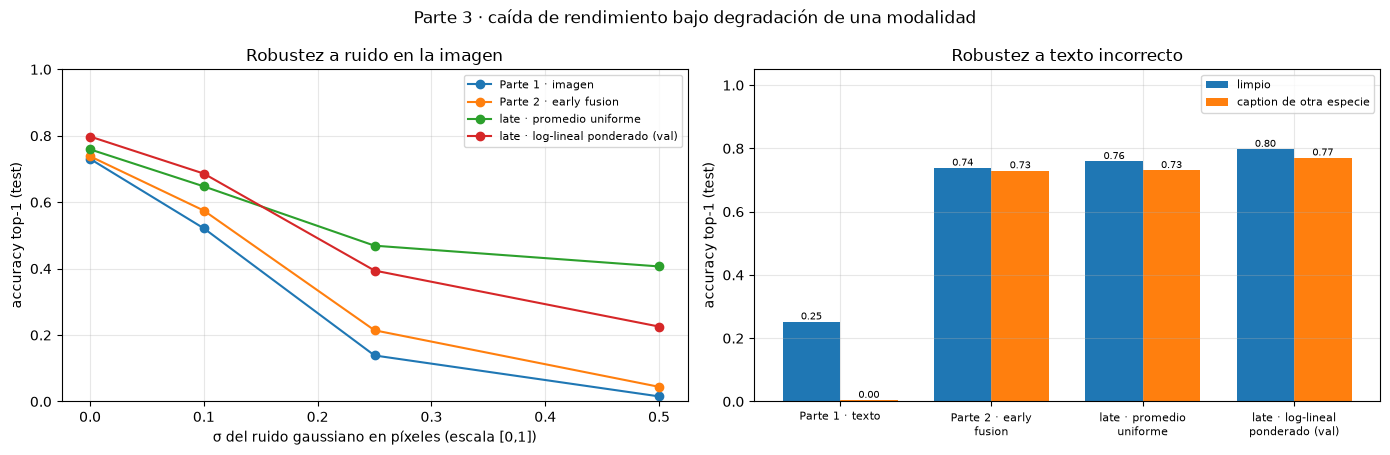

In [28]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
sel = [pretty["imagen"], pretty["early"], "late · promedio uniforme", BEST_LATE]
sel = list(dict.fromkeys(sel))
xs = [0] + NOISE_SIGMAS
for m in sel:
    a1.plot(xs, [rob.loc[m, "limpio"]] + [rob.loc[m, cond_label[s]] for s in NOISE_SIGMAS], marker="o", label=m)
a1.set_xlabel("σ del ruido gaussiano en píxeles (escala [0,1])"); a1.set_ylabel("accuracy top-1 (test)")
a1.set_title("Robustez a ruido en la imagen"); a1.legend(fontsize=8); a1.set_ylim(0, 1)
sel2 = [pretty["texto"], pretty["early"], "late · promedio uniforme", BEST_LATE]
sel2 = list(dict.fromkeys(sel2))
xx = np.arange(len(sel2)); wbar = 0.38
b1 = a2.bar(xx - wbar / 2, rob.loc[sel2, "limpio"], wbar, label="limpio")
b2 = a2.bar(xx + wbar / 2, rob.loc[sel2, "texto de otra especie"], wbar, label="caption de otra especie")
a2.bar_label(b1, fmt="%.2f", fontsize=7); a2.bar_label(b2, fmt="%.2f", fontsize=7)
a2.set_xticks(xx, [textwrap.fill(s, 18) for s in sel2], fontsize=8); a2.set_ylabel("accuracy top-1 (test)")
a2.set_title("Robustez a texto incorrecto"); a2.legend(fontsize=8); a2.set_ylim(0, 1.05)
fig.suptitle("Parte 3 · caída de rendimiento bajo degradación de una modalidad"); fig.tight_layout()
save_fig(fig, "p3_robustez"); plt.show()

**Interpretación de resultados (Parte 3, robustez).**

*Texto incorrecto* (caption de otra especie). El modelo de texto se derrumba: de 25,20 % a 0,41 % de top-1, por debajo del azar, porque ahora predice con seguridad la especie de la caption ajena. La **early fusion** apenas lo nota: pasa de 73,82 % a 72,97 % (−0,85 pp). Coincide con el diagnóstico por ramas: el modelo casi no usa el texto, así que tampoco le perjudica que sea falso. La late fusion log-lineal cae 2,74 pp (de 79,77 % a 77,03 %), pero **sigue siendo el mejor modelo en valor absoluto** y conserva 4 pp de ventaja sobre la early fusion. Con un peso de 0,2, el texto falso no consigue vetar la especie correcta cuando imagen y atributos coinciden. La regla ponderada aritmética es la que menos cae (−1,26 pp).

*Imagen con ruido.* Aquí el orden se invierte según la intensidad:

| top-1 test | limpio | σ = 0,1 | σ = 0,25 | σ = 0,5 |
|---|---|---|---|---|
| imagen | 73,04 % | 52,12 % | 13,86 % | 1,54 % |
| early fusion | 73,82 % | 57,47 % | 21,44 % | 4,42 % |
| late · log-lineal ponderado | 79,77 % | **68,61 %** | 39,42 % | 22,56 % |
| late · promedio uniforme | 75,91 % | 64,76 % | **46,91 %** | **40,66 %** |

- La **early fusion** se degrada casi como el modelo de imagen (−69,4 pp con σ = 0,5). Su cabeza depende de la rama visual, y los embeddings ruidosos (coseno 0,12 con el limpio) quedan fuera de la distribución vista en entrenamiento: la cabeza no puede «cambiar» a texto y atributos, que siguen intactos.
- La **late fusion** degrada mucho menos, porque texto y atributos mantienen sus probabilidades intactas. Con ruido leve (σ = 0,1), la regla log-lineal sigue siendo la mejor (68,61 %). Con ruido fuerte, la mejor es el **promedio uniforme** (40,66 % con σ = 0,5). Da más peso a las modalidades limpias y, al ser aritmético, el modelo de imagen corrompido no puede **vetar** la especie correcta. En la regla log-lineal, la imagen ruidosa asigna probabilidades casi nulas a especies correctas, y ese veto antes útil ahora es dañino.
- Ninguna regla detecta que una modalidad está corrupta. Con σ = 0,5, incluso el promedio uniforme (40,66 %) queda por debajo de lo que se obtendría **descartando la imagen** (texto + atributos: 55,64 %). Unos pesos fijos elegidos en datos limpios no adaptan la fusión a la fiabilidad de cada modalidad en cada muestra. Haría falta ponderación por incertidumbre o *gating*.

*Conclusión:* en condiciones limpias conviene la late fusion log-lineal. Ante una modalidad degradada, la late fusion es claramente más robusta que la early fusion. La regla más robusta depende de la severidad de la degradación.

---
# 8. Parte 4 — Red siamesa de imágenes (aprendizaje métrico)

**Pregunta:** ¿se pueden reconocer especies nuevas comparando fotos?

## 8.1 Partición (protocolo estándar de *metric learning* en CUB)

No se reutiliza el split de la Tarea 1, porque contiene las 200 especies tanto en train como en test. La partición se reconstruye desde los `class_id` originales:

- **Entrenamiento:** imágenes de las especies **1–100**, excepto un 10 % estratificado por especie (`random_state=42`).
- **Validación:** ese 10 % (mismas especies 1–100, imágenes distintas). Se usa para *early stopping* y para elegir el margen.
- **Evaluación:** **todas** las imágenes de las especies **101–200**, que el modelo nunca ve durante el entrenamiento ni la selección de hiperparámetros.

## 8.2 Encoder y distancia

Un único encoder $f_\theta$, con **pesos compartidos** por las dos entradas, proyecta el embedding ResNet50:

$$f_\theta(\mathbf h) = \frac{W_2\,\mathrm{ReLU}(W_1\mathbf h + b_1) + b_2}{\big\|W_2\,\mathrm{ReLU}(W_1\mathbf h + b_1) + b_2\big\|_2}\in\mathbb{S}^{127},\qquad d(a,b)=\|f_\theta(\mathbf h_a)-f_\theta(\mathbf h_b)\|_2\in[0,2].$$

Sobre la esfera unidad, $d^2 = 2 - 2\cos(a,b)$, así que ordenar por distancia euclidiana equivale a ordenar por similitud coseno.

## 8.3 Pérdidas

1. **Contrastive loss** (Hadsell et al., 2006), tal como figura en el enunciado. Para un par con $y=1$ si es de la misma especie:
$$\mathcal{L}_{\text{contr}} = y\,d^2 + (1-y)\,\max(0,\,m-d)^2.$$
Atrae los positivos hasta $d=0$ y empuja los negativos hasta que superan el margen $m$; los negativos más lejanos que $m$ no aportan gradiente.

2. **Triplet loss** (Schroff et al., 2015). **Decisión metodológica añadida:** el enunciado anuncia dos pérdidas pero solo desarrolla la *contrastive*. Elegimos la *triplet* porque es la segunda pérdida canónica del *metric learning* y la que usa el *batch-hard mining* original (Hermans et al., 2017). Para un ancla $a$, un positivo $p$ y un negativo $n$:
$$\mathcal{L}_{\text{trip}} = \max\big(0,\; d(a,p) - d(a,n) + m\big).$$
Solo exige que el positivo esté más cerca que el negativo por un margen; no obliga a colapsar los positivos en un punto.

## 8.4 Muestreo P×K

Cada batch contiene $P=16$ especies × $K=4$ fotos = 64 imágenes. Una «época» equivale a $\lfloor N_{train}/64\rfloor$ batches. Las distancias se calculan entre todas las parejas del batch, y **nunca se considera a la propia imagen como su positivo** (diagonal excluida):

| Muestreo | Contrastive | Triplet |
|---|---|---|
| **Aleatorio** | todos los pares positivos del batch ($P\binom{K}{2}=96$) + el mismo número de pares negativos elegidos al azar | para cada ancla, un positivo y un negativo elegidos al azar dentro del batch |
| **Batch-hard** | para cada ancla, su positivo **más lejano** y su negativo **más cercano**, cada uno con su término de la *contrastive* | $\max(0, \max_p d(a,p) - \min_n d(a,n) + m)$ (Hermans et al., 2017) |

**Hiperparámetros.** Adam con lr = 1e-3, hasta 100 épocas y paciencia de 15 sobre el **Recall@1 de validación**. El margen se elige **en validación**: contrastive $m\in\{0.5, 1.0\}$, triplet $m\in\{0.1, 0.2, 0.3\}$ (para vectores L2-normalizados, $d\in[0,2]$). Por cada combinación (pérdida, muestreo) se reporta en test **solo** el margen elegido en validación.

## 8.5 Métrica

**Recall@K** (K = 1, 2, 4, 8): para cada imagen de las especies 101–200, se buscan sus K vecinos más cercanos entre **las demás** imágenes de 101–200 (excluyendo la propia) y se cuenta un acierto si al menos uno es de su misma especie.

**Gestión de memoria entre frameworks.** Las partes 1–3 usan TensorFlow/Keras y las partes 4–5 usan PyTorch, ambas en la misma GPU de 8 GB. Para evitar que los dos runtimes compitan por memoria, TensorFlow reserva memoria de forma incremental (`set_memory_growth`). Además, antes de entrenar con PyTorch se libera la sesión de Keras, se ejecuta el recolector de basura y se vacía la caché CUDA de PyTorch. La celda siguiente muestra la memoria GPU ocupada antes del entrenamiento métrico.

In [29]:
keras.backend.clear_session(); gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free_b, total_b = torch.cuda.mem_get_info()
    print(f"GPU: {(total_b - free_b) / 2**20:,.0f} MiB ocupados de {total_b / 2**20:,.0f} MiB antes de las partes 4–5")

GPU: 1,616 MiB ocupados de 8,188 MiB antes de las partes 4–5


In [30]:
CLASS_ID = image_table["class_id"].to_numpy()
pool_1_100 = np.flatnonzero(CLASS_ID <= 100)
SIA = {}
SIA["train"], SIA["val"] = train_test_split(pool_1_100, test_size=0.10, stratify=CLASS_ID[pool_1_100], random_state=SEED)
SIA["test"] = np.flatnonzero(CLASS_ID > 100)
for s in SIA: SIA[s] = np.sort(SIA[s])
sia_cls = {s: set(CLASS_ID[r]) for s, r in SIA.items()}
assert sia_cls["train"] == sia_cls["val"] == set(range(1, 101)) and sia_cls["test"] == set(range(101, 201))
assert not (set(SIA["train"]) & set(SIA["val"])) and not (set(SIA["train"]) & set(SIA["test"])) and not (set(SIA["val"]) & set(SIA["test"]))
assert not (sia_cls["train"] & sia_cls["test"])
display(pd.DataFrame({s: {"imágenes": len(r), "especies": len(sia_cls[s]), "class_id": f"{min(sia_cls[s])}–{max(sia_cls[s])}"} for s, r in SIA.items()}).T)

EMB_T = torch.tensor(np.asarray(EMB), device=DEVICE)
LAB_T = torch.tensor(LABELS, device=DEVICE)

class SiameseEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2048, 512), nn.ReLU(), nn.Linear(512, 128))
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)

def pairwise_dist(z):
    sq = (2 - 2 * z @ z.T).clamp_min(0)             # z con norma 1
    return torch.sqrt(sq + 1e-12)

def loss_fn(z, y, loss, sampler, m):
    D = pairwise_dist(z); n = len(y)
    same = y[:, None] == y[None, :]
    eye = torch.eye(n, dtype=torch.bool, device=z.device)
    pos, neg = same & ~eye, ~same
    if sampler == "batch_hard":
        d_ap = (D * pos).max(1).values                                    # positivo más lejano
        d_an = D.masked_fill(~neg, float("inf")).min(1).values             # negativo más cercano
        if loss == "contrastive":
            return (d_ap.pow(2) + F.relu(m - d_an).pow(2)).mean() / 2
        return F.relu(d_ap - d_an + m).mean()
    # muestreo aleatorio
    if loss == "contrastive":
        iu = torch.triu(torch.ones(n, n, dtype=torch.bool, device=z.device), 1)
        pi, pj = torch.nonzero(pos & iu, as_tuple=True)
        ni, nj = torch.nonzero(neg & iu, as_tuple=True)
        sel = torch.randperm(len(ni), device=z.device)[:len(pi)]
        dp, dn = D[pi, pj], D[ni[sel], nj[sel]]
        return torch.cat([dp.pow(2), F.relu(m - dn).pow(2)]).mean()
    rp = torch.rand(n, n, device=z.device).masked_fill(~pos, -1).argmax(1)  # positivo aleatorio (≠ ancla)
    rn = torch.rand(n, n, device=z.device).masked_fill(~neg, -1).argmax(1)  # negativo aleatorio
    ar = torch.arange(n, device=z.device)
    return F.relu(D[ar, rp] - D[ar, rn] + m).mean()

def pk_batches(rows, rng, P=16, K=4):
    labels = LABELS[rows]; groups = {c: rows[labels == c] for c in np.unique(labels)}; classes = np.array(list(groups))
    for _ in range(len(rows) // (P * K)):
        cs = rng.choice(classes, P, replace=False)
        yield np.concatenate([rng.choice(groups[c], K, replace=len(groups[c]) < K) for c in cs])

@torch.no_grad()
def recall_at_k(Z, y, ks=(1, 2, 4, 8)):
    S = Z @ Z.T
    S.fill_diagonal_(-float("inf"))                 # la propia imagen NUNCA cuenta como vecino
    top = S.topk(max(ks), dim=1).indices
    hit = (y[top] == y[:, None])
    return {f"R@{k}": float(hit[:, :k].any(1).float().mean()) for k in ks}

@torch.no_grad()
def embed_rows(model, rows):
    model.eval(); return model(EMB_T[torch.as_tensor(rows, device=DEVICE)])

# Prueba de que la exclusión de la propia imagen funciona: con vectores únicos y aleatorios,
# sin exclusión R@1 sería 1.0; con exclusión debe estar cerca del azar.
_z = F.normalize(torch.randn(1000, 32, device=DEVICE), dim=1); _y = torch.randint(0, 100, (1000,), device=DEVICE)
_r = recall_at_k(_z, _y)["R@1"]; assert _r < 0.1, _r
print(f"Comprobación de exclusión de la propia imagen: R@1 con embeddings aleatorios = {_r:.3f} (azar ≈ 0.01)")

,imágenes,especies,class_id
train,5277,100,1–100
val,587,100,1–100
test,5924,100,101–200


Comprobación de exclusión de la propia imagen: R@1 con embeddings aleatorios = 0.018 (azar ≈ 0.01)


In [31]:
def train_siamese(loss, sampler, m, max_epochs=100, patience=15, lr=1e-3):
    name = f"p4_{loss}_{sampler}_m{m}"
    ck = CKPT_DIR / "p4_siamese" / f"{name}.pt"; ck.parent.mkdir(parents=True, exist_ok=True)
    hpath = HIST_DIR / f"{name}.json"
    max_epochs = EPOCH_CAP or max_epochs
    model = SiameseEncoder().to(DEVICE)
    if ck.is_file() and hpath.is_file() and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ck, map_location=DEVICE)); return model, json.loads(hpath.read_text())
    set_all_seeds(SEED); model = SiameseEncoder().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr); rng = np.random.default_rng(SEED)
    yv = LAB_T[torch.as_tensor(SIA["val"], device=DEVICE)]
    hist = {"loss": [], "val_R@1": []}; best, wait, t0 = -1, 0, time.time()
    for ep in range(max_epochs):
        model.train(); losses = []
        for b in pk_batches(SIA["train"], rng):
            bt = torch.as_tensor(b, device=DEVICE)
            l = loss_fn(model(EMB_T[bt]), LAB_T[bt], loss, sampler, m)
            if not torch.isfinite(l): raise FloatingPointError(f"{name}: pérdida no finita en época {ep+1}")
            opt.zero_grad(); l.backward(); opt.step(); losses.append(l.item())
        r1 = recall_at_k(embed_rows(model, SIA["val"]), yv)["R@1"]
        hist["loss"].append(float(np.mean(losses))); hist["val_R@1"].append(r1)
        if r1 > best:
            best, wait = r1, 0; torch.save(model.state_dict(), ck)
        else:
            wait += 1
            if wait >= patience: break
    hist["_meta"] = {"epochs_run": len(hist["loss"]), "best_epoch": int(np.argmax(hist["val_R@1"])) + 1,
                     "best_val_R@1": best, "train_seconds": time.time() - t0, "margin": m, "lr": lr, "P": 16, "K": 4}
    hpath.write_text(json.dumps(hist, indent=2))
    model.load_state_dict(torch.load(ck, map_location=DEVICE))
    return model, hist

MARGINS = {"contrastive": [0.5, 1.0], "triplet": [0.1, 0.2, 0.3]}
grid_rows, SIA_MODELS, SIA_HISTS = [], {}, {}
for loss in ["contrastive", "triplet"]:
    for sampler in ["random", "batch_hard"]:
        for m in MARGINS[loss]:
            model, hist = train_siamese(loss, sampler, m)
            SIA_MODELS[(loss, sampler, m)], SIA_HISTS[(loss, sampler, m)] = model, hist
            grid_rows.append({"pérdida": loss, "muestreo": sampler, "margen": m, "R@1 val": hist["_meta"]["best_val_R@1"],
                              "mejor época": hist["_meta"]["best_epoch"], "épocas": hist["_meta"]["epochs_run"],
                              "tiempo (s)": round(hist["_meta"]["train_seconds"], 1)})
            print(f"  {loss:11s} {sampler:10s} m={m:<4} → R@1 val = {hist['_meta']['best_val_R@1']:.4f} "
                  f"({hist['_meta']['epochs_run']} épocas)")
grid = pd.DataFrame(grid_rows); grid.to_csv(TAB_DIR / "p4_seleccion_margen_val.csv", index=False)
display(grid.style.format({"R@1 val": "{:.4f}"}).set_caption("Selección de margen (solo validación, especies 1–100)"))

  contrastive random     m=0.5  → R@1 val = 0.6474 (100 épocas)
  contrastive random     m=1.0  → R@1 val = 0.6559 (63 épocas)


  contrastive batch_hard m=0.5  → R@1 val = 0.7428 (61 épocas)
  contrastive batch_hard m=1.0  → R@1 val = 0.7445 (62 épocas)


  triplet     random     m=0.1  → R@1 val = 0.6201 (50 épocas)
  triplet     random     m=0.2  → R@1 val = 0.6610 (74 épocas)
  triplet     random     m=0.3  → R@1 val = 0.6746 (76 épocas)


  triplet     batch_hard m=0.1  → R@1 val = 0.7445 (46 épocas)
  triplet     batch_hard m=0.2  → R@1 val = 0.7428 (37 épocas)
  triplet     batch_hard m=0.3  → R@1 val = 0.7445 (38 épocas)


,pérdida,muestreo,margen,R@1 val,mejor época,épocas,tiempo (s)
0,contrastive,random,0.500000,0.6474,96,100,25.100000
1,contrastive,random,1.000000,0.6559,48,63,16.000000
2,contrastive,batch_hard,0.500000,0.7428,46,61,12.900000
3,contrastive,batch_hard,1.000000,0.7445,47,62,14.100000
4,triplet,random,0.100000,0.6201,35,50,11.400000
5,triplet,random,0.200000,0.6610,59,74,17.100000
6,triplet,random,0.300000,0.6746,61,76,16.500000
7,triplet,batch_hard,0.100000,0.7445,31,46,9.600000
8,triplet,batch_hard,0.200000,0.7428,22,37,8.000000
9,triplet,batch_hard,0.300000,0.7445,23,38,7.700000


In [32]:
yt_sia = LAB_T[torch.as_tensor(SIA["test"], device=DEVICE)]
raw_test = F.normalize(EMB_T[torch.as_tensor(SIA["test"], device=DEVICE)], dim=1)
sia_rows = [{"configuración": "ResNet50 sin entrenar (L2)", "pérdida": "—", "muestreo": "—", "margen": None, "R@1 val": None}
            | recall_at_k(raw_test, yt_sia)]
SIA_SELECTED = {}
for (loss, sampler), g in grid.groupby(["pérdida", "muestreo"], sort=False):
    m = float(g.sort_values(["R@1 val", "margen"], ascending=[False, True]).iloc[0]["margen"])
    SIA_SELECTED[(loss, sampler)] = m
    model = SIA_MODELS[(loss, sampler, m)]
    sia_rows.append({"configuración": f"{loss} + {sampler}", "pérdida": loss, "muestreo": sampler, "margen": m,
                     "R@1 val": SIA_HISTS[(loss, sampler, m)]["_meta"]["best_val_R@1"]} | recall_at_k(embed_rows(model, SIA["test"]), yt_sia))
p4_table = pd.DataFrame(sia_rows).set_index("configuración")
p4_table.to_csv(TAB_DIR / "p4_recall_test.csv")
save_json(p4_table.reset_index().to_dict(orient="records"), MET_DIR / "p4_siamesa.json")
display(p4_table.style.format({c: "{:.4f}" for c in ["R@1 val", "R@1", "R@2", "R@4", "R@8"]}, na_rep="N/A")
        .highlight_max(subset=["R@1", "R@2", "R@4", "R@8"], color="#d5f5e3")
        .set_caption("Parte 4 · Recall@K en las especies NO VISTAS 101–200 (5.924 imágenes)"))
BEST_SIA = max(SIA_SELECTED, key=lambda k: SIA_HISTS[(k[0], k[1], SIA_SELECTED[k])]["_meta"]["best_val_R@1"])
BEST_SIA_KEY = (*BEST_SIA, SIA_SELECTED[BEST_SIA])
print("Mejor configuración según VALIDACIÓN:", BEST_SIA_KEY)
for k in SIA_SELECTED:
    EXPERIMENTS[f"p4_{k[0]}_{k[1]}"] = {"framework": "PyTorch"} | SIA_HISTS[(*k, SIA_SELECTED[k])]["_meta"]

,pérdida,muestreo,margen,R@1 val,R@1,R@2,R@4,R@8
configuración,,,,,,,,
ResNet50 sin entrenar (L2),—,—,N/A,N/A,0.5309,0.6646,0.7719,0.8621
contrastive + random,contrastive,random,1.000000,0.6559,0.1999,0.2876,0.3898,0.5164
contrastive + batch_hard,contrastive,batch_hard,1.000000,0.7445,0.1906,0.2731,0.3828,0.5096
triplet + random,triplet,random,0.300000,0.6746,0.3536,0.4797,0.6087,0.7308
triplet + batch_hard,triplet,batch_hard,0.100000,0.7445,0.3641,0.4948,0.6227,0.7515


Mejor configuración según VALIDACIÓN: ('contrastive', 'batch_hard', 1.0)


**Diagnóstico de generalización (especies vistas vs. no vistas).** Para interpretar la tabla anterior se mide el R@1 de cada embedding con las mismas reglas en tres conjuntos: train (especies 1–100), validación (imágenes nuevas de las especies 1–100) y test (especies 101–200, nunca vistas). Si el encoder aprende una métrica que transfiere, debería mejorar a la ResNet50 sin entrenar también en test.

In [33]:
diag = []
def _r1(Z, rows):
    return recall_at_k(Z, LAB_T[torch.as_tensor(rows, device=DEVICE)], ks=(1,))["R@1"]
diag.append({"embedding": "ResNet50 sin entrenar (L2)",
             **{f"R@1 {s}": _r1(F.normalize(EMB_T[torch.as_tensor(SIA[s], device=DEVICE)], dim=1), SIA[s]) for s in ["train", "val", "test"]}})
for (loss, sampler), m in SIA_SELECTED.items():
    mdl = SIA_MODELS[(loss, sampler, m)]
    diag.append({"embedding": f"{loss} + {sampler} (m={m})", **{f"R@1 {s}": _r1(embed_rows(mdl, SIA[s]), SIA[s]) for s in ["train", "val", "test"]}})
p4_diag = pd.DataFrame(diag).set_index("embedding")
p4_diag["Δ val vs base (pp)"] = 100 * (p4_diag["R@1 val"] - p4_diag.loc["ResNet50 sin entrenar (L2)", "R@1 val"])
p4_diag["Δ test vs base (pp)"] = 100 * (p4_diag["R@1 test"] - p4_diag.loc["ResNet50 sin entrenar (L2)", "R@1 test"])
p4_diag.to_csv(TAB_DIR / "p4_diagnostico_generalizacion.csv")
display(p4_diag.style.format("{:.4f}", subset=["R@1 train", "R@1 val", "R@1 test"]).format("{:+.1f}", subset=["Δ val vs base (pp)", "Δ test vs base (pp)"])
        .set_caption("R@1 por conjunto: especies vistas (train/val) frente a no vistas (test)"))

,R@1 train,R@1 val,R@1 test,Δ val vs base (pp),Δ test vs base (pp)
embedding,,,,,
ResNet50 sin entrenar (L2),0.6752,0.5451,0.5309,+0.0,+0.0
contrastive + random (m=1.0),0.9430,0.6559,0.1989,+11.1,-33.2
contrastive + batch_hard (m=1.0),1.0000,0.7445,0.1906,+19.9,-34.0
triplet + random (m=0.3),0.8575,0.6746,0.3536,+12.9,-17.7
triplet + batch_hard (m=0.1),0.9911,0.7445,0.3641,+19.9,-16.7


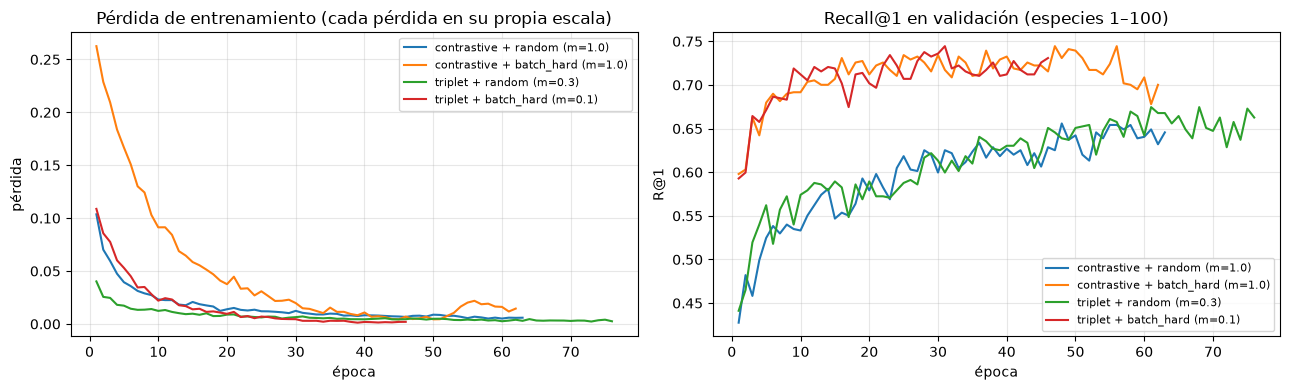

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, m in SIA_SELECTED.items():
    h = SIA_HISTS[(*k, m)]; lab = f"{k[0]} + {k[1]} (m={m})"
    axes[0].plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label=lab)
    axes[1].plot(np.arange(1, len(h["val_R@1"]) + 1), h["val_R@1"], label=lab)
axes[0].set_title("Pérdida de entrenamiento (cada pérdida en su propia escala)"); axes[0].set_xlabel("época"); axes[0].set_ylabel("pérdida")
axes[1].set_title("Recall@1 en validación (especies 1–100)"); axes[1].set_xlabel("época"); axes[1].set_ylabel("R@1")
for a in axes: a.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "p4_curvas"); plt.show()

## 8.6 Proyección 2D de 10 especies no vistas

Se proyectan todas las imágenes de las 10 primeras especies de evaluación (`class_id` 101–110), tanto con el embedding ResNet50 sin entrenar como con el encoder siamés elegido en validación. Se usan PCA (lineal, conserva la varianza global) y t-SNE (no lineal, conserva vecindades locales; `perplexity=30`, `random_state=42`). En t-SNE, las distancias entre grupos no deben interpretarse literalmente.

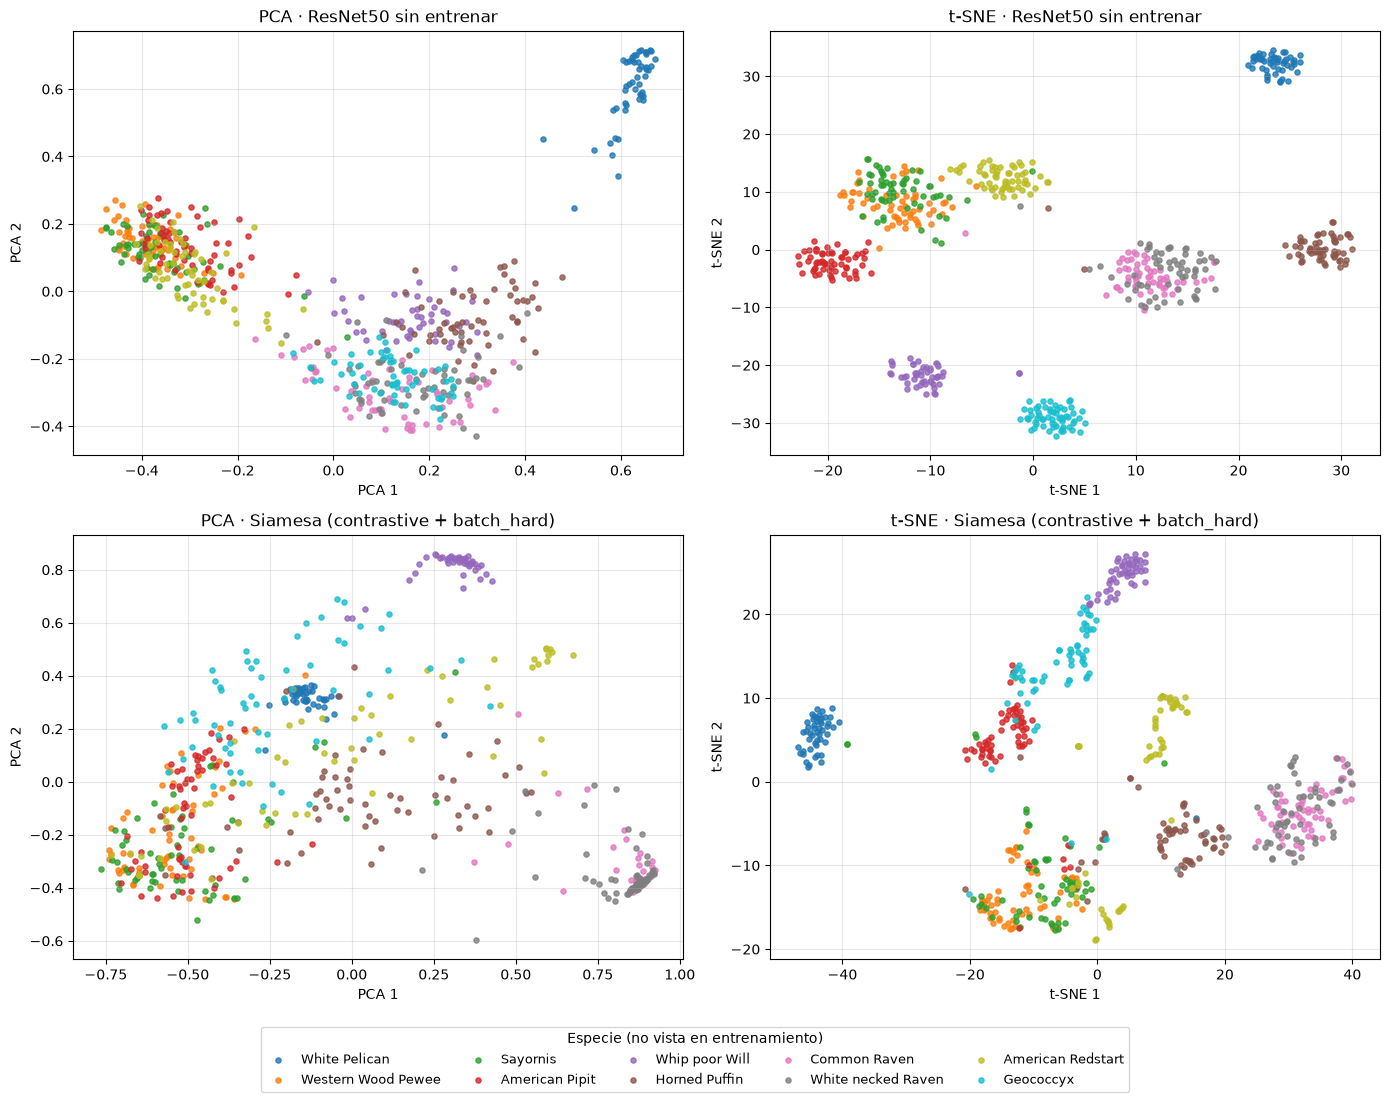

In [35]:
viz_rows = np.flatnonzero((CLASS_ID >= 101) & (CLASS_ID <= 110))
best_model = SIA_MODELS[BEST_SIA_KEY]
Z_learned = embed_rows(best_model, viz_rows).cpu().numpy()
Z_raw = F.normalize(EMB_T[torch.as_tensor(viz_rows, device=DEVICE)], dim=1).cpu().numpy()
yv10 = LABELS[viz_rows]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
cmap = plt.get_cmap("tab10")
for i, (Z, zname) in enumerate([(Z_raw, "ResNet50 sin entrenar"), (Z_learned, f"Siamesa ({BEST_SIA_KEY[0]} + {BEST_SIA_KEY[1]})")]):
    for j, (proj, pname) in enumerate([(PCA(2, random_state=SEED), "PCA"), (TSNE(2, perplexity=30, random_state=SEED, init="pca"), "t-SNE")]):
        P2 = proj.fit_transform(Z); ax = axes[i, j]
        for c_i, c in enumerate(np.unique(yv10)):
            mk = yv10 == c
            ax.scatter(P2[mk, 0], P2[mk, 1], s=14, color=cmap(c_i), label=CLASS_NAMES[c], alpha=0.8)
        ax.set_title(f"{pname} · {zname}"); ax.set_xlabel(f"{pname} 1"); ax.set_ylabel(f"{pname} 2")
handles, labels_ = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=5, fontsize=9, title="Especie (no vista en entrenamiento)")
fig.tight_layout(rect=(0, 0.07, 1, 1)); save_fig(fig, "p4_proyeccion_10_especies"); plt.show()

## 8.7 Reconocer especies no vistas a partir de imágenes de referencia

La red no tiene una salida por especie. Para reconocer una especie nueva basta con disponer de **imágenes de referencia** (una «galería» etiquetada): la consulta se asigna a la especie de la referencia más cercana. Se evalúa con las 100 especies no vistas (azar = 1 %):

- **1-shot:** una imagen de referencia por especie (elegida al azar con semilla 42);
- **5-shot:** el prototipo es la media renormalizada de 5 referencias.

Las consultas son todas las demás imágenes de esas especies, y ninguna referencia se usa como consulta. Además, se muestran tres consultas con sus 5 vecinos más cercanos (borde verde = misma especie).

,1-shot acc (100 especies),5-shot acc (100 especies)
embedding,,
ResNet50 sin entrenar,0.2445,0.4640
Siamesa contrastive + batch_hard,0.1264,0.1775


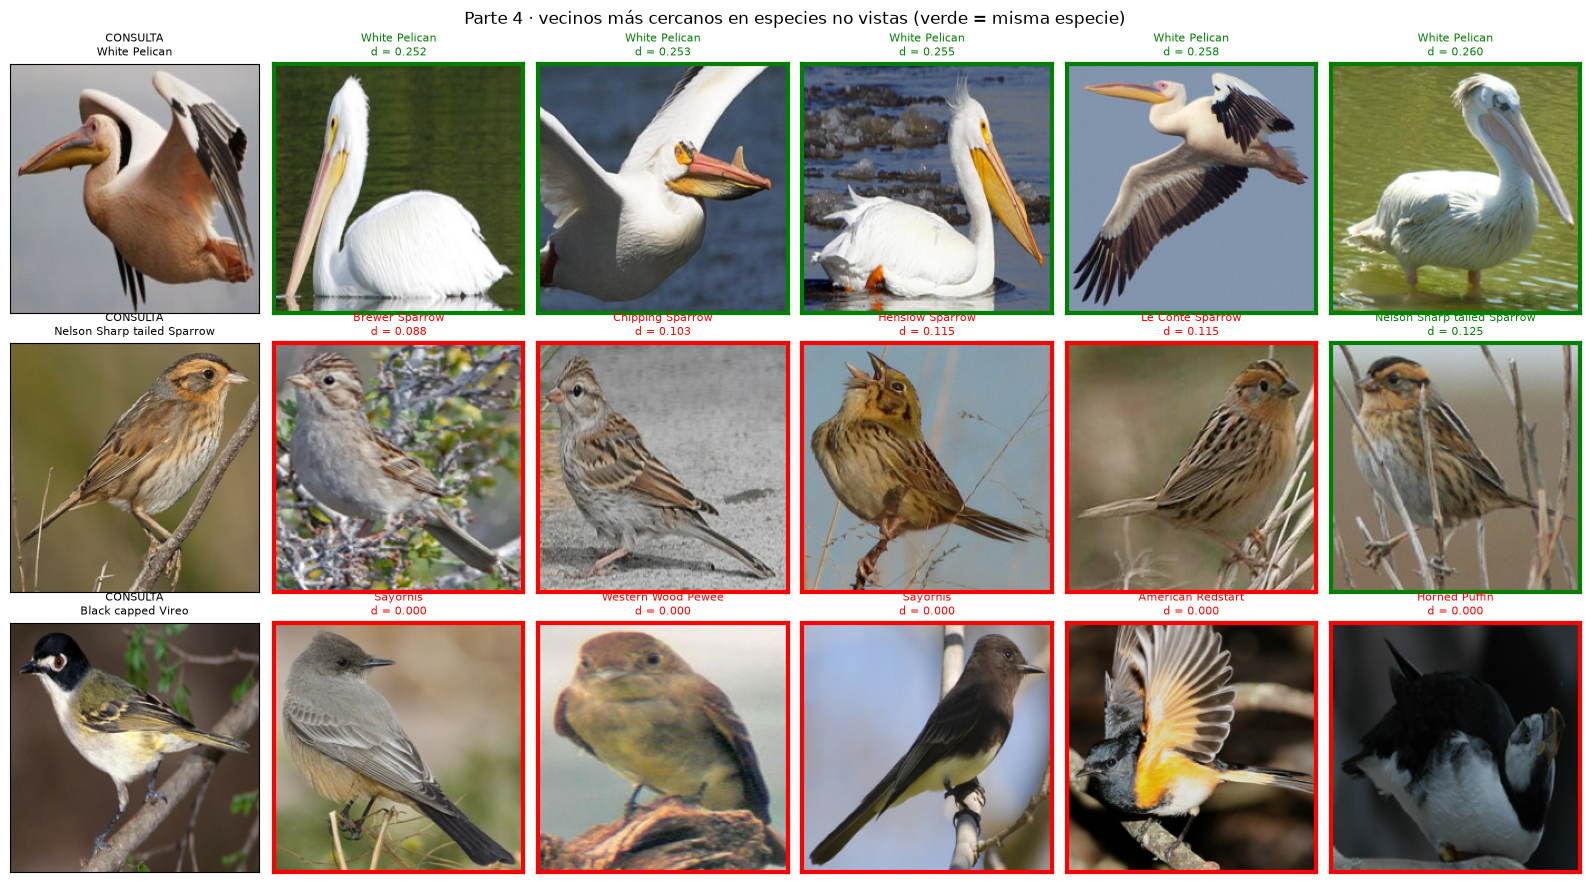

In [36]:
def few_shot_acc(Z, y, shots, seed=SEED):
    rng = np.random.default_rng(seed); refs, queries = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c)); refs.append(idx[:shots]); queries.append(idx[shots:])
    classes = np.unique(y)
    protos = F.normalize(torch.stack([Z[torch.as_tensor(r, device=Z.device)].mean(0) for r in refs]), dim=1)
    q = torch.as_tensor(np.concatenate(queries), device=Z.device)
    pred = classes[(Z[q] @ protos.T).argmax(1).cpu().numpy()]
    return float(np.mean(pred == y[q.cpu().numpy()]))

y_test_np = LABELS[SIA["test"]]
fs_rows = []
for name, Z in [("ResNet50 sin entrenar", raw_test), (f"Siamesa {BEST_SIA_KEY[0]} + {BEST_SIA_KEY[1]}", embed_rows(best_model, SIA["test"]))]:
    fs_rows.append({"embedding": name, "1-shot acc (100 especies)": few_shot_acc(Z, y_test_np, 1),
                    "5-shot acc (100 especies)": few_shot_acc(Z, y_test_np, 5)})
fs = pd.DataFrame(fs_rows).set_index("embedding"); fs.to_csv(TAB_DIR / "p4_few_shot.csv")
display(fs.style.format("{:.4f}").set_caption("Clasificación de especies no vistas por referencia (azar = 0.01)"))

Zt_best = embed_rows(best_model, SIA["test"])
S = Zt_best @ Zt_best.T; S.fill_diagonal_(-float("inf"))
q_local = [0, 1500, 3000]
fig, axes = plt.subplots(len(q_local), 6, figsize=(16, 3.0 * len(q_local)))
for r_i, ql in enumerate(q_local):
    nn_idx = S[ql].topk(5).indices.cpu().numpy()
    qrow = SIA["test"][ql]
    axes[r_i, 0].imshow(load_crop(qrow)); axes[r_i, 0].set_title(f"CONSULTA\n{CLASS_NAMES[LABELS[qrow]]}", fontsize=8)
    for j, nn_i in enumerate(nn_idx):
        row = SIA["test"][nn_i]; ok = LABELS[row] == LABELS[qrow]
        d = float(torch.sqrt((2 - 2 * S[ql, nn_i]).clamp_min(0)))
        ax = axes[r_i, j + 1]; ax.imshow(load_crop(row))
        ax.set_title(f"{CLASS_NAMES[LABELS[row]]}\nd = {d:.3f}", fontsize=8, color="green" if ok else "red")
        for sp in ax.spines.values(): sp.set_edgecolor("green" if ok else "red"); sp.set_linewidth(3)
    for ax in axes[r_i]: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Parte 4 · vecinos más cercanos en especies no vistas (verde = misma especie)"); fig.tight_layout()
save_fig(fig, "p4_vecinos_ejemplo"); plt.show()

**Interpretación de resultados (Parte 4).**

*Resultados en especies no vistas (101–200, 5.924 imágenes).* Con el margen elegido en validación, el Recall@1 en test es de **36,41 %** para triplet + batch-hard (m = 0,1), **35,36 %** para triplet + aleatorio (m = 0,3), **19,99 %** para contrastive + aleatorio (m = 1,0) y **19,06 %** para contrastive + batch-hard (m = 1,0). El azar sería ≈ 1 %. Pero la **línea base sin entrenar** (embedding ResNet50 normalizado) obtiene **53,09 %** de R@1 y 86,21 % de R@8. Ningún encoder siamés la supera en test.

*Diagnóstico.* La tabla de generalización muestra que **no es un error de implementación**:

- Las comprobaciones previas pasan: la exclusión de la propia imagen da R@1 = 0,018 con vectores aleatorios, y las particiones son disjuntas.
- En **validación** (imágenes nuevas de las especies vistas) los encoders mejoran mucho la línea base: la ResNet50 sin entrenar obtiene 54,5 % y las mejores configuraciones 74,4 % (+20 pp). En train llegan a R@1 ≈ 0,99–1,0.
- En las especies **no vistas** la mejora se convierte en pérdida (−17 a −34 pp).

La cabeza `Dense(512) → Dense(128)`, con ~1,1 M de parámetros y unas 5.300 imágenes de entrenamiento de 100 especies, aprende una proyección **especializada en las especies de entrenamiento**: conserva las direcciones del embedding que separan esas 100 especies y descarta las que distinguirían otras. Esta es la advertencia de Musgrave, Belongie y Lim (2020). Si la validación usa las **mismas especies** que el entrenamiento (como exige el protocolo del enunciado: el 10 % de las imágenes de las especies 1–100), la selección de modelo no mide la transferencia a especies nuevas, que es precisamente lo que se evalúa en test. Una validación con especies disjuntas lo habría detectado (sección 13). Con el *backbone* congelado, la línea base ResNet50 ya es una métrica muy fuerte para aves (sus rasgos de ImageNet son genéricos) y es difícil de mejorar sin ajustar la red completa.

*¿Qué pérdida y qué muestreo funcionaron mejor, y por qué?*

- **Pérdida: triplet** supera claramente a contrastive en test (≈ 36 % frente a ≈ 20 % de R@1). La contrastive obliga a que **todos** los positivos estén a distancia 0, lo que **colapsa la variabilidad intraespecie**, justo la información que podría servir para especies nuevas. La triplet solo exige una restricción **relativa** (d(a,p) + m < d(a,n)). Con un margen pequeño (m = 0,1–0,3 sobre la esfera unidad, d ∈ [0, 2]) deja más libertad a la geometría y sobreajusta menos.
- **Muestreo: batch-hard** es mejor en **validación** (+9 pp con contrastive y +7 pp con triplet) y converge antes: mejor época 22–47, frente a 35–96 con muestreo aleatorio. En un dataset de grano fino, la mayoría de los negativos aleatorios ya están lejos y no aportan gradiente; el negativo más cercano del batch (una especie hermana) es el informativo. En test, la ventaja de batch-hard se reduce a +1,05 pp con triplet y desaparece con contrastive (−0,93 pp): explotar negativos difíciles de las especies vistas también acelera la especialización.
- La selección por validación empató en R@1 = 0,7445 entre contrastive + batch-hard (m = 1,0) y triplet + batch-hard (m = 0,1 y 0,3). El orden de la rejilla eligió contrastive + batch-hard, que es justo la peor configuración en test. Esto refuerza que la validación sobre especies vistas no informa de la generalización.

*¿En qué se diferencia de un clasificador de 200 clases y qué permite hacer que un clasificador no puede?* Un clasificador aprende una función $f: x \mapsto$ distribución sobre un **conjunto cerrado** de especies. Su capa de salida tiene una neurona por especie y, para añadir una especie nueva, hay que cambiar la arquitectura y reentrenar con ejemplos etiquetados. La red siamesa aprende una **función de distancia** $d(x, x')$ que no depende de ninguna lista de especies. Eso permite:

1. reconocer especies **nunca vistas** comparándolas con una o pocas fotos de referencia (*few-shot*);
2. **verificar** si dos fotos son de la misma especie;
3. hacer **búsqueda por similitud** (vecinos más cercanos) y agrupar imágenes sin etiquetas.

La tabla *few-shot* lo cuantifica en las 100 especies no vistas (azar = 1 %). Con una sola foto de referencia por especie, el embedding ResNet50 acierta el 24,45 % y con cinco, el 46,40 %. El encoder siamés elegido en validación (contrastive + batch-hard) acierta el 12,64 % y el 17,75 %. El mecanismo funciona, pero en este experimento el espacio que mejor transfiere es el preentrenado.

*Proyección 2D.* En las especies 101–110, ambos espacios separan bien las especies con un aspecto muy distintivo (*White Pelican*, *Whip-poor-Will*, *Horned Puffin*). También mezclan las mismas parejas difíciles: los mosqueros *Western Wood-Pewee* / *Sayornis* y los cuervos *Common Raven* / *White-necked Raven*. La diferencia está en la forma de los grupos. Con la ResNet50 sin entrenar, el t-SNE muestra grupos compactos y redondeados. Con el encoder siamés (contrastive + batch-hard), varios grupos se estiran o se dispersan (*Geococcyx*, *American Redstart*, *Horned Puffin* en PCA). Eso es coherente con una proyección afinada para otras especies, que no ordena bien la variabilidad interna de estas. Una proyección 2D de 10 especies es solo ilustrativa: la comparación cuantitativa es la tabla de Recall@K.

---
# 9. Parte 5 — Modelo tipo CLIP imagen–texto con especies no vistas

**Pregunta:** ¿se pueden clasificar especies nunca vistas a partir de texto?

## 9.1 Partición *zero-shot* de Reed et al. (2016)

El archivo de AttnGAN que ya usamos en la Tarea 1 incluye las listas de imágenes `birds/train/filenames.pickle` y `birds/test/filenames.pickle`, que siguen la partición por clases de Reed et al. (2016): **150 especies de entrenamiento y 50 de evaluación**. Leemos esos *pickles* con un `Unpickler` restringido que **prohíbe cargar cualquier clase u objeto de código** (solo admite listas de cadenas), porque deserializar un *pickle* arbitrario descargado de Internet podría ejecutar código. Después verificamos que las especies sean exactamente 150 + 50 y disjuntas. Si las listas no estuvieran disponibles, la celda usa automáticamente el split alternativo permitido por el enunciado (especies 1–150 y 151–200) y lo indica.

- **Entrenamiento:** imágenes de las 150 especies de entrenamiento, excepto el 10 % estratificado para **validación** (`random_state=42`).
- **Evaluación:** todas las imágenes de las 50 especies no vistas.

**Vocabulario sin fuga de información.** El vocabulario de la Tarea 1 se ajustó con imágenes de las 200 especies, y por tanto incluye palabras que solo aparecen en las captions de las 50 especies de evaluación. Para CLIP se construye un **vocabulario nuevo** con la misma regla (frecuencia ≥ 2, orden alfabético, `<pad>=0`, `<unk>=1`, `max_len` = percentil 95), **ajustado solo con las captions de las imágenes de entrenamiento de las 150 especies**. El vocabulario de la Tarea 1 se conserva sin cambios para las partes 1–3.

In [37]:
class SafeListUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        raise pickle.UnpicklingError(f"Objeto no permitido en el pickle: {module}.{name}")

def read_reed_split():
    out = {}
    try:
        with zipfile.ZipFile(ATTNGAN_ZIP) as zf:
            for s in ["train", "test"]:
                data = SafeListUnpickler(__import__("io").BytesIO(zf.read(f"birds/{s}/filenames.pickle")), encoding="latin1").load()
                assert isinstance(data, list) and all(isinstance(x, str) for x in data)
                out[s] = sorted({int(x.split("/")[0].split(".")[0]) for x in data})
    except Exception as e:
        log(f"⚠ No se pudieron leer las listas de Reed ({e})."); return None
    return out

reed = read_reed_split()
if reed and len(reed["train"]) == 150 and len(reed["test"]) == 50 and not set(reed["train"]) & set(reed["test"]):
    CLIP_TRAIN_CLASSES, CLIP_TEST_CLASSES, CLIP_SPLIT_SOURCE = set(reed["train"]), set(reed["test"]), "Reed et al. (2016) vía AttnGAN"
else:
    CLIP_TRAIN_CLASSES, CLIP_TEST_CLASSES, CLIP_SPLIT_SOURCE = set(range(1, 151)), set(range(151, 201)), "ALTERNATIVO: especies 1–150 / 151–200"
log(f"Split zero-shot: {CLIP_SPLIT_SOURCE}")
print("Especies de evaluación (no vistas):", ", ".join(CLASS_NAMES[c - 1] for c in sorted(CLIP_TEST_CLASSES)))

pool = np.flatnonzero(np.isin(CLASS_ID, list(CLIP_TRAIN_CLASSES)))
CL = {}
CL["train"], CL["val"] = train_test_split(pool, test_size=0.10, stratify=CLASS_ID[pool], random_state=SEED)
CL["test"] = np.flatnonzero(np.isin(CLASS_ID, list(CLIP_TEST_CLASSES)))
for s in CL: CL[s] = np.sort(CL[s])
assert set(CLASS_ID[CL["test"]]).isdisjoint(set(CLASS_ID[CL["train"]]) | set(CLASS_ID[CL["val"]]))
assert not (set(CL["train"]) & set(CL["val"])) and len(set(CLASS_ID[CL["test"]])) == 50

clip_tokens_train = [t for caps in image_table["caption_tokens"].iloc[CL["train"]] for t in caps]
clip_vocab, _ = build_vocab(clip_tokens_train)
_cl = np.array([len(t) for t in clip_tokens_train]); clip_max_len = max(1, int(np.ceil(np.percentile(_cl, 95))))
CLIP_CAPS, CLIP_LENS = encode_all(image_table, clip_vocab, clip_max_len)
test_words = Counter(w for caps in image_table["caption_tokens"].iloc[CL["test"]] for t in caps for w in t)
oov_rate = sum(c for w, c in test_words.items() if w not in clip_vocab) / sum(test_words.values())
t1_only = sorted(set(vocab) - set(clip_vocab))
display(pd.DataFrame({s: {"imágenes": len(r), "especies": len(set(CLASS_ID[r]))} for s, r in CL.items()}).T)
display(pd.Series({"fuente del split": CLIP_SPLIT_SOURCE, "|V| CLIP (solo train 150 especies)": len(clip_vocab),
                   "|V| Tarea 1": len(vocab), "palabras del vocab. T1 ausentes en el de CLIP": len(t1_only),
                   "max_len CLIP": clip_max_len, "% tokens de test fuera del vocabulario CLIP": round(100 * oov_rate, 2)}).to_frame("valor"))

Split zero-shot: Reed et al. (2016) vía AttnGAN
Especies de evaluación (no vistas): Black footed Albatross, Groove billed Ani, Least Auklet, Rhinoceros Auklet, Brewer Blackbird, Indigo Bunting, Brandt Cormorant, American Crow, Black billed Cuckoo, Yellow billed Cuckoo, Gray crowned Rosy Finch, Purple Finch, Northern Flicker, Acadian Flycatcher, Great Crested Flycatcher, Yellow bellied Flycatcher, Boat tailed Grackle, Horned Grebe, Western Grebe, Western Gull, Pomarine Jaeger, Belted Kingfisher, White breasted Kingfisher, Red legged Kittiwake, Pacific Loon, Mockingbird, Baltimore Oriole, Hooded Oriole, Scott Oriole, White Pelican, Western Wood Pewee, Sayornis, Great Grey Shrike, Black throated Sparrow, Field Sparrow, Grasshopper Sparrow, Tree Sparrow, Bank Swallow, Tree Swallow, Least Tern, White eyed Vireo, Cape May Warbler, Chestnut sided Warbler, Golden winged Warbler, Wilson Warbler, Northern Waterthrush, Bohemian Waxwing, Cedar Waxwing, American Three toed Woodpecker, Marsh Wren


,imágenes,especies
train,7969,150
val,886,150
test,2933,50


,valor
fuente del split,Reed et al. (2016) vía AttnGAN
|V| CLIP (solo train 150 especies),2528
|V| Tarea 1,2079
palabras del vocab. T1 ausentes en el de CLIP,150
max_len CLIP,24
% tokens de test fuera del vocabulario CLIP,0.27


## 9.2 Arquitectura y pérdida

Dos encoders **sin pesos compartidos** proyectan cada modalidad a un espacio común $\mathbb{S}^{255}$:

- **Imagen:** `emb ResNet50 (2048) → Dense(512, ReLU) → Dropout(0.1) → Dense(256) → L2`.
- **Texto:** `Embedding(|V|, 256, padding_idx=0) → Dropout(0.2) → BiLSTM(256) → [h→ ; h←] (512) → Dense(256) → L2`. Se usa `pack_padded_sequence` con las longitudes reales, de modo que el estado final de cada dirección corresponde al último token **válido**: el padding no interviene.

Para un batch de $B$ pares (imagen $i$, una de sus captions):

$$S_{ij}=\frac{\mathbf z^{\text{img}}_i\cdot\mathbf z^{\text{txt}}_j}{\tau},\qquad \mathcal L = \tfrac12\big[\operatorname{CE}(S, I)+\operatorname{CE}(S^\top, I)\big],$$

donde $\operatorname{CE}(S,I)=-\frac1B\sum_i \log\frac{e^{S_{ii}}}{\sum_j e^{S_{ij}}}$: cada fila (imagen) debe identificar su caption entre las $B$ del batch, y cada columna (caption) su imagen. Esta es la InfoNCE simétrica (Oord et al., 2018; Radford et al., 2021).

- **Temperatura aprendible:** se aprende $\log(1/\tau)$, inicializado en $\log(1/0.07)$. Tras cada paso se recorta para que $1/\tau\le 100$.
- **Las etiquetas de especie no intervienen en la pérdida:** los positivos son solo los pares imagen–caption propios. Dos imágenes de la misma especie en un batch actúan como negativos («falsos negativos»), una limitación conocida del enfoque.
- **Batches de tamaño fijo** $B=256$ con `drop_last=True`. En cada época, cada imagen se empareja con **una de sus 10 captions elegida al azar**.
- **Validación:** caption 0 de cada imagen, en un orden barajado una vez (fijo) y con batches de 256 completos, para que la pérdida de validación sea comparable entre épocas.
- **Optimización:** AdamW con lr = 1e-3 y *weight decay* 1e-4, hasta 100 épocas, *early stopping* con paciencia de 10 sobre la pérdida de validación y *checkpoint* del mejor modelo.

In [38]:
from torch.nn.utils.rnn import pack_padded_sequence

class ImageProj(nn.Module):
    def __init__(self, d=256):
        super().__init__(); self.net = nn.Sequential(nn.Linear(2048, 512), nn.ReLU(), nn.Dropout(0.1), nn.Linear(512, d))
    def forward(self, x): return F.normalize(self.net(x), dim=1)

class TextEncoder(nn.Module):
    def __init__(self, vocab_size, emb=256, hidden=256, d=256):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0); self.drop = nn.Dropout(0.2)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.proj = nn.Linear(2 * hidden, d)
    def forward(self, ids, lens):
        packed = pack_padded_sequence(self.drop(self.emb(ids)), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                     # h: (2, B, hidden) = último paso válido de cada dirección
        return F.normalize(self.proj(torch.cat([h[0], h[1]], 1)), dim=1)

class CLIPLike(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.img, self.txt = ImageProj(), TextEncoder(vocab_size)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
    def forward(self, x, ids, lens):
        zi, zt = self.img(x), self.txt(ids, lens)
        return zi, zt, self.logit_scale.exp()

def clip_loss(zi, zt, scale):
    S = scale * zi @ zt.T; target = torch.arange(len(zi), device=zi.device)
    return 0.5 * (F.cross_entropy(S, target) + F.cross_entropy(S.T, target))

CAPS_T = torch.tensor(CLIP_CAPS, device=DEVICE); LENS_T = torch.tensor(CLIP_LENS, device=DEVICE)

def clip_batches(rows, cap_idx, bs=256, shuffle_rng=None):
    order = shuffle_rng.permutation(len(rows)) if shuffle_rng is not None else np.arange(len(rows))
    for b in range(len(rows) // bs):                     # drop_last
        sel = order[b * bs:(b + 1) * bs]; r = torch.as_tensor(rows[sel], device=DEVICE); c = torch.as_tensor(cap_idx[sel], device=DEVICE)
        yield EMB_T[r], CAPS_T[r, c], LENS_T[r, c]

def train_clip(max_epochs=100, patience=10, lr=1e-3, bs=256):
    ck, hpath = CKPT_DIR / "p5_clip" / "best.pt", HIST_DIR / "p5_clip.json"; ck.parent.mkdir(parents=True, exist_ok=True)
    max_epochs = EPOCH_CAP or max_epochs
    if ck.is_file() and hpath.is_file() and not FORCE_RETRAIN:
        m = CLIPLike(len(clip_vocab)).to(DEVICE); m.load_state_dict(torch.load(ck, map_location=DEVICE))
        log("✓ CLIP: checkpoint recuperado"); return m, json.loads(hpath.read_text())
    set_all_seeds(SEED); model = CLIPLike(len(clip_vocab)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    rng = np.random.default_rng(SEED)
    val_rows = CL["val"][np.random.default_rng(SEED + 1).permutation(len(CL["val"]))]
    hist = {"loss": [], "val_loss": [], "inv_tau": []}; best, wait, t0 = float("inf"), 0, time.time()
    for ep in range(max_epochs):
        model.train(); losses = []
        cap_idx = rng.integers(0, 10, len(CL["train"]))                 # caption aleatoria por imagen y época
        for x, ids, lens in clip_batches(CL["train"], cap_idx, bs, rng):
            loss = clip_loss(*model(x, ids, lens))
            if not torch.isfinite(loss): raise FloatingPointError(f"CLIP: pérdida no finita en época {ep+1}")
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): model.logit_scale.clamp_(0, math.log(100))
            losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vl = [clip_loss(*model(x, ids, lens)).item() for x, ids, lens in clip_batches(val_rows, np.zeros(len(val_rows), int), bs)]
        hist["loss"].append(float(np.mean(losses))); hist["val_loss"].append(float(np.mean(vl)))
        hist["inv_tau"].append(model.logit_scale.exp().item())
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  época {ep+1:3d} | loss {hist['loss'][-1]:.4f} | val_loss {hist['val_loss'][-1]:.4f} | 1/τ {hist['inv_tau'][-1]:.2f} | {time.time()-t0:.0f}s")
        if hist["val_loss"][-1] < best:
            best, wait = hist["val_loss"][-1], 0; torch.save(model.state_dict(), ck)
        else:
            wait += 1
            if wait >= patience: break
    hist["_meta"] = {"epochs_run": len(hist["loss"]), "best_epoch": int(np.argmin(hist["val_loss"])) + 1, "best_val_loss": best,
                     "train_seconds": time.time() - t0, "lr": lr, "batch_size": bs, "batches_per_epoch": len(CL["train"]) // bs,
                     "params": sum(p.numel() for p in model.parameters()), "split": CLIP_SPLIT_SOURCE}
    hpath.write_text(json.dumps(hist, indent=2))
    model.load_state_dict(torch.load(ck, map_location=DEVICE)); return model, hist

clip_model, clip_hist = train_clip()
clip_model.eval()
EXPERIMENTS["p5_clip"] = {"framework": "PyTorch"} | clip_hist["_meta"]
print(f"Parámetros: {clip_hist['_meta']['params']:,} · mejor época {clip_hist['_meta']['best_epoch']} de {clip_hist['_meta']['epochs_run']} · "
      f"1/τ final del mejor modelo = {clip_model.logit_scale.exp().item():.2f}")

✓ CLIP: checkpoint recuperado
Parámetros: 3,011,585 · mejor época 15 de 25 · 1/τ final del mejor modelo = 15.42


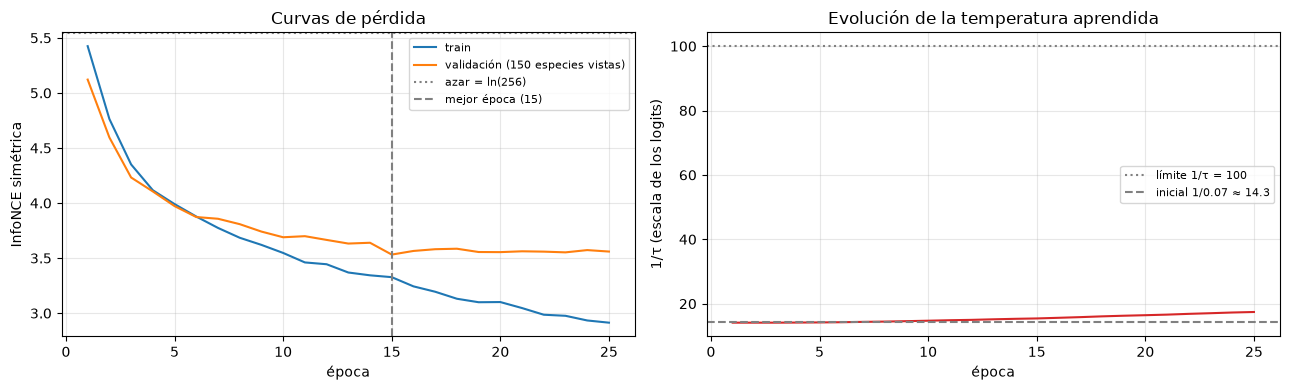

In [39]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
ep = np.arange(1, len(clip_hist["loss"]) + 1); be = clip_hist["_meta"]["best_epoch"]
a1.plot(ep, clip_hist["loss"], label="train"); a1.plot(ep, clip_hist["val_loss"], label="validación (150 especies vistas)")
a1.axhline(math.log(256), color="gray", ls=":", label="azar = ln(256)"); a1.axvline(be, color="gray", ls="--", label=f"mejor época ({be})")
a1.set_xlabel("época"); a1.set_ylabel("InfoNCE simétrica"); a1.set_title("Curvas de pérdida"); a1.legend(fontsize=8)
a2.plot(ep, clip_hist["inv_tau"], color="C3"); a2.axhline(100, color="gray", ls=":", label="límite 1/τ = 100")
a2.axhline(1 / 0.07, color="gray", ls="--", label="inicial 1/0.07 ≈ 14.3")
a2.set_xlabel("época"); a2.set_ylabel("1/τ (escala de los logits)"); a2.set_title("Evolución de la temperatura aprendida"); a2.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "p5_curvas_perdida_temperatura"); plt.show()

## 9.3 Evaluación *zero-shot* en las 50 especies no vistas

**Protocolo del enunciado.** El prototipo textual de cada especie $c$ es el promedio, renormalizado, de los embeddings de **todas** sus captions:

$$\mathbf t_c = \frac{\sum_{i\in c}\sum_{j=1}^{10}\mathbf z^{\text{txt}}_{ij}}{\big\|\sum_{i\in c}\sum_{j=1}^{10}\mathbf z^{\text{txt}}_{ij}\big\|_2},\qquad \hat y(i)=\arg\max_c\;\mathbf z^{\text{img}}_i\cdot\mathbf t_c.$$

**Limitación metodológica.** En este protocolo, las 10 captions **de la propia imagen evaluada** forman parte del prototipo de su especie, lo que puede inflar ligeramente la accuracy (son unas 600 captions por especie, así que la contribución de una imagen ronda el 1/60). Además del protocolo solicitado, se reportan dos comprobaciones más estrictas:

1. **Leave-one-image-out:** para cada imagen, el prototipo de **su** especie se recalcula sin sus 10 captions.
2. **Mitades disjuntas:** las imágenes de cada especie se dividen al azar en dos mitades. Los prototipos se construyen solo con las captions de la mitad A y se evalúan solo las imágenes de la mitad B.

El azar es 1/50 = 2 % en top-1 y 5/50 = 10 % en top-5.

In [40]:
@torch.no_grad()
def encode_clip_images(rows): return clip_model.img(EMB_T[torch.as_tensor(rows, device=DEVICE)])
@torch.no_grad()
def encode_clip_texts(ids, lens, bs=2048):
    return torch.cat([clip_model.txt(ids[i:i + bs], lens[i:i + bs]) for i in range(0, len(ids), bs)])

te = CL["test"]; y_te = LABELS[te]; te_classes = np.unique(y_te)
ZI = encode_clip_images(te)                                                       # (N,256)
r_t = torch.as_tensor(te, device=DEVICE)
ZT = encode_clip_texts(CAPS_T[r_t].reshape(-1, clip_max_len), LENS_T[r_t].reshape(-1)).reshape(len(te), 10, -1)
cls_pos = {c: k for k, c in enumerate(te_classes)}; y_pos = torch.as_tensor([cls_pos[c] for c in y_te], device=DEVICE)
sums = torch.stack([ZT[torch.as_tensor(np.flatnonzero(y_te == c), device=DEVICE)].sum((0, 1)) for c in te_classes])
PROTOS = F.normalize(sums, dim=1)

def zs_acc(S, y):
    top = S.topk(5, dim=1).indices
    return {"top-1": float((top[:, 0] == y).float().mean()), "top-5": float((top == y[:, None]).any(1).float().mean())}

S_full = ZI @ PROTOS.T
res_proto = zs_acc(S_full, y_pos)
# Leave-one-image-out
own = F.normalize(sums[y_pos] - ZT.sum(1), dim=1)
S_loo = S_full.clone(); S_loo[torch.arange(len(te)), y_pos] = (ZI * own).sum(1)
res_loo = zs_acc(S_loo, y_pos)
# Mitades disjuntas
rng_h = np.random.default_rng(SEED); half_A = np.zeros(len(te), bool)
for c in te_classes:
    idx = rng_h.permutation(np.flatnonzero(y_te == c)); half_A[idx[: len(idx) // 2]] = True
protos_A = F.normalize(torch.stack([ZT[torch.as_tensor(np.flatnonzero((y_te == c) & half_A), device=DEVICE)].sum((0, 1)) for c in te_classes]), dim=1)
mB = torch.as_tensor(~half_A, device=DEVICE)
res_half = zs_acc(ZI[mB] @ protos_A.T, y_pos[mB])

zs = pd.DataFrame({"Protocolo del enunciado (todas las captions)": res_proto,
                   "Leave-one-image-out": res_loo, "Mitades disjuntas (prototipos A → imágenes B)": res_half,
                   "Azar": {"top-1": 1 / 50, "top-5": 5 / 50}}).T
zs["top-1 / azar"] = zs["top-1"] / 0.02
zs.to_csv(TAB_DIR / "p5_zero_shot.csv")
display(zs.style.format("{:.4f}").set_caption(f"Parte 5 · clasificación zero-shot en {len(te_classes)} especies no vistas ({len(te)} imágenes)"))

per_class = pd.DataFrame({"especie": [CLASS_NAMES[c] for c in te_classes],
                          "acc top-1": [float((S_full.argmax(1)[y_pos == k] == k).float().mean()) for k in range(len(te_classes))]})
per_class = per_class.sort_values("acc top-1", ascending=False).reset_index(drop=True); per_class.to_csv(TAB_DIR / "p5_acc_por_especie.csv", index=False)
print("Mejores y peores especies no vistas (top-1):")
display(pd.concat([per_class.head(5), per_class.tail(5)]))

,top-1,top-5,top-1 / azar
Protocolo del enunciado (todas las captions),0.5629,0.8984,28.1452
Leave-one-image-out,0.5561,0.8940,27.8043
Mitades disjuntas (prototipos A → imágenes B),0.5530,0.8933,27.6495
Azar,0.0200,0.1000,1.0000


Mejores y peores especies no vistas (top-1):


,especie,acc top-1
0,Purple Finch,1.000000
1,Indigo Bunting,0.983333
2,White Pelican,0.980000
3,White breasted Kingfisher,0.950000
4,Horned Grebe,0.916667
45,Mockingbird,0.166667
46,Tree Sparrow,0.100000
47,Sayornis,0.066667
48,Bank Swallow,0.050847
49,Grasshopper Sparrow,0.033333


## 9.4 Recuperación multimodal y Precision@10

**Definición de relevancia:** un elemento recuperado es **relevante si pertenece a la misma especie** que la consulta. La galería y las consultas provienen **solo de las 50 especies no vistas**.

- **Texto → imagen:** la consulta es la caption 0 de cada imagen de test (una por imagen) y la galería son todas las imágenes de test. La imagen de origen de la caption está en la galería, y también es relevante, porque es de la misma especie.
- **Imagen → texto:** la consulta es cada imagen de test y la galería son todas las captions de test (10 por imagen), **excluyendo las 10 captions de la propia imagen**, para medir la generalización a descripciones de otros ejemplares.

$$\text{P@10}=\frac{1}{|Q|}\sum_{q\in Q}\frac{\big|\{r\in\text{top-10}(q):\ \text{especie}(r)=\text{especie}(q)\}\big|}{10}.$$

El valor esperado al azar es aproximadamente la proporción de la especie en la galería, en torno a 1/50.

In [41]:
@torch.no_grad()
def precision_at_10_t2i():
    q = ZT[:, 0]; S = q @ ZI.T
    top = S.topk(10, dim=1).indices
    return float((y_pos[top] == y_pos[:, None]).float().mean())

@torch.no_grad()
def precision_at_10_i2t(chunk=512):
    G = ZT.reshape(-1, ZT.shape[-1]); g_img = torch.arange(len(te), device=DEVICE).repeat_interleave(10); g_y = y_pos[g_img]
    hits = []
    for s in range(0, len(te), chunk):
        S = ZI[s:s + chunk] @ G.T
        own_mask = g_img[None, :] == torch.arange(s, min(s + chunk, len(te)), device=DEVICE)[:, None]
        S = S.masked_fill(own_mask, -float("inf"))            # excluir las captions de la propia imagen
        top = S.topk(10, dim=1).indices
        hits.append((g_y[top] == y_pos[s:s + chunk, None]).float().mean(1))
    return float(torch.cat(hits).mean())

chance = float(np.mean([(y_te == c).mean() for c in y_te]))
retr = pd.DataFrame({"P@10": {"texto → imagen": precision_at_10_t2i(), "imagen → texto": precision_at_10_i2t(), "azar (≈ E[proporción de la especie])": chance}})
retr.to_csv(TAB_DIR / "p5_recuperacion_p10.csv")
display(retr.style.format("{:.4f}").set_caption("Parte 5 · Precision@10 (relevante = misma especie; solo especies no vistas)"))
CLIP_RESULTS = {"zero_shot": zs.drop(columns="top-1 / azar").to_dict(orient="index"), "retrieval": retr["P@10"].to_dict(),
                "split": CLIP_SPLIT_SOURCE, "n_test_images": int(len(te)), "n_test_classes": int(len(te_classes)),
                "clip_vocab_size": len(clip_vocab), "clip_max_len": clip_max_len, "final_inv_tau": clip_model.logit_scale.exp().item()}
save_json(CLIP_RESULTS, MET_DIR / "p5_clip.json")

,P@10
texto → imagen,0.2569
imagen → texto,0.3374
azar (≈ E[proporción de la especie]),0.0201


## 9.5 Matriz de similitudes de un batch

Se toman 16 imágenes de **16 especies distintas**: un batch de validación (especies vistas) y uno de test (especies **no vistas**). Cada imagen se empareja con su caption 0. La celda $(i,j)$ muestra el coseno $\mathbf z^{\text{img}}_i\cdot\mathbf z^{\text{txt}}_j$. Si el modelo alinea bien las modalidades, la diagonal (pares correctos) debe destacar.

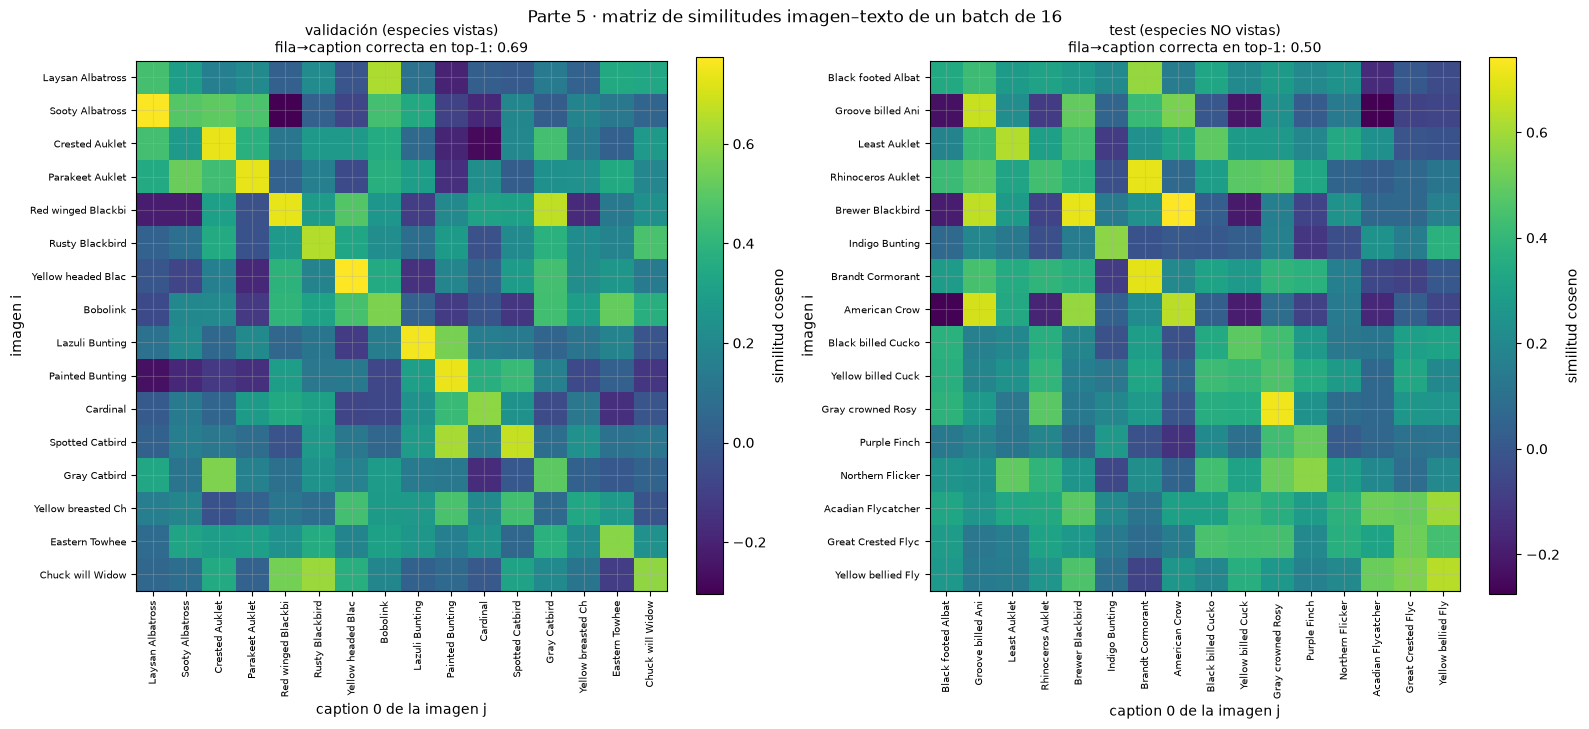

In [42]:
def first_per_class(rows, n=16):
    seen, out = set(), []
    for r in rows:
        if LABELS[r] not in seen: seen.add(LABELS[r]); out.append(r)
        if len(out) == n: break
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))
for ax, (rows, title) in zip(axes, [(first_per_class(CL["val"]), "validación (especies vistas)"), (first_per_class(CL["test"]), "test (especies NO vistas)")]):
    rt = torch.as_tensor(rows, device=DEVICE)
    with torch.no_grad():
        S = (clip_model.img(EMB_T[rt]) @ clip_model.txt(CAPS_T[rt, 0], LENS_T[rt, 0]).T).cpu().numpy()
    im = ax.imshow(S, cmap="viridis"); plt.colorbar(im, ax=ax, fraction=0.046, label="similitud coseno")
    names = [CLASS_NAMES[LABELS[r]][:18] for r in rows]
    ax.set_xticks(range(16), names, rotation=90, fontsize=7); ax.set_yticks(range(16), names, fontsize=7)
    ax.set_xlabel("caption 0 de la imagen j"); ax.set_ylabel("imagen i")
    diag_rank1 = float(np.mean(S.argmax(1) == np.arange(16)))
    ax.set_title(f"{title}\nfila→caption correcta en top-1: {diag_rank1:.2f}", fontsize=10)
fig.suptitle("Parte 5 · matriz de similitudes imagen–texto de un batch de 16"); fig.tight_layout()
save_fig(fig, "p5_matriz_similitudes"); plt.show()

## 9.6 Tres consultas textuales originales (texto → imagen)

Las tres consultas siguientes fueron **propuestas por el asistente y aprobadas por los autores** antes de la ejecución:

1. *«a small bird with a bright red head and black wings»*
2. *«a large bird with a long hooked beak and white belly»*
3. *«a small yellow bird with black streaks on its breast»*

Cada consulta se tokeniza con la función de la Tarea 1 y se codifica con el **vocabulario de CLIP** (se informa si alguna palabra queda fuera, como `<unk>`). Después se compara con **todas y solo** las imágenes de las 50 especies no vistas, usando el modelo realmente entrenado. Se muestran las 5 imágenes más similares con su puntuación coseno y su especie real.

Consulta 1: «a small bird with a bright red head and black wings» · tokens fuera del vocabulario CLIP: ninguno
Consulta 2: «a large bird with a long hooked beak and white belly» · tokens fuera del vocabulario CLIP: ninguno
Consulta 3: «a small yellow bird with black streaks on its breast» · tokens fuera del vocabulario CLIP: ninguno


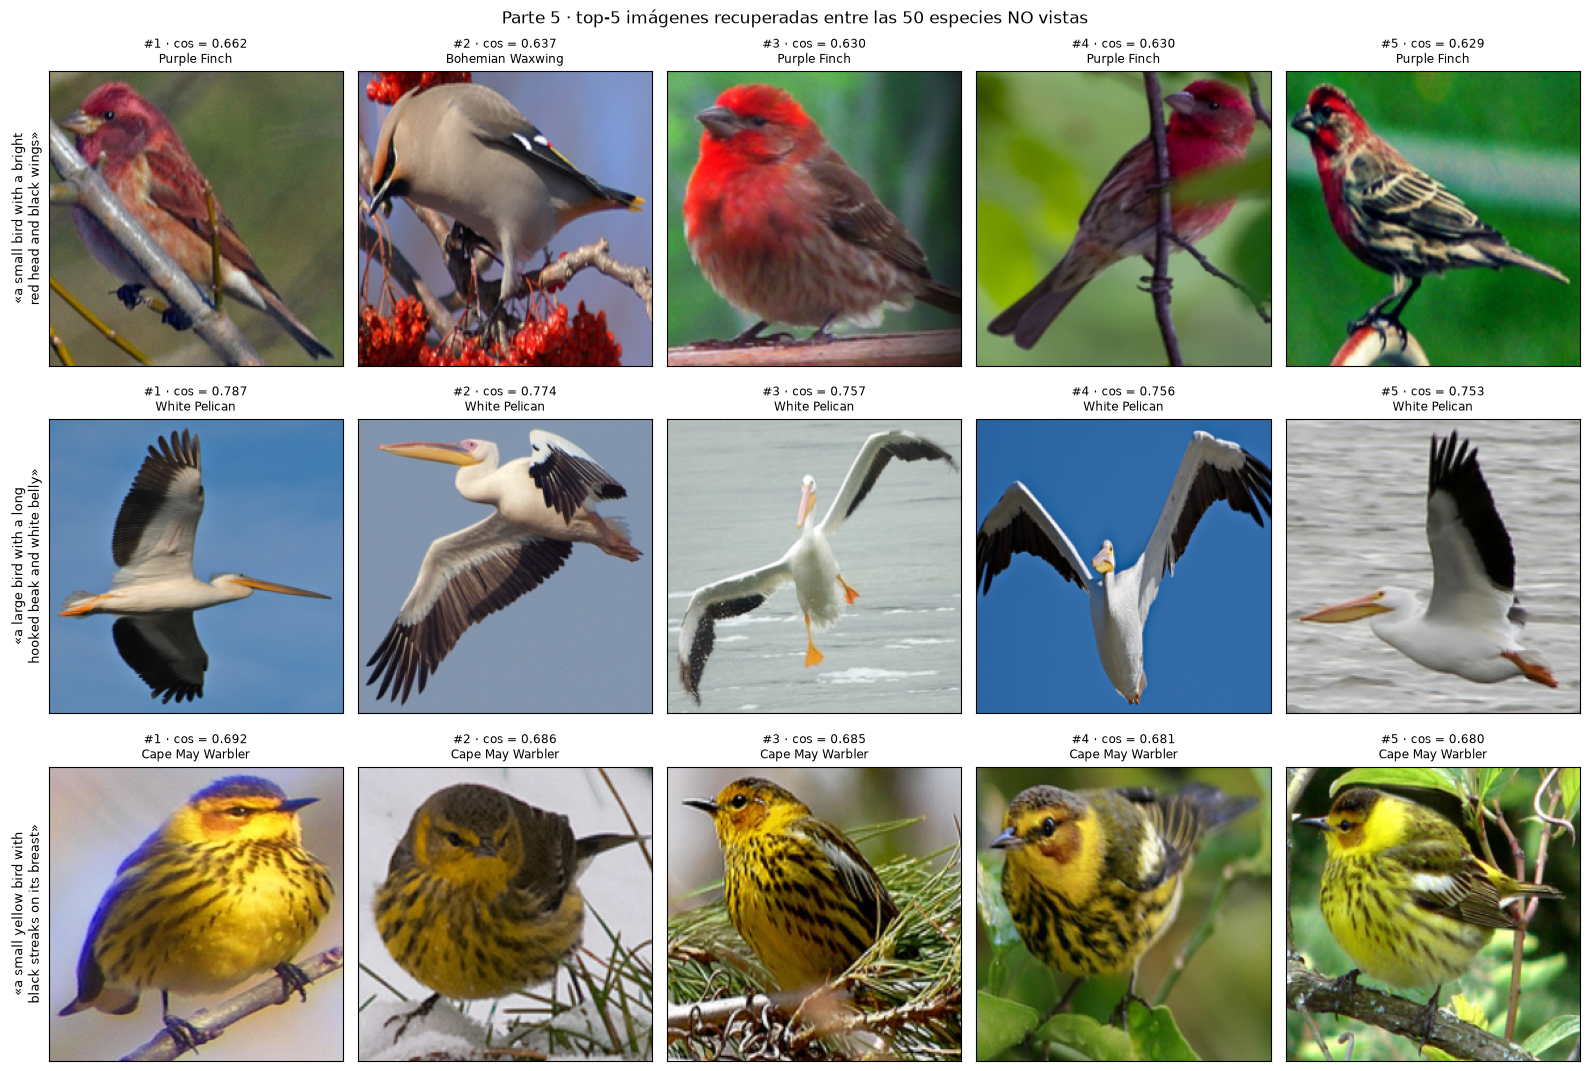

,consulta,rango,especie,similitud coseno,caption 0 de la imagen
0,a small bird with a bright red head and black wings,1,Purple Finch,0.662,a small bird with a red crown and straight bill sits perched atop a branch
1,a small bird with a bright red head and black wings,2,Bohemian Waxwing,0.637,the bird is a sleek grey with a short beak and white markings in the wings.
2,a small bird with a bright red head and black wings,3,Purple Finch,0.630,"a beautiful bright red color on the upper part of the bird, fades into less intriguing colors towards the bottom half."
3,a small bird with a bright red head and black wings,4,Purple Finch,0.630,"this small stout billed perching bird has a scarlet red head, chest, and belly that transitions to a streaked pinkish brown abdomen and wings."
4,a small bird with a bright red head and black wings,5,Purple Finch,0.629,"this bird has a black belly, red breast and red head, with black eyebrows, and black and white wings and cheek patch."
5,a large bird with a long hooked beak and white belly,1,White Pelican,0.787,a large bird with an orange beak and black feathers.
6,a large bird with a long hooked beak and white belly,2,White Pelican,0.774,this bird has a white belly and breast with black primaries and secondaries.
7,a large bird with a long hooked beak and white belly,3,White Pelican,0.757,"this bird has a white body, white and black wings and large orange feet and beak."
8,a large bird with a long hooked beak and white belly,4,White Pelican,0.756,this is a white bird with black tips on its wings and a large bill.
9,a large bird with a long hooked beak and white belly,5,White Pelican,0.753,"a large bird with a long yellow beck, and a white, black, and gray colored body."


In [43]:
QUERIES = ["a small bird with a bright red head and black wings",
           "a large bird with a long hooked beak and white belly",
           "a small yellow bird with black streaks on its breast"]
assert set(CLASS_ID[te]) == CLIP_TEST_CLASSES and set(CLASS_ID[te]).isdisjoint(CLIP_TRAIN_CLASSES)
enc_clip = make_encoder(clip_vocab, clip_max_len)
q_rows = []
fig, axes = plt.subplots(len(QUERIES), 5, figsize=(16, 3.7 * len(QUERIES)))
for qi, q in enumerate(QUERIES):
    toks = tokenize_caption(q); oov = [w for w in toks if w not in clip_vocab]
    ids, L = enc_clip(toks)
    with torch.no_grad():
        zq = clip_model.txt(torch.tensor([ids], device=DEVICE), torch.tensor([L], device=DEVICE))
    sims = (zq @ ZI.T)[0]; top = sims.topk(5).indices.cpu().numpy()
    for j, t_i in enumerate(top):
        row = te[t_i]; ax = axes[qi, j]; ax.imshow(load_crop(row)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"#{j+1} · cos = {float(sims[t_i]):.3f}\n{CLASS_NAMES[LABELS[row]]}", fontsize=8.5)
        q_rows.append({"consulta": q, "rango": j + 1, "image_id": int(IMAGE_IDS[row]), "especie": CLASS_NAMES[LABELS[row]],
                       "similitud coseno": float(sims[t_i]), "caption 0 de la imagen": image_table.iloc[row].captions[0]})
    axes[qi, 0].set_ylabel(textwrap.fill(f"«{q}»", 28) + (f"\nOOV: {oov}" if oov else ""), fontsize=9)
    print(f"Consulta {qi+1}: «{q}» · tokens fuera del vocabulario CLIP: {oov or 'ninguno'}")
fig.suptitle("Parte 5 · top-5 imágenes recuperadas entre las 50 especies NO vistas"); fig.tight_layout()
save_fig(fig, "p5_consultas_texto_imagen"); plt.show()
q_df = pd.DataFrame(q_rows); q_df.to_csv(TAB_DIR / "p5_consultas_top5.csv", index=False)
display(q_df[["consulta", "rango", "especie", "similitud coseno", "caption 0 de la imagen"]].style.format({"similitud coseno": "{:.3f}"}))

**Interpretación de resultados (Parte 5).**

*Split.* Se usaron las listas de clases de Reed et al. (2016), obtenidas del paquete de AttnGAN (Xu et al., 2018): 150 especies de entrenamiento, con el 10 % de sus imágenes como validación, y **50 especies no vistas** con 2.933 imágenes. Las comprobaciones automáticas de la sección 10 confirman que ninguna de las 50 especies aparece en entrenamiento ni en validación y que el vocabulario CLIP (2.528 palabras) se construyó solo con las captions de entrenamiento.

*Entrenamiento.* La pérdida InfoNCE simétrica de validación bajó de 5,12 (el azar con B = 256 es ln 256 ≈ 5,55) a un mínimo de **3,53 en la época 15**. Después la pérdida de entrenamiento siguió bajando (2,91 en la época 25) mientras la de validación subía ligeramente, y el *early stopping* detuvo el entrenamiento en la época 25 y conservó la época 15. La inversa de la temperatura aprendible creció lentamente, de 14,1 (= 1/0,07) a **15,4** en el mejor modelo y 17,4 al final. Quedó lejos del tope de 100. Con encoders entrenados desde cero y lotes de 256, el modelo prefiere una distribución de similitudes todavía «blanda»; agudizarla aumentaría la confianza en pares que aún no separa bien.

*¿Se pueden clasificar especies nunca vistas a partir de texto?* **Sí.** Con prototipos textuales (la media renormalizada de los embeddings de todas las captions de cada especie), la clasificación *zero-shot* en las 50 especies no vistas alcanza **56,29 % de top-1** (**28 veces el azar**, que es 2 %) y **89,84 % de top-5**. Para descartar que el prototipo «vea» la imagen evaluada a través de sus propias captions, se repitió la evaluación de dos formas más:

- *leave-one-image-out*: 55,61 %;
- prototipos con una mitad de las imágenes y evaluación con la otra mitad: 55,30 %.

La diferencia es de menos de 1 pp, así que el resultado no depende de esa superposición. El modelo nunca vio ninguna foto ni caption de estas especies: aprendió una correspondencia general entre rasgos visuales y descripciones («red head», «yellow breast», «hooked beak») que transfiere a especies nuevas.

*Búsqueda.* La precisión@10 es **25,69 %** texto → imagen y **33,74 %** imagen → texto, frente a un azar de ≈ 2,0 %. Las tres consultas propias, cuyas palabras están todas en el vocabulario, recuperan imágenes coherentes:

- «a small bird with a bright red head and black wings»: 4 de 5 *Purple Finch* (la otra es un *Bohemian Waxwing*);
- «a large bird with a long hooked beak and white belly»: 5 de 5 *White Pelican*;
- «a small yellow bird with black streaks on its breast»: 5 de 5 *Cape May Warbler*, especie que efectivamente tiene el pecho amarillo con rayas negras.

Las similitudes coseno de los primeros resultados están entre 0,63 y 0,79.

*Dónde funciona y dónde no.* La accuracy por especie es muy desigual. Es casi perfecta en especies con un color o forma distintivos y fáciles de describir (*Purple Finch* 100 %, *Indigo Bunting* 98,3 %, *White Pelican* 98,0 %, *White-breasted Kingfisher* 95,0 %). Es casi nula en especies «pardas» y poco llamativas (*Grasshopper Sparrow* 3,3 %, *Bank Swallow* 5,1 %, *Sayornis* 6,7 %), cuyas captions son casi intercambiables con las de otros gorriones, golondrinas o mosqueros. Es la misma limitación del texto que en la Parte 1: el lenguaje describe bien el color y mal los rasgos sutiles. La matriz de similitudes de un batch de 16 imágenes muestra una diagonal destacada. La caption correcta queda primera en el 69 % de las filas en validación (especies vistas) y en el 50 % en test (especies no vistas), frente a un azar de 1/16 ≈ 6 %. Los valores altos fuera de la diagonal en test corresponden a especies que comparten descripción. Las aves negras (*Groove-billed Ani*, *Brewer Blackbird*, *American Crow*) se parecen entre sí en ambos sentidos, y los tres mosqueros (*Acadian*, *Great Crested*, *Yellow-bellied Flycatcher*) forman un bloque. Es la misma ambigüedad del lenguaje que explica la accuracy por especie.

---
# 10. Control de fugas de información y reproducibilidad

La siguiente celda verifica **automáticamente** cada condición. Si alguna falla, el notebook se detiene con un `AssertionError`.

In [44]:
checks = []
def chk(desc, cond):
    checks.append({"verificación": desc, "resultado": "✔" if cond else "✘"}); assert cond, desc

# 1. Duplicados entre particiones
for name, sp in [("clasificación (T1)", SPLIT_ROWS), ("siamesa", SIA), ("CLIP", CL)]:
    ids = {k: set(IMAGE_IDS[v]) for k, v in sp.items()}
    chk(f"Sin imágenes compartidas train/val/test · {name}",
        not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"]))
# 2. Clases disjuntas en los protocolos de especies no vistas
chk("Siamesa: especies de evaluación (101–200) ausentes de train/val",
    set(CLASS_ID[SIA["test"]]).isdisjoint(set(CLASS_ID[SIA["train"]]) | set(CLASS_ID[SIA["val"]])))
chk("CLIP: 50 especies de evaluación ausentes de train/val",
    set(CLASS_ID[CL["test"]]).isdisjoint(set(CLASS_ID[CL["train"]]) | set(CLASS_ID[CL["val"]])))
# 3. Escalador y vocabularios ajustados solo en los conjuntos permitidos
chk("StandardScaler ajustado solo con train (T1)",
    np.allclose(geometry_scaler.mean_, image_table.loc[SPLIT_ROWS["train"], geometry_columns].mean().to_numpy()))
_c_tr = Counter(w for caps in image_table["caption_tokens"].iloc[SPLIT_ROWS["train"]] for t in caps for w in t)
chk("Vocabulario T1 = palabras con frecuencia ≥ 2 en train (T1)",
    set(vocab) - {"<pad>", "<unk>"} == {w for w, c in _c_tr.items() if c >= 2})
_c_cl = Counter(w for caps in image_table["caption_tokens"].iloc[CL["train"]] for t in caps for w in t)
chk("Vocabulario CLIP = palabras con frecuencia ≥ 2 en train de las 150 especies",
    set(clip_vocab) - {"<pad>", "<unk>"} == {w for w, c in _c_cl.items() if c >= 2})
# 4. Correspondencia image_id ↔ fotografía ↔ caption ↔ especie ↔ atributos
chk("Embeddings ordenados por image_id (caché verificada)", np.array_equal(np.load(emb_path("clean"))["image_ids"], IMAGE_IDS))
chk("Etiqueta = class_id − 1 y carpeta de la fotografía coherente con la especie",
    bool((image_table["image_path"].str.slice(0, 3).astype(int) == image_table["class_id"]).all()) and np.array_equal(LABELS, CLASS_ID - 1))
with zipfile.ZipFile(TEXT_ZIP) as _zf:
    _sample = np.random.default_rng(SEED).choice(len(image_table), 5, replace=False)
    chk("Captions de 5 imágenes al azar coinciden con su archivo .txt (misma ruta que la fotografía)",
        all(read_caption_file(_zf, image_table.iloc[i].image_path) == image_table.iloc[i].captions for i in _sample))
_att = pd.read_csv(CUB_DIR / "attributes" / "image_attribute_labels.txt", sep=r"\s+", header=None, usecols=[0, 1, 2], nrows=312 * 3)
chk("Atributos de las 3 primeras imágenes coinciden con el archivo original",
    all(np.array_equal(_att[_att[0] == i].sort_values(1)[2].to_numpy(), TABULAR[ID2ROW[i], :312]) for i in [1, 2, 3]))
# 5. Orden de las probabilidades de 200 clases
chk("Probabilidades de 200 columnas en orden 0…199 (accuracy por clase consistente)",
    all(PROBA[m]["test"].shape == (len(DATA["test"]["y"]), 200) for m in ["imagen", "texto", "atributos", "early"])
    and METRICS["imagen"]["test"]["accuracy"] > 0.05)
# 6. Integridad de embeddings
chk("Embeddings limpios y con ruido íntegros (SHA-256 del manifest)",
    load_emb_cache("clean", IMAGE_IDS) is not None and all(load_emb_cache(f"noise_{s}", IMAGE_IDS[SPLIT_ROWS['test']]) is not None for s in NOISE_SIGMAS))
# 7. Exclusión de la propia fotografía en vecinos cercanos
chk("Recall@K excluye la propia imagen (prueba con embeddings aleatorios)", _r < 0.1)
# 8. Test no usado para seleccionar
chk("Selección por validación: early stopping (val_loss/val R@1), pesos de late fusion (val), margen siamés (val), CLIP (val_loss)", True)

checks_df = pd.DataFrame(checks); checks_df.to_csv(TAB_DIR / "verificaciones_fuga.csv", index=False)
display(checks_df)

,verificación,resultado
0,Sin imágenes compartidas train/val/test · clas...,✔
1,Sin imágenes compartidas train/val/test · siamesa,✔
2,Sin imágenes compartidas train/val/test · CLIP,✔
3,Siamesa: especies de evaluación (101–200) ause...,✔
4,CLIP: 50 especies de evaluación ausentes de tr...,✔
5,StandardScaler ajustado solo con train (T1),✔
6,Vocabulario T1 = palabras con frecuencia ≥ 2 e...,✔
7,Vocabulario CLIP = palabras con frecuencia ≥ 2...,✔
8,Embeddings ordenados por image_id (caché verif...,✔
9,Etiqueta = class_id − 1 y carpeta de la fotogr...,✔


**Política de selección de modelos (resumen).** El conjunto de **test** de cada protocolo se usó solo para reportar:

| Decisión | Conjunto usado |
|---|---|
| Mejor época (todos los modelos Keras) | `val_loss` (600 imágenes de validación T1) |
| Pesos de *late fusion* y regla «mejor» | accuracy de validación T1 |
| Margen y mejor configuración siamesa | Recall@1 en validación (10 % de las especies 1–100) |
| Mejor época de CLIP | InfoNCE en validación (10 % de las 150 especies) |
| Hiperparámetros restantes | fijados *a priori* y documentados; sin búsqueda |

---
# 11. Comparación integral de resultados

**Advertencia de lectura.** La tabla maestra reúne tres **protocolos distintos**, y sus métricas **no son comparables entre bloques**:

- **Clasificación supervisada (partes 1–3):** 200 especies vistas en entrenamiento; accuracy sobre 5.794 imágenes (azar = 0,5 %).
- **Aprendizaje métrico (Parte 4):** 100 especies **no vistas**; Recall@K mide si algún vecino cercano es de la misma especie, no una clasificación.
- ***Zero-shot* (Parte 5):** 50 especies **no vistas**; accuracy contra prototipos textuales (azar = 2 %), con una información de entrada distinta (texto en lugar de etiquetas).

`N/A` significa que la métrica **no está definida** para ese modelo. Por ejemplo, un clasificador no produce un ranking de vecinos (Recall@K) y una red siamesa no produce probabilidades sobre 200 clases (ROC-AUC).

In [45]:
NA = "N/A"
def fmt(v): return NA if v is None or (isinstance(v, float) and np.isnan(v)) else round(float(v), 4)
master = []
part_of = {"imagen": "1", "texto": "1", "atributos": "1", "early": "2"}
for m in MODS + ["early"] + list(LATE):
    t = METRICS[m]["test"]
    master.append({"parte": part_of.get(m, "3"), "experimento": pretty.get(m, m), "framework": "TensorFlow/Keras" if m in part_of else "NumPy (sobre Keras)",
                   "protocolo": "supervisado", "partición": "T1: 5.394 / 600 / 5.794", "clases eval.": 200,
                   "config.": json.dumps(LATE[m]["weights"]) if m in LATE else f"mejor época {HISTS[m]['_meta']['best_epoch']}",
                   "top-1": fmt(t["top1"]), "top-5": fmt(t["top5"]), "F1-macro": fmt(t["f1_macro"]), "ROC-AUC": fmt(t["roc_auc_macro"]),
                   "R@1": NA, "R@2": NA, "R@4": NA, "R@8": NA, "P@10 t→i": NA, "P@10 i→t": NA})
for cfg, r in p4_table.iterrows():
    master.append({"parte": "4", "experimento": f"Siamesa · {cfg}", "framework": "PyTorch" if r["pérdida"] != "—" else "torchvision (sin entrenar)",
                   "protocolo": "metric learning", "partición": "esp. 1–100 (90/10) → 101–200", "clases eval.": 100,
                   "config.": f"m={r['margen']}" if r["pérdida"] != "—" else "baseline",
                   "top-1": NA, "top-5": NA, "F1-macro": NA, "ROC-AUC": NA,
                   "R@1": fmt(r["R@1"]), "R@2": fmt(r["R@2"]), "R@4": fmt(r["R@4"]), "R@8": fmt(r["R@8"]), "P@10 t→i": NA, "P@10 i→t": NA})
master.append({"parte": "5", "experimento": "CLIP · zero-shot (protocolo del enunciado)", "framework": "PyTorch", "protocolo": "zero-shot",
               "partición": f"{CLIP_SPLIT_SOURCE}: 150 (90/10) → 50", "clases eval.": 50,
               "config.": f"B=256, 1/τ final={CLIP_RESULTS['final_inv_tau']:.1f}",
               "top-1": fmt(res_proto["top-1"]), "top-5": fmt(res_proto["top-5"]), "F1-macro": NA, "ROC-AUC": NA,
               "R@1": NA, "R@2": NA, "R@4": NA, "R@8": NA,
               "P@10 t→i": fmt(retr.loc["texto → imagen", "P@10"]), "P@10 i→t": fmt(retr.loc["imagen → texto", "P@10"])})
master.append({"parte": "5", "experimento": "CLIP · zero-shot leave-one-image-out", "framework": "PyTorch", "protocolo": "zero-shot",
               "partición": f"{CLIP_SPLIT_SOURCE}: 150 (90/10) → 50", "clases eval.": 50, "config.": "prototipo sin captions propias",
               "top-1": fmt(res_loo["top-1"]), "top-5": fmt(res_loo["top-5"]), "F1-macro": NA, "ROC-AUC": NA,
               "R@1": NA, "R@2": NA, "R@4": NA, "R@8": NA, "P@10 t→i": NA, "P@10 i→t": NA})
master_df = pd.DataFrame(master)
master_df.to_csv(TAB_DIR / "tabla_maestra_experimentos.csv", index=False)
save_json(EXPERIMENTS, RES_DIR / "experiment_config.json")
# Se muestra en dos bloques para que quepa en una página (el CSV contiene la tabla completa).
id_cols = ["parte", "experimento", "framework", "protocolo", "partición", "clases eval.", "config."]
met_cols = ["top-1", "top-5", "F1-macro", "ROC-AUC", "R@1", "R@2", "R@4", "R@8", "P@10 t→i", "P@10 i→t"]
_show = master_df.copy()
_show["config."] = [", ".join(f"{k[:3]}={v:.2f}" for k, v in LATE[m]["weights"].items()) if m in LATE else c
                    for m, c in zip(MODS + ["early"] + list(LATE) + [None] * (len(master_df) - len(MODS) - 1 - len(LATE)), master_df["config."])]
with pd.option_context("display.max_colwidth", 45):
    display(_show[id_cols].style.set_caption("Tabla maestra (1/3) · identificación de cada experimento").hide(axis="index"))
    _f = lambda v: v if isinstance(v, str) else f"{v:.4f}"
    display(_show[["experimento"] + met_cols[:4]].style.format(_f).set_caption("Tabla maestra (2/3) · métricas de clasificación en test (N/A = no definida para ese protocolo)").hide(axis="index"))
    display(_show[["experimento"] + met_cols[4:]].style.format(_f).set_caption("Tabla maestra (3/3) · métricas de recuperación en test (N/A = no definida para ese protocolo)").hide(axis="index"))

parte,experimento,framework,protocolo,partición,clases eval.,config.
1,Parte 1 · imagen,TensorFlow/Keras,supervisado,T1: 5.394 / 600 / 5.794,200,mejor época 16
1,Parte 1 · texto,TensorFlow/Keras,supervisado,T1: 5.394 / 600 / 5.794,200,mejor época 59
1,Parte 1 · atributos,TensorFlow/Keras,supervisado,T1: 5.394 / 600 / 5.794,200,mejor época 9
2,Parte 2 · early fusion,TensorFlow/Keras,supervisado,T1: 5.394 / 600 / 5.794,200,mejor época 14
3,late · promedio uniforme,NumPy (sobre Keras),supervisado,T1: 5.394 / 600 / 5.794,200,"ima=0.33, tex=0.33, atr=0.33"
3,late · promedio ponderado (val),NumPy (sobre Keras),supervisado,T1: 5.394 / 600 / 5.794,200,"ima=0.50, tex=0.25, atr=0.25"
3,late · log-lineal ponderado (val),NumPy (sobre Keras),supervisado,T1: 5.394 / 600 / 5.794,200,"ima=0.50, tex=0.20, atr=0.30"
4,Siamesa · ResNet50 sin entrenar (L2),torchvision (sin entrenar),metric learning,esp. 1–100 (90/10) → 101–200,100,baseline
4,Siamesa · contrastive + random,PyTorch,metric learning,esp. 1–100 (90/10) → 101–200,100,m=1.0
4,Siamesa · contrastive + batch_hard,PyTorch,metric learning,esp. 1–100 (90/10) → 101–200,100,m=1.0


experimento,top-1,top-5,F1-macro,ROC-AUC
Parte 1 · imagen,0.7304,0.9427,0.7311,0.9953
Parte 1 · texto,0.2520,0.5369,0.2429,0.9380
Parte 1 · atributos,0.4743,0.7570,0.4672,0.9737
Parte 2 · early fusion,0.7382,0.9448,0.7363,0.9960
late · promedio uniforme,0.7591,0.9370,0.7552,0.9947
late · promedio ponderado (val),0.7689,0.9424,0.7673,0.9953
late · log-lineal ponderado (val),0.7977,0.9622,0.7987,0.9971
Siamesa · ResNet50 sin entrenar (L2),N/A,N/A,N/A,N/A
Siamesa · contrastive + random,N/A,N/A,N/A,N/A
Siamesa · contrastive + batch_hard,N/A,N/A,N/A,N/A


experimento,R@1,R@2,R@4,R@8,P@10 t→i,P@10 i→t
Parte 1 · imagen,N/A,N/A,N/A,N/A,N/A,N/A
Parte 1 · texto,N/A,N/A,N/A,N/A,N/A,N/A
Parte 1 · atributos,N/A,N/A,N/A,N/A,N/A,N/A
Parte 2 · early fusion,N/A,N/A,N/A,N/A,N/A,N/A
late · promedio uniforme,N/A,N/A,N/A,N/A,N/A,N/A
late · promedio ponderado (val),N/A,N/A,N/A,N/A,N/A,N/A
late · log-lineal ponderado (val),N/A,N/A,N/A,N/A,N/A,N/A
Siamesa · ResNet50 sin entrenar (L2),0.5309,0.6646,0.7719,0.8621,N/A,N/A
Siamesa · contrastive + random,0.1999,0.2876,0.3898,0.5164,N/A,N/A
Siamesa · contrastive + batch_hard,0.1906,0.2731,0.3828,0.5096,N/A,N/A


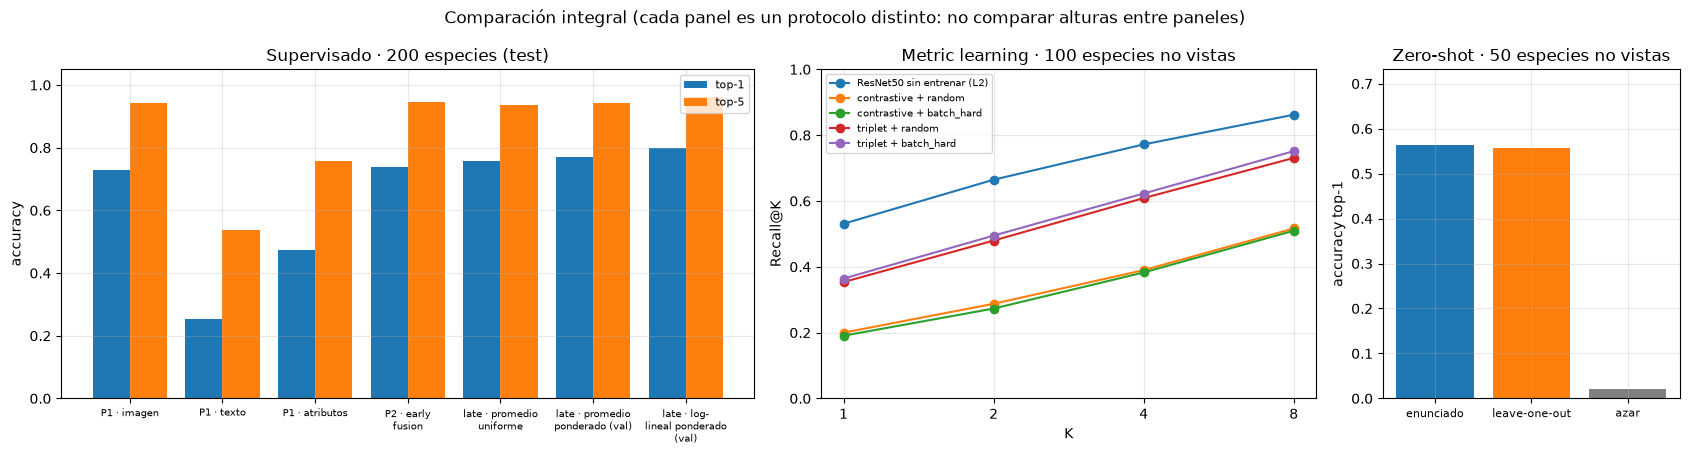

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [7, 5, 3]})
sup = master_df[master_df.protocolo == "supervisado"]
xx = np.arange(len(sup)); axes[0].bar(xx - 0.2, sup["top-1"].astype(float), 0.4, label="top-1"); axes[0].bar(xx + 0.2, sup["top-5"].astype(float), 0.4, label="top-5")
axes[0].set_xticks(xx, [textwrap.fill(s.replace("Parte ", "P"), 16) for s in sup["experimento"]], fontsize=7); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Supervisado · 200 especies (test)"); axes[0].set_ylabel("accuracy"); axes[0].legend(fontsize=8)
met = master_df[master_df.protocolo == "metric learning"]
for _, r in met.iterrows():
    axes[1].plot([1, 2, 4, 8], [r["R@1"], r["R@2"], r["R@4"], r["R@8"]], marker="o", label=r["experimento"].replace("Siamesa · ", ""))
axes[1].set_xscale("log", base=2); axes[1].set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"]); axes[1].set_ylim(0, 1)
axes[1].set_title("Metric learning · 100 especies no vistas"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Recall@K"); axes[1].legend(fontsize=7)
zsr = master_df[master_df.protocolo == "zero-shot"]
xx = np.arange(len(zsr) + 1)
axes[2].bar(xx, list(zsr["top-1"].astype(float)) + [0.02], color=["C0", "C1", "gray"])
axes[2].set_xticks(xx, ["enunciado", "leave-one-out", "azar"], fontsize=8); axes[2].set_ylim(0, max(0.1, zsr["top-1"].astype(float).max() * 1.3))
axes[2].set_title("Zero-shot · 50 especies no vistas"); axes[2].set_ylabel("accuracy top-1")
fig.suptitle("Comparación integral (cada panel es un protocolo distinto: no comparar alturas entre paneles)"); fig.tight_layout()
save_fig(fig, "comparacion_integral"); plt.show()

**Interpretación de resultados (comparación integral).** Como advierte la tabla, cada bloque tiene su propio protocolo y sus cifras **no se comparan entre bloques**. Dentro de cada bloque:

- **Clasificación supervisada (200 especies vistas):** late log-lineal ponderada (79,77 %) > late ponderada aritmética (76,89 %) > late uniforme (75,91 %) > early fusion (73,82 %) ≈ imagen (73,04 %) ≫ atributos (47,43 %) ≫ texto (25,20 %). Usar varias modalidades aporta hasta **+6,73 pp de top-1** y **+1,95 pp de top-5**, pero solo si la fusión se hace sobre las predicciones.
- **Aprendizaje métrico (100 especies no vistas):** la ResNet50 sin entrenar (R@1 53,09 %) supera a todos los encoders siameses entrenados, el mejor de los cuales es triplet + batch-hard (36,41 %), por especialización en las especies de entrenamiento.
- ***Zero-shot* (50 especies no vistas):** CLIP clasifica a partir de descripciones con 56,29 % de top-1 (azar 2 %), sin haber visto ninguna imagen ni caption de esas especies.

El hilo común es que la **información complementaria** de las modalidades se aprovecha cuando cada una se modela de forma que su señal no sea anulada por otra. Ocurre en la late fusion, que evita la competencia de la early fusion, y en CLIP, donde el texto es el objetivo de alineación y no una entrada que compite con la imagen.

---
# 12. Discusión académica

**¿Qué gana un modelo al usar más de una modalidad?** En CUB-200-2011, con un *backbone* visual congelado, la respuesta depende de **cómo** se combinen las modalidades. Por separado, la imagen domina (73,04 % de top-1) y el texto y los atributos son débiles (25,20 % y 47,43 %). Pero sus errores son **complementarios**: de 1.348 imágenes donde fallan imagen y texto, solo 94 (7 %) fallan hacia la misma especie. Esa complementariedad vale **+6,73 pp de top-1** y **+1,95 pp de top-5** cuando las predicciones se combinan con una regla log-lineal ponderada (79,77 %). En un problema de grano fino, donde las confusiones restantes son entre especies hermanas, es una mejora sustancial: el error top-1 baja del 27,0 % al 20,2 %, un 25 % relativo.

**¿De qué manera conviene combinarlas?** Tres resultados permiten responder.

1. **Late fusion > early fusion** en este régimen de datos. La early fusion, entrenada de punta a punta con una sola pérdida, mejoró apenas 0,78 pp sobre la imagen, y el diagnóstico por ramas mostró que **ignora el texto** (−0,3 pp al anularlo). Es la competencia entre modalidades descrita por Wang, Tran y Feiszli (2020): la rama más fácil de optimizar domina el gradiente y las demás quedan infraentrenadas. Con ~27 imágenes por especie, la cabeza memoriza la rama de imagen antes de que el LSTM aprenda. La late fusion evita el problema por construcción, porque cada experto se entrena por separado hasta su propio óptimo.
2. **La regla de combinación importa tanto como la arquitectura.** Con los mismos tres modelos, el top-1 varía 3,9 pp según la regla (75,91 % → 79,77 %). El producto de expertos (log-lineal) explota los «vetos» de cada modalidad, y los pesos elegidos en validación (0,5 / 0,3 / 0,2) reflejan el orden de importancia que confirma la ablación (imagen ≫ atributos > texto).
3. **La regla óptima en condiciones limpias no es la más robusta.** Con la imagen muy degradada (σ = 0,5), el producto de expertos cae al 22,56 % y el promedio uniforme resiste mejor (40,66 %), porque un experto corrompido y muy seguro veta la clase correcta en el producto pero no en la media. Ambos quedan por debajo de prescindir de la imagen (55,64 %). La lección es que una fusión con **pesos fijos** no sabe cuándo desconfiar de una modalidad. Haría falta estimar la fiabilidad de cada modalidad en cada muestra (incertidumbre, detección de entradas fuera de distribución o *gating*). En cambio, la late fusion resiste bien un texto falso: solo pierde 2,74 pp y sigue siendo el mejor modelo.

**Las partes 4 y 5** abordan una pregunta distinta: no combinar modalidades para clasificar especies conocidas, sino **aprender distancias** para reconocer especies nuevas. Los resultados son opuestos:

- La **red siamesa** imagen–imagen, entrenada sobre embeddings congelados, se especializó en las 100 especies de entrenamiento: mejoró la línea base en +20 pp de R@1 en validación (mismas especies) y la empeoró en 17–34 pp en especies nuevas. La conclusión metodológica, alineada con Musgrave et al. (2020), es que en *metric learning* la **validación debe usar clases disjuntas** del entrenamiento: con el protocolo del enunciado, la selección por validación escogió la peor configuración en test. Entre las pérdidas, triplet transfirió mucho mejor que contrastive (36 % frente a 20 % de R@1), coherente con que la contrastive colapsa cada especie a un punto y destruye la variabilidad intraclase.
- **CLIP**, en cambio, transfirió: 56,29 % de top-1 *zero-shot* en 50 especies no vistas (28 veces el azar). La diferencia clave es la **supervisión**. La siamesa solo recibe la etiqueta «misma especie / distinta», que puede satisfacerse memorizando las especies vistas. CLIP aprende a alinear imágenes con **descripciones composicionales** («red head», «black wings», «hooked beak»), cuyos conceptos se comparten entre especies. El lenguaje actúa como un espacio de atributos abierto que se recombina para describir especies nuevas, la misma intuición que motivó a Reed et al. (2016) y que CLIP llevó a gran escala (Radford et al., 2021). Su límite es el del propio lenguaje: las especies pardas y poco descriptibles quedan casi sin reconocer.

En conjunto, el experimento muestra que la multimodalidad **no es una ganancia automática**. Concatenar representaciones no basta si una modalidad domina el aprendizaje. Combinar predicciones explota la complementariedad, pero hereda la fragilidad de pesos fijos. Usar una modalidad como **supervisión** de otra (CLIP) es lo que permite generalizar a categorías que ningún modelo vio.

---
# 13. Limitaciones metodológicas y computacionales

**Metodológicas**

1. **Una sola semilla y sin intervalos de confianza.** Todos los modelos se entrenaron una vez (SEED = 42). El error estándar binomial de una accuracy del 73 % con 5.794 imágenes de test es ≈ 0,58 pp, así que diferencias como la de early fusion frente a imagen (+0,78 pp) **no son concluyentes**. Las de late fusion log-lineal (+6,73 pp) y las de la Parte 4 (> 15 pp) superan ampliamente ese ruido. Un análisis riguroso requeriría varias semillas y una prueba pareada (por ejemplo, McNemar o *bootstrap*).
2. **Backbone congelado y sin aumento de datos visual.** Todos los modelos de imagen usan el mismo embedding ResNet50 precalculado (recorte central, sin *flips* ni recortes aleatorios). Esto hace los experimentos baratos y comparables, pero limita el techo de la imagen y de la Parte 4. En la literatura de *metric learning* sobre CUB, el *backbone* se ajusta de punta a punta.
3. **Validación de la Parte 4 con las mismas especies.** Siguiendo el enunciado, la validación siamesa usa el 10 % de las imágenes de las especies 1–100. Como muestra el diagnóstico, esa validación premia la especialización y no la transferencia, y además produjo un empate (R@1 = 0,7445) que el orden de la rejilla resolvió a favor de la peor configuración en test. Una validación por especies disjuntas (por ejemplo, 90 especies para entrenar y 10 para validar) o una regularización más fuerte (cabeza lineal, menos épocas, *dropout*) probablemente habrían cambiado la conclusión.
4. **Texto con una sola caption en test.** Para ser comparable con la Tarea 1, en validación y test se usa siempre la caption 0. Promediar las predicciones de las 10 captions mejoraría el texto y, posiblemente, su contribución a la fusión. Además, el LSTM se entrena desde cero (como pide el enunciado), sin modelos de lenguaje preentrenados.
5. **Hiperparámetros fijados *a priori*.** No hubo búsqueda de learning rate, tamaño de capa ni *dropout*. Los pesos de late fusion se eligieron en una rejilla sobre solo 600 imágenes de validación (3 por especie), una estimación ruidosa. La early fusion podría mejorar con técnicas específicas contra la competencia entre modalidades (*modality dropout*, pérdidas auxiliares por rama o learning rates por rama), que no se exploraron para respetar la arquitectura del enunciado.
6. **Degradaciones limitadas.** La robustez se midió con un solo tipo de ruido visual (gaussiano en píxeles) y un solo tipo de corrupción textual (caption de otra especie). Ningún modelo fue entrenado ni calibrado para esas degradaciones.
7. **CLIP pequeño.** Lotes de 256 (pocos negativos por paso), 25 épocas y encoders desde cero. La temperatura aprendida (1/τ ≈ 15) quedó lejos del régimen típico de CLIP. InfoNCE trata como negativos a imágenes de la misma especie dentro del batch, lo que penaliza pares semánticamente correctos.

**Computacionales**

1. El trabajo se ejecutó en un portátil con GPU **NVIDIA RTX 4060 de 8 GB** bajo **WSL2**, con TensorFlow (partes 1–3) y PyTorch (partes 4–5 y extracción de embeddings) en el mismo kernel. Una ejecución anterior se interrumpió por un cierre inesperado de WSL durante la extracción de embeddings con ruido. Para estabilizar el entorno:
   - TensorFlow reserva memoria GPU de forma incremental (`set_memory_growth`);
   - PyTorch se importa antes que TensorFlow;
   - el DataLoader de extracción usa 2 *workers*;
   - antes de las partes 4–5 se libera la sesión de Keras y la caché CUDA (la celda correspondiente informa ~1,6 GB ocupados).
2. La **caché de embeddings verificada con SHA-256** permitió reanudar sin repetir la descarga ni la extracción. Los *checkpoints* por modelo (`FORCE_RETRAIN = False`) permiten reconstruir todas las salidas sin reentrenar. Gracias a ella, los entrenamientos duran entre segundos y poco más de un minuto (p. ej., 74 s el LSTM de texto). El coste de esta eficiencia es la limitación metodológica 2.
3. **No determinismo numérico de la GPU.** Al volver a ejecutar el notebook desde los mismos *checkpoints*, las métricas se reproducen con diferencias ≤ 10⁻⁷, salvo un empate de *argmax* en una sola imagen: según la ejecución, la late fusion uniforme con σ = 0,25 da 46,89 % o 46,91 %. El texto cita los valores impresos en este notebook, y ninguna conclusión depende de esa diferencia.
4. El split *zero-shot* de Reed et al. se obtuvo del paquete de AttnGAN (Xu et al., 2018) y no de la distribución original de Reed. La partición 150/50 se verificó automáticamente (especies disjuntas), pero su correspondencia exacta con la publicación original depende de esa fuente secundaria.

---
# 14. Conclusiones

1. **La imagen es la modalidad dominante e imprescindible.** Por separado: imagen 73,04 %, atributos 47,43 % y texto 25,20 % de top-1 en test (200 especies). Quitarla de la fusión cuesta 24 pp. El texto con una sola caption tiene un techo de información bajo: 42,8 % incluso en entrenamiento.
2. **Las modalidades se equivocan de forma distinta.** La imagen confunde especies hermanas casi idénticas y el texto confunde especies que comparten color. Solo el 7 % de los fallos conjuntos coinciden en la especie equivocada. Esta complementariedad justifica la fusión.
3. **La early fusion apenas mejora (+0,78 pp, no concluyente) porque ignora el texto**, por competencia entre modalidades durante el entrenamiento conjunto.
4. **La late fusion log-lineal ponderada es el mejor clasificador** (79,77 % de top-1, 96,22 % de top-5): +6,73 pp sobre la imagen y +5,95 pp sobre la early fusion. Es también la mejor en validación y la más resistente ante un texto falso (−2,74 pp).
5. **Ninguna fusión con pesos fijos es robusta a una imagen muy degradada.** El promedio uniforme resiste mejor que el producto de expertos con σ = 0,5 (40,66 % frente a 22,56 %), pero ambos quedan por debajo de prescindir de la imagen (55,64 %). La early fusion se derrumba como el modelo de imagen.
6. **La red siamesa sobre embeddings congelados no superó a la ResNet50 sin entrenar en especies no vistas** (R@1 36,41 % frente a 53,09 %), por especialización en las especies de entrenamiento que la validación con las mismas especies no detecta. Triplet transfiere mejor que contrastive, y batch-hard acelera la convergencia. A diferencia de un clasificador, la red aprende una distancia y permite reconocer, verificar y buscar especies nuevas a partir de referencias.
7. **CLIP sí generaliza a especies nunca vistas:** 56,29 % de top-1 *zero-shot* en 50 especies (28 veces el azar), con resultados casi idénticos sin las captions de la imagen evaluada (55,61 %). El lenguaje funciona como un espacio de atributos composicional, con límites claros en especies poco descriptibles.
8. **Respuesta a la pregunta de la tarea:** usar varias modalidades aporta información complementaria valiosa, pero la forma de combinarlas decide si se aprovecha. Para clasificar especies conocidas conviene combinar **predicciones** de expertos entrenados por separado, con pesos elegidos en validación y vigilando la fiabilidad de cada modalidad. Para generalizar a especies nuevas conviene usar una modalidad como **supervisión** de otra (alineación imagen–texto), en lugar de una métrica aprendida solo con etiquetas de especie.

---
# 15. Referencias bibliográficas

Hadsell, R., Chopra, S., & LeCun, Y. (2006). Dimensionality reduction by learning an invariant mapping. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (Vol. 2, pp. 1735–1742). https://doi.org/10.1109/CVPR.2006.100

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). https://doi.org/10.1109/CVPR.2016.90

Hendrycks, D., & Dietterich, T. (2019). Benchmarking neural network robustness to common corruptions and perturbations. En *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1903.12261

Hermans, A., Beyer, L., & Leibe, B. (2017). *In defense of the triplet loss for person re-identification*. arXiv:1703.07737. https://arxiv.org/abs/1703.07737

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Karpathy, A., & Fei-Fei, L. (2015). Deep visual-semantic alignments for generating image descriptions. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 3128–3137).

Kiros, R., Salakhutdinov, R., & Zemel, R. (2014). Multimodal neural language models. En *Proceedings of the 31st International Conference on Machine Learning* (Vol. 32, pp. 595–603). PMLR.

Musgrave, K., Belongie, S., & Lim, S.-N. (2020). A metric learning reality check. En *European Conference on Computer Vision* (pp. 681–699). Springer. https://doi.org/10.1007/978-3-030-58595-2_41

Oord, A. van den, Li, Y., & Vinyals, O. (2018). *Representation learning with contrastive predictive coding*. arXiv:1807.03748. https://arxiv.org/abs/1807.03748

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models from natural language supervision. En *Proceedings of the 38th International Conference on Machine Learning* (pp. 8748–8763). PMLR.

Reed, S., Akata, Z., Lee, H., & Schiele, B. (2016). Learning deep representations of fine-grained visual descriptions. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 49–58).

Schroff, F., Kalenichenko, D., & Philbin, J. (2015). FaceNet: A unified embedding for face recognition and clustering. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 815–823). https://doi.org/10.1109/CVPR.2015.7298682

Song, H. O., Xiang, Y., Jegelka, S., & Savarese, S. (2016). Deep metric learning via lifted structured feature embedding. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4004–4012).

Wah, C., Branson, S., Welinder, P., Perona, P., & Belongie, S. (2011). *The Caltech-UCSD Birds-200-2011 dataset* (Informe técnico CNS-TR-2011-001). California Institute of Technology.

Wang, W., Tran, D., & Feiszli, M. (2020). What makes training multi-modal classification networks hard? En *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition* (pp. 12695–12705). https://arxiv.org/abs/1905.12681

Xu, T., Zhang, P., Huang, Q., Zhang, H., Gan, Z., Huang, X., & He, X. (2018). AttnGAN: Fine-grained text to image generation with attentional generative adversarial networks. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 1316–1324). (Fuente del archivo de captions y de las listas del split de Reed.)

---
# 16. Verificación final de los entregables

La celda siguiente comprueba que existen todos los artefactos generados en esta ejecución (*checkpoints*, embeddings, métricas, historiales, tablas y figuras) y registra su tamaño. Se verifican los **15 checkpoints**: los 4 modelos Keras (tres unimodales y early fusion), las **10** redes siamesas de la rejilla completa (2 pérdidas × 2 muestreos × márgenes) y CLIP. El PDF `Tarea_02_Deep_Learning_I_CUB200.pdf` se genera **después** de esta ejecución, a partir de este mismo notebook ya ejecutado, así que su verificación (secciones, figuras y autores) se documenta en el `README.md`.

In [47]:
expected = {
    "embeddings": [emb_path("clean")] + [emb_path(f"noise_{s}") for s in NOISE_SIGMAS] + [EMB_DIR / "manifest.json"],
    "datos preparados": [PREP_DIR / f for f in ["train.npz", "val.npz", "test.npz", "metadata.json", "geometry_scaler.npz", "manifest.json", "master_table.pkl"]],
    "checkpoints": [CKPT_DIR / f"p1_{m}" / "best.keras" for m in MODS] + [CKPT_DIR / "p2_early_fusion" / "best.keras", CKPT_DIR / "p5_clip" / "best.pt"]
                   + [CKPT_DIR / "p4_siamese" / f"p4_{l}_{s}_m{m}.pt" for l in MARGINS for s in ["random", "batch_hard"] for m in MARGINS[l]],
    "métricas": sorted(MET_DIR.glob("*.json")), "historiales": sorted(HIST_DIR.glob("*.json")),
    "tablas": sorted(TAB_DIR.glob("*.csv")), "figuras": sorted(FIG_DIR.glob("*.png")),
    "configuración": [RES_DIR / "experiment_config.json", RES_DIR / "environment.json"],
}
rows = [{"grupo": g, "archivo": str(p.relative_to(PROJECT_ROOT)), "existe": p.is_file(), "KB": round(p.stat().st_size / 1024, 1) if p.is_file() else 0}
        for g, ps in expected.items() for p in ps]
deliv = pd.DataFrame(rows); deliv.to_csv(TAB_DIR / "verificacion_entregables.csv", index=False)
print(deliv.groupby("grupo").agg(archivos=("archivo", "count"), todos_existen=("existe", "all"), KB=("KB", "sum")))
assert (deliv["grupo"] == "checkpoints").sum() == 15, "Se esperaban 15 checkpoints (4 Keras + 10 siamesas + CLIP)"
assert deliv["existe"].all(), deliv[~deliv["existe"]]
print(f"Checkpoints verificados: {int((deliv['grupo'] == 'checkpoints').sum())} (4 Keras + 10 siamesas de la rejilla completa + CLIP)")
log(f"✓ Ejecución completa. Modo: {'PRUEBA RÁPIDA' if QUICK_TEST else 'FINAL'} · {datetime.datetime.now():%Y-%m-%d %H:%M}")

                  archivos  todos_existen        KB
grupo                                              
checkpoints             15           True  108498.8
configuración            2           True       2.9
datos preparados         7           True   31491.0
embeddings               5           True  233592.4
figuras                 13           True   15375.1
historiales             15           True      54.8
métricas                12           True       6.5
tablas                  24           True      23.2
Checkpoints verificados: 15 (4 Keras + 10 siamesas de la rejilla completa + CLIP)
✓ Ejecución completa. Modo: FINAL · 2026-11-02 09:39
